# NYC Yellow Taxi 2015–2016 — Feature Engineering and Data Preparation

The exploratory analysis (EDA) showed what this data looks like. In this notebook I turned those findings into decisions: which rows to delete, which values not to trust, which features to derive, and how to prepare the data for modelling.

The output is a trip-level feature matrix. It will be the baseline for the anomaly detection stage, and that goal shaped most of the decisions below. A cleaning step that deletes unusual trips would also delete the examples an anomaly model has to find. I therefore chose to delete as few rows as possible and to flag the remaining problematic records.

Findings I carried over from the EDA:
- Missing information is not stored as NULL; it hides behind values that look valid (zero distance, zero passengers, placeholder zones).
- Negative totals are refund records.
- Tips are recorded only for card payments.
- Distance, duration and fare are known only when the trip ends.
- The distance distribution mixes three trip types (regimes): short city trips, the LaGuardia corridor and the JFK corridor.
- Trips slowed down from 2015 to 2016, but the EDA could not explain why.

## 1. Contents: questions and where they are answered

| Topic | Section |
|---|---|
| 1. Data cleaning: decide and justify what to delete, fill or flag | 4 |
| 2. Feature derivation: what question each feature answers and why it is useful | 5 |
| 3. Encoding categorical variables, including a high-cardinality strategy | 7 |
| 4. Numeric transformations and scaling | 8 |
| 5. Time and location features, and features that combine the two | 6 |
| 6. Feature documentation table | 11 |
| 7. Business perspective: the three most valuable features, external data, suitable ML problems | 12 |
| Do any features repeat each other? | 9 |
| Reproducible, well-documented output | 2, 10 |
| Final feature matrix summary | 13.1 |
| Problems found but not solvable at this stage | 13.2 |

### My checklist

What I set out to do:

- [x] Resolve every data quality problem from the EDA with an explicit decision (4.0–4.8)
- [x] Derive features from time, location, distance, duration and fare (5, 6)
- [x] Encode categorical columns, with a separate plan for high cardinality (7)
- [x] Test whether skewed columns need log, Box-Cox or Yeo-Johnson, and decide on scaling (8)
- [x] Build time, location and time × location features (6)
- [x] Check for features that repeat each other (9)
- [x] Document every feature (11)
- [x] Summarise the final matrix and list open problems (13)

Items I added:

- [x] Row reconciliation: I counted every deleted row, and the counts add up to the raw total (4.7, 10.1, 13.1).
- [x] Before-and-after counts: I counted NULL, zero and negative values in every raw column (4.0) and repeated the count on the matrix (10.4).
- [x] Unfiltered negative-value audit across all numeric columns (4.6).
- [x] All code in the notebook: cleaning, fit-window tables, features and the preprocessor are written in the cells of the section that uses them.
- [x] Hypothesis tests with decision rules written before the test (4.3–4.5, 8.2, 9).
- [x] Fit window and holdout split: every statistic computed from the data comes only from the fit window (4.8, 6.4, 7.1).
- [x] Drift test: I answered the EDA's open question. Not only did the mix of trips change; the city itself slowed down (6.4).
- [x] NULL audit: every NULL in the matrix, NULL flags included, has a reason visible in another column (8.1).
- [x] Redundancy by scenario: a model that runs at pickup and a completed-trip model see different feature sets (9, 10.2).
- [x] Reproducibility check: the matrix is rebuilt in a clean kernel and matches the stored content hash exactly (10.3).
- [x] Evidence column in the feature dictionary: every feature points to the section that justifies it (11).

Items that came up during the work:

- [x] Zero versus NULL: zero means "measured and zero", NULL means "unknown" or "not evaluated". Counts, frequencies and flags follow this rule (7.1, 8.1).
- [x] Business rules checked against the data: I verified the meter tariff, the surcharge hours and the holiday exception before any feature relied on them (5.1, 5.4).
- [x] I compared the meter's holiday calendar with the federal calendar: the meter also treats general election day as a holiday, and on the shifted observed dates the two vendors disagree (5.4).

## 2. Setup

In the setup cells I loaded the libraries, defined the raw data and figure folders and opened the DuckDB connection. I then created the `trips` view, which reads the 24 monthly Parquet files. All cleaning and feature code in this notebook is written in the cells of the section that uses it.

I collected the thresholds (deletion limits, tariff hours, minimum trip counts and so on) in a `RULES` dictionary. I added each threshold right after the evidence that justifies it.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
TRIP_FILES = str(RAW_DIR / "yellow_tripdata_*.parquet")
ZONE_LOOKUP = str(RAW_DIR / "taxi_zone_lookup.csv")
FIG_DIR = PROJECT_ROOT / "outputs" / "figures" / "task2"
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
RULES = {}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")
con.execute("SET threads = 4")
con.execute("SET enable_progress_bar = false")

# Raw trips with duration and implied speed; no rows are removed here
con.execute(f"""
    CREATE OR REPLACE VIEW trips AS
    WITH base AS (
        SELECT
            *,
            date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) AS duration_s
        FROM read_parquet('{TRIP_FILES}')
    )
    SELECT
        *,
        CASE WHEN trip_distance > 0 AND duration_s > 0
             THEN trip_distance / (duration_s / 3600.0) END AS speed_mph
    FROM base
""")

raw_rows = con.execute("SELECT COUNT(*) FROM trips").fetchone()[0]
print(f"DuckDB {duckdb.__version__} | pandas {pd.__version__}")
print(f"Raw trips: {raw_rows:,}")

DuckDB 1.5.5 | pandas 3.0.5
Raw trips: 277,171,036


`trips` is a lazy view over the 24 monthly Parquet files: it does not load the data into memory but reads the files on every query. It adds only two derived columns to the raw data, `duration_s` and the `speed_mph` computed from it. It deletes no rows. Every count in Section 4 starts from this view.

## 3. Problem inventory

I turned every finding from the EDA into a question this notebook has to answer. The table lists these questions and where they are answered.

| EDA finding | Question for this notebook | Answered in |
|---|---|---|
| Negative totals behave like refunds | Are these trips? | 4.1, 4.7 |
| Impossible values in distance, fare and duration | Delete the row, or only the wrong value? | 4.2–4.5 |
| Dropoff before pickup, trips longer than a day | Clock error, or a real trip with a wrong timestamp value? | 4.3, 4.4 |
| Zero distance on paid trips | Missing value or cancelled trip? | 4.2, 4.4 |
| Placeholder zones 264 and 265 | Is the trip real when the location is missing? | 4.2, 7 |
| Codes not in the TLC dictionary (`VendorID 3`, `RatecodeID 99`) | Keep as a category or flag? | 4.2, 7 |
| Components do not add up to `total_amount` | Error or signal? | 4.2, 5 |
| No tips on cash trips | How to build a tip feature without learning the payment method? | 5 |
| Distance, duration and fare are known only at dropoff | How to label features by when they are known? | 5, 9, 11 |
| Three distance regimes (city, LGA, JFK) | How does a model tell them apart? | 6 |
| Trips slowed down in 2016 | Composition shift or a slower city? | 6 |
| `passenger_count` depends on the vendor, zeros are missing values | Keep or leave out? | 5.6 |
| Rows that exactly repeat another row | Delete? | 4.0 |
| Near-constant columns (`mta_tax`, `improvement_surcharge`) and `store_and_fwd_flag` | Do they add information for a model? | 5.6 |

## 4. Data cleaning

### 4.0 First look at the raw data: missing, zero and negative values

Before setting any rule, I wanted to see the overall state of the raw data. I first read the schema, then counted how many values in every raw column are NULL and, for numeric columns, how many are zero or negative. The cell after it counts the rows that exactly repeat another row. For that I built a hash from all columns of each row and counted the repeated hashes.

This count is the starting point of the section. Every number in it either turned into a rule in 4.1–4.6 or was accepted as normal. In 10.4 I repeated the same count on the finished matrix to show what changed.

In [3]:
NUMERIC_TYPES = {"TINYINT", "SMALLINT", "INTEGER", "BIGINT", "HUGEINT",
                 "UTINYINT", "USMALLINT", "UINTEGER", "UBIGINT", "FLOAT", "DOUBLE", "DECIMAL"}

schema = con.execute("DESCRIBE trips").df().set_index("column_name")["column_type"]
raw_columns = [c for c in schema.index if c not in ("duration_s", "speed_mph")]

health_rows = []
for column in raw_columns:
    is_numeric = schema[column].split("(")[0] in NUMERIC_TYPES
    zero_count = f'COUNT(*) FILTER (WHERE "{column}" = 0)' if is_numeric else "NULL"
    negative_count = f'COUNT(*) FILTER (WHERE "{column}" < 0)' if is_numeric else "NULL"
    null_rows, zero_rows, negative_rows = con.execute(f"""
        SELECT COUNT(*) FILTER (WHERE "{column}" IS NULL), {zero_count}, {negative_count}
        FROM trips
    """).fetchone()
    health_rows.append({"column": column, "type": schema[column],
                        "null_rows": null_rows, "zero_rows": zero_rows, "negative_rows": negative_rows})

raw_health = pd.DataFrame(health_rows).set_index("column")
for count in ["null_rows", "zero_rows", "negative_rows"]:
    raw_health[count.replace("_rows", "_pct")] = (100 * raw_health[count] / raw_rows).round(3)

raw_health

,type,null_rows,zero_rows,negative_rows,null_pct,zero_pct,negative_pct
column,,,,,,,
VendorID,BIGINT,0,0.0,0.0,0.0,0.000,0.000
tpep_pickup_datetime,TIMESTAMP,0,NaN,NaN,0.0,NaN,NaN
tpep_dropoff_datetime,TIMESTAMP,0,NaN,NaN,0.0,NaN,NaN
passenger_count,BIGINT,0,54114.0,0.0,0.0,0.020,0.000
trip_distance,DOUBLE,0,1650419.0,3.0,0.0,0.595,0.000
RatecodeID,BIGINT,0,0.0,0.0,0.0,0.000,0.000
store_and_fwd_flag,VARCHAR,0,NaN,NaN,0.0,NaN,NaN
PULocationID,BIGINT,0,0.0,0.0,0.0,0.000,0.000
DOLocationID,BIGINT,0,0.0,0.0,0.0,0.000,0.000


The NaN values in the table do not mean missing data: date and text columns have no notion of zero or negative values, so I did not count them for those columns.

Three things in the table caught my attention.

**Real NULLs are rare, but two columns are completely empty.** `congestion_surcharge` and `airport_fee` are NULL in all 277,171,036 rows. Since these two charges were never used in the 2015–2016 records, I left them out of the matrix. Apart from them, only `improvement_surcharge` has 3 NULL values. As the EDA showed, this data does not store missing information as NULL; it hides it behind values that look valid. The real missing values sit inside the zeros and the placeholder codes.

The meaning of zero changes from column to column. Zeros in `tip_amount`, `tolls_amount` and `extra` are normal: no tip was given, no toll was paid, or it was not a surcharge hour. Zeros in `trip_distance` and `passenger_count` are missing values, because a paid trip cannot have zero distance or zero passengers. Zeros in `fare_amount` sit between the two and needed a closer look.

Negative values concentrate in the money columns. The EDA had already identified the negatives in `total_amount` and its components as refund records.

In [4]:
row_hash = ", ".join(f'"{c}"' for c in raw_columns)
duplicate_rows = con.execute(f"""
    SELECT COUNT(*) - COUNT(DISTINCT hash({row_hash})) FROM trips
""").fetchone()[0]

print(f"Raw rows: {raw_rows:,} | rows that exactly repeat another row: {duplicate_rows:,}")

Raw rows: 277,171,036 | rows that exactly repeat another row: 268


I found 268 rows that exactly repeat another row. That is less than one in a million. There is also no ID column that could tell two identical trips apart from one record written twice. So, in line with the EDA decision, I did not delete these rows. They do not change any number measurably.

Where each finding in the table is handled:

| Column | What I saw | Handled in |
|---|---|---|
| `total_amount` | negative values (refunds) | 4.1, 4.7: deleted |
| `fare_amount`, `extra`, `mta_tax`, `tip_amount`, `tolls_amount`, `improvement_surcharge` | negative values | 4.6, 4.7: deleted |
| `improvement_surcharge` | NULL values | 4.7: deleted |
| `congestion_surcharge`, `airport_fee` | NULL in every row | not used, not in the matrix |
| `trip_distance` | zero and negative values | 4.1–4.6: NULL and flag |
| `fare_amount` | zero values | 4.3: flag; most fares below \$2.50 are negotiated |
| `passenger_count` | zero values | 5.6: NULL, control column |
| `tip_amount` | zero values | 5.2: tips are not recorded for cash, `tip_rate` NULL |
| `tolls_amount`, `extra` | zero values | 5.3, 5.4: normal |
| `mta_tax`, `improvement_surcharge` | near-constant values | 5.6: not a model feature |
| `tpep_pickup_datetime`, `tpep_dropoff_datetime` | no NULLs, but ordering errors | 4.1, 4.3, 4.4: duration NULL and flag |
| `PULocationID`, `DOLocationID` | no NULLs, but placeholder codes 264 and 265 | 4.1, 4.2, 7: category and flag |
| `VendorID`, `RatecodeID`, `payment_type` | no NULLs, but codes missing from the dictionary | 4.1, 4.3, 7: `other` group and flag |
| `store_and_fwd_flag` | no NULLs | 5.6: control column |
| repeated rows | 268 rows | above: kept |

### 4.1 Candidate rules

I started with the obvious candidate rules from the EDA and counted how many rows each one catches. Because a row can match several rules at once, I assigned each row only to the first rule it matches. This way the counts add up exactly to the raw total and no row is counted twice.

I chose the order on purpose. Refunds come first, because they are not trips. Clock errors come before the speed check, because a wrong timestamp value makes the speed meaningless. I put the speed check last, so that rows with other wrong values do not inflate it.

These are candidates, not decisions yet. Several of them changed after the tests in 4.2–4.6.

In [5]:
con.execute("""
    CREATE OR REPLACE VIEW candidate_rules AS
    SELECT
        *,
        CASE
            WHEN total_amount < 0                        THEN '1 refund'
            WHEN duration_s <= 0                         THEN '2 clock error'
            WHEN duration_s > 86400                      THEN '3 duration over 24h'
            WHEN trip_distance > 100                     THEN '4 distance over 100 mi'
            WHEN total_amount > 500                      THEN '5 total over 500 USD'
            WHEN speed_mph > 80                          THEN '6 speed over 80 mph'
            ELSE 'kept'
        END AS candidate_rule
    FROM trips
""")

drop_candidates = con.execute("""
    SELECT
        candidate_rule,
        COUNT(*)                                            AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3)  AS pct
    FROM candidate_rules
    GROUP BY 1 ORDER BY 1
""").df().set_index("candidate_rule")

assert drop_candidates["rows"].sum() == raw_rows, "Rules do not add up to the raw total"
pd.concat([drop_candidates,
           pd.DataFrame({"rows": [drop_candidates["rows"].sum()], "pct": [drop_candidates["pct"].sum()]},
                        index=["all rules"])])

,rows,pct
1 refund,107017,0.039
2 clock error,318241,0.115
3 duration over 24h,664,0.000
4 distance over 100 mi,3142,0.001
5 total over 500 USD,1362,0.000
6 speed over 80 mph,232244,0.084
kept,276508366,99.761
all rules,277171036,100.000


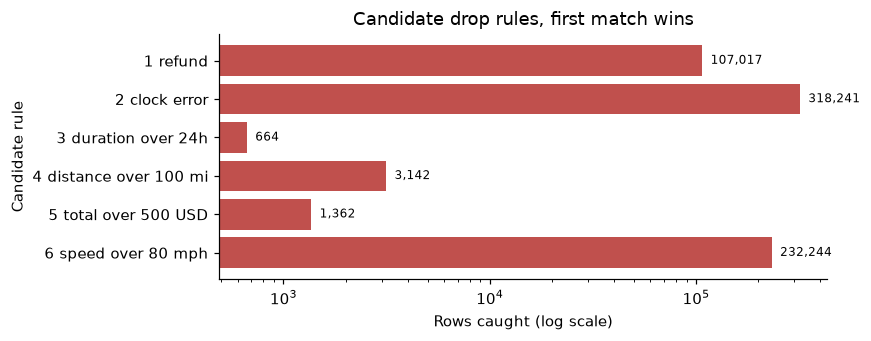

In [6]:
flagged = drop_candidates.drop("kept")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(flagged.index[::-1], flagged["rows"][::-1], color="#c0504d")
ax.set_xscale("log")
ax.set_xlabel("Rows caught (log scale)")
ax.set_ylabel("Candidate rule")
ax.set_title("Candidate drop rules, first match wins")
for y, value in enumerate(flagged["rows"][::-1]):
    ax.text(value * 1.1, y, f"{value:,}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_drop_candidates.png", bbox_inches="tight")
plt.show()

The rule counts add up to the raw total, so the rules do not overlap and no row falls outside them. Together the candidates would delete about 2.5 per thousand of the data. Two candidates are much larger than the rest: clock errors (318,241) and speeds above 80 mph (232,244). Before deleting half a million rows, I wanted to understand what they are.

In the next table I looked at the rows that pass all six candidates and counted values that are suspicious but not impossible. The rows in this group are candidates for setting one value to NULL or adding a flag, not for deletion. To see how many rows a stricter threshold would catch, I also added a few narrow ranges (3–24 hours, 50–100 miles, \$250–500, 50–80 mph).

In [7]:
flag_candidates = con.execute("""
    SELECT
        COUNT(*) FILTER (WHERE trip_distance = 0)             AS "zero distance",
        COUNT(*) FILTER (WHERE passenger_count = 0)           AS "zero passengers",
        COUNT(*) FILTER (WHERE PULocationID = 264)            AS "pickup zone 264",
        COUNT(*) FILTER (WHERE PULocationID = 265)            AS "pickup zone 265",
        COUNT(*) FILTER (WHERE DOLocationID = 264)            AS "dropoff zone 264",
        COUNT(*) FILTER (WHERE DOLocationID = 265)            AS "dropoff zone 265",
        COUNT(*) FILTER (WHERE ABS(total_amount - (fare_amount + extra + mta_tax
            + tip_amount + tolls_amount + improvement_surcharge)) > 0.01) AS "amount mismatch",
        COUNT(*) FILTER (WHERE fare_amount < 2.5)             AS "fare below 2.50 USD",
        COUNT(*) FILTER (WHERE duration_s < 60)               AS "duration under 1 min",
        COUNT(*) FILTER (WHERE VendorID = 3)                  AS "VendorID 3",
        COUNT(*) FILTER (WHERE RatecodeID = 99)               AS "RatecodeID 99",
        COUNT(*) FILTER (WHERE payment_type = 5)              AS "payment_type 5",
        COUNT(*) FILTER (WHERE improvement_surcharge IS NULL) AS "surcharge null",
        COUNT(*) FILTER (WHERE duration_s > 10800)            AS "duration 3h to 24h",
        COUNT(*) FILTER (WHERE trip_distance > 50)            AS "distance 50 to 100 mi",
        COUNT(*) FILTER (WHERE total_amount > 250)            AS "total 250 to 500 USD",
        COUNT(*) FILTER (WHERE speed_mph > 50)                AS "speed 50 to 80 mph",
        COUNT(*)                                              AS "kept rows"
    FROM candidate_rules
    WHERE candidate_rule = 'kept'
""").df().T.rename(columns={0: "rows"})

flag_candidates["pct_of_kept"] = (100 * flag_candidates["rows"]
                                  / flag_candidates.loc["kept rows", "rows"]).round(3)
flag_candidates

,rows,pct_of_kept
zero distance,1323957,0.479
zero passengers,44080,0.016
pickup zone 264,4112610,1.487
pickup zone 265,146724,0.053
dropoff zone 264,3616041,1.308
dropoff zone 265,653577,0.236
amount mismatch,839894,0.304
fare below 2.50 USD,94538,0.034
duration under 1 min,1677448,0.607
VendorID 3,10282,0.004


Most groups are small, but four are too large to decide by intuition:
- Durations of 3–24 hours (365,037). In the EDA the 99th percentile was below one hour.
- Trips under one minute (1,677,448).
- Pickup zone 264 (4,112,610, about 1.5% of trips).
- Fares below the \$2.50 drop charge (94,538).

`RatecodeID 99` also stands out. In the EDA I counted 16,022 rows with this code, but only 4,735 of them pass all six candidates. Most rows with this code contain wrong values in other columns as well.

### 4.2 What do the suspect groups look like?

For each group I looked at the median trip and a few shares: zero distance, under one minute, cash payment, vendor 1 and standard rate. The last row is the reference for comparison: all rows that pass the candidates.

I computed these medians with `approx_quantile`, a fast estimate. It is good enough to see roughly where a group sits, but the estimate can change in the second decimal between runs. For that reason I rounded these medians in the text and did not use them in any calculation. It is not suitable for asking whether values follow an exact pattern (for example, whether fares are multiples of 50 cents). I learned this the hard way during exploration: an approximate median can be a number that does not exist in the data. So wherever a decision depends on an exact value, I used `quantile_disc`, which always returns an observed value.

In [8]:
SUSPECT_GROUPS = {
    "speed over 80 mph": "candidate_rule = '6 speed over 80 mph'",
    "speed 50 to 80 mph": "candidate_rule = 'kept' AND speed_mph > 50",
    "duration 3h to 24h": "candidate_rule = 'kept' AND duration_s > 10800",
    "duration under 1 min": "candidate_rule = 'kept' AND duration_s < 60",
    "zero distance": "candidate_rule = 'kept' AND trip_distance = 0",
    "pickup zone 264": "candidate_rule = 'kept' AND PULocationID = 264",
    "fare below 2.50 USD": "candidate_rule = 'kept' AND fare_amount < 2.5",
    "reference: all kept": "candidate_rule = 'kept'",
}

profiles = []
for group, condition in SUSPECT_GROUPS.items():
    profiles.append(con.execute(f"""
        SELECT
            '{group}'                                                              AS grp,
            COUNT(*)                                                               AS rows,
            ROUND(approx_quantile(duration_s, 0.5) / 60.0, 1)                      AS median_minutes,
            ROUND(approx_quantile(trip_distance, 0.5), 2)                          AS median_miles,
            ROUND(approx_quantile(total_amount, 0.5), 2)                           AS median_total,
            ROUND(100.0 * COUNT(*) FILTER (WHERE trip_distance = 0) / COUNT(*), 1) AS zero_dist_pct,
            ROUND(100.0 * COUNT(*) FILTER (WHERE duration_s < 60) / COUNT(*), 1)   AS under_1min_pct,
            ROUND(100.0 * COUNT(*) FILTER (WHERE payment_type = 2) / COUNT(*), 1)  AS cash_pct,
            ROUND(100.0 * COUNT(*) FILTER (WHERE VendorID = 1) / COUNT(*), 1)      AS vendor1_pct,
            ROUND(100.0 * COUNT(*) FILTER (WHERE RatecodeID = 1) / COUNT(*), 1)    AS standard_rate_pct
        FROM candidate_rules
        WHERE {condition}
    """).df())

suspect_profiles = pd.concat(profiles).set_index("grp")
suspect_profiles

,rows,median_minutes,median_miles,median_total,zero_dist_pct,under_1min_pct,cash_pct,vendor1_pct,standard_rate_pct
grp,,,,,,,,,
speed over 80 mph,232244,0.3,2.57,4.45,0.0,90.6,32.3,90.4,59.9
speed 50 to 80 mph,66442,11.2,10.28,58.32,0.0,30.4,33.0,54.1,43.7
duration 3h to 24h,365037,1429.1,2.04,13.03,1.2,0.0,45.1,1.5,94.0
duration under 1 min,1677448,0.4,0.00,4.30,61.0,100.0,46.7,46.0,64.2
zero distance,1323957,0.3,0.00,7.36,100.0,77.3,37.1,55.3,55.6
pickup zone 264,4112610,10.3,1.57,11.87,6.0,6.8,35.6,68.3,93.6
fare below 2.50 USD,94538,2.0,0.20,0.31,40.8,33.7,51.7,85.5,11.9
reference: all kept,276508366,11.2,1.71,11.93,0.5,0.6,35.3,47.0,97.3


Three things stand out.

A speed above 80 mph does not mean fast driving. The median trip lasts 0.3 minutes and 90.6% of these trips are under one minute. The median distance is about 2.6 miles, but the median total is only about \$4.50. That is far too little for a 2.5-mile trip. Duration and fare agree with each other and describe a very short trip, while the distance agrees with neither. The working hypothesis I drew from this: **the wrong value is the distance.** I tested this hypothesis in 4.3.

The median of the 3–24 hour durations is about 1,430 minutes, just under 24 hours. Yet the median distance (about 2 miles) and the median total (about \$13) describe an ordinary short trip. A meter left running for a day would have charged hundreds of dollars in waiting time. Here the fare looks normal and the duration does not.

Errors cluster by vendor. In the reference row, vendor 1 makes up 47% of trips. In contrast, 90.4% of the above-80-mph group, 85.5% of fares below \$2.50 and 68.3% of zone 264 belong to vendor 1. Long durations go the other way: only 1.5% of them come from vendor 1, so almost all come from vendor 2. Each error type belongs largely to one vendor's recording system. For modelling, this means `VendorID` has to stay in the matrix as a control variable. Otherwise a model can learn "anomaly = vendor".

In the next two cells I looked more closely at the long durations and at zone 264.

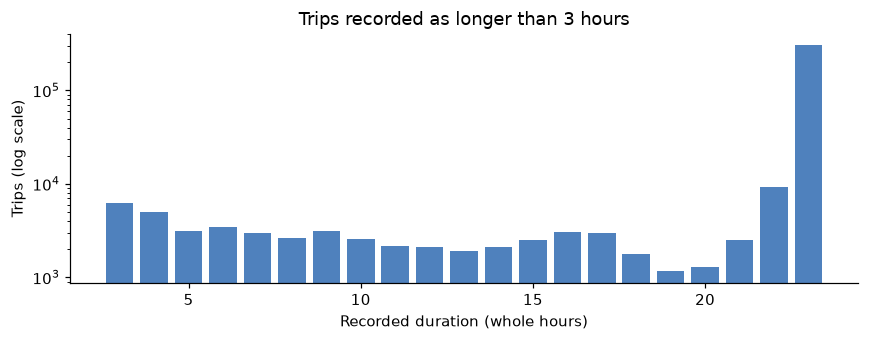

In [9]:
long_durations = con.execute("""
    SELECT
        CAST(FLOOR(duration_s / 3600) AS INTEGER)       AS duration_hours,
        COUNT(*)                                        AS rows,
        ROUND(approx_quantile(trip_distance, 0.5), 2)   AS median_miles,
        ROUND(approx_quantile(total_amount, 0.5), 2)    AS median_total
    FROM candidate_rules
    WHERE candidate_rule = 'kept' AND duration_s > 10800
    GROUP BY 1 ORDER BY 1
""").df().set_index("duration_hours")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(long_durations.index, long_durations["rows"], color="#4f81bd")
ax.set_yscale("log")
ax.set_xlabel("Recorded duration (whole hours)")
ax.set_ylabel("Trips (log scale)")
ax.set_title("Trips recorded as longer than 3 hours")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_long_durations.png", bbox_inches="tight")
plt.show()

In [10]:
long_durations

,rows,median_miles,median_total
duration_hours,,,
3,6319,10.03,46.92
4,5058,1.59,17.87
5,3149,3.42,19.08
6,3480,3.03,17.87
7,3017,3.99,21.47
8,2608,4.28,21.48
9,3155,3.74,19.79
10,2542,3.03,17.20
11,2171,3.26,18.49


Long durations are not scattered. 302,914 of the 365,037 rows (83%) sit in the 23-hour bucket, and their median distance and median total look like an ordinary short city trip.

The 3-hour bucket behaves differently. A distance of about 10 miles and a median total of \$47 describe a real long trip, such as an airport run in heavy traffic. From 4 hours on, the median distance drops to about 3 miles and the median total to about \$18. In other words, the fare no longer reflects the duration. What separates plausible durations from implausible ones was not a statistical cut-off but this consistency between fare and duration. The consistency points to a threshold of 4 hours. I tested the threshold in 4.3.

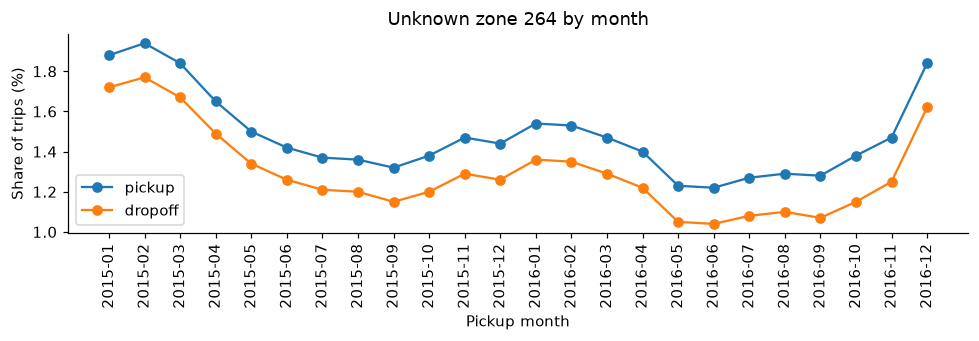

In [11]:
zone_264_by_month = con.execute("""
    SELECT
        strftime(tpep_pickup_datetime, '%Y-%m')                                  AS month,
        ROUND(100.0 * COUNT(*) FILTER (WHERE PULocationID = 264) / COUNT(*), 2)  AS pickup_264_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE DOLocationID = 264) / COUNT(*), 2)  AS dropoff_264_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE PULocationID = 264 AND VendorID = 1)
              / NULLIF(COUNT(*) FILTER (WHERE PULocationID = 264), 0), 1)        AS vendor1_share_of_264
    FROM candidate_rules
    WHERE candidate_rule = 'kept'
    GROUP BY 1 ORDER BY 1
""").df().set_index("month")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(zone_264_by_month.index, zone_264_by_month["pickup_264_pct"], marker="o", label="pickup")
ax.plot(zone_264_by_month.index, zone_264_by_month["dropoff_264_pct"], marker="o", label="dropoff")
ax.set_xlabel("Pickup month")
ax.set_ylabel("Share of trips (%)")
ax.set_title("Unknown zone 264 by month")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "04_zone_264_by_month.png", bbox_inches="tight")
plt.show()

Zone 264 appears every month, with a share of 1.2% to 1.9% of pickups. There is no break at TLC's mid-2016 schema change. The share rises in winter and falls in summer, but the data does not show why. For now I left this as a hypothesis. What matters for cleaning is the profile above: these trips have a normal duration, distance and fare. **The location is unknown, but the trip is real.** I kept these rows. I decided how to encode the unknown zone in Section 7.

### 4.3 Hypothesis tests

Test 1: Is the wrong value in trips above 80 mph the distance?
If so, the fares of these trips should look like other trips under one minute, not like trips with the same recorded distance. To see this I compared three groups: trips above 80 mph, other trips under one minute that did move, and normal 2–3 mile trips.

Test 2: Are the 23-hour trips real trips with a wrong dropoff timestamp value?
If a day was accidentally added to the dropoff time, two things should hold. First, the dropoff clock time should usually appear earlier than the pickup clock time. Second, removing the extra day should give a duration close to that of a normal trip of the same distance. To see this, I added a reference group of 1.8–2.1 mile trips to the comparison.

Both tests compare medians and the decision depends on exact values such as \$2.50. That is why these tables use `quantile_disc`.

Decision rules I wrote before the tests:
- If fares above 80 mph look like trips under one minute, I keep the rows and set the distance value to NULL.
- If the fare and distance of the 23-hour trips are normal, the timestamp value is wrong but the trip is real.
- If removing a day also gives the reference duration, I correct the timestamp. If it does not, I set the duration to NULL instead of guessing a value.

In [12]:
COMPARISON_GROUPS = {
    "speed over 80 mph": "candidate_rule = '6 speed over 80 mph'",
    "kept, under 1 min, moving": "candidate_rule = 'kept' AND duration_s < 60 AND trip_distance > 0",
    "kept, 2 to 3 miles": "candidate_rule = 'kept' AND trip_distance BETWEEN 2 AND 3 AND duration_s < 10800",
    "kept, 1.8 to 2.1 miles": "candidate_rule = 'kept' AND trip_distance BETWEEN 1.8 AND 2.1 AND duration_s < 10800",
}

comparisons = []
for group, condition in COMPARISON_GROUPS.items():
    comparisons.append(con.execute(f"""
        SELECT
            '{group}'                                          AS grp,
            COUNT(*)                                           AS rows,
            ROUND(quantile_disc(duration_s, 0.5) / 60.0, 1)    AS median_minutes,
            quantile_disc(trip_distance, 0.5)                  AS median_miles,
            quantile_disc(fare_amount, 0.5)                    AS median_fare
        FROM candidate_rules
        WHERE {condition}
    """).df())

pd.concat(comparisons).set_index("grp")

,rows,median_minutes,median_miles,median_fare
grp,,,,
speed over 80 mph,232244,0.3,2.60,2.5
"kept, under 1 min, moving",654309,0.7,0.11,3.0
"kept, 2 to 3 miles",46324669,13.8,2.40,11.5
"kept, 1.8 to 2.1 miles",23083520,11.8,1.93,10.0


In [13]:
day_shift_test = con.execute("""
    SELECT
        CAST(FLOOR(duration_s / 3600) AS INTEGER)                          AS duration_hours,
        COUNT(*)                                                           AS rows,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE CAST(tpep_dropoff_datetime AS TIME)
                < CAST(tpep_pickup_datetime AS TIME)) / COUNT(*), 1)       AS dropoff_clock_earlier_pct,
        ROUND(quantile_disc((86400 - duration_s) / 60.0, 0.5), 1)          AS median_minutes_if_shifted,
        quantile_disc(trip_distance, 0.5)                                  AS median_miles,
        quantile_disc(fare_amount, 0.5)                                    AS median_fare
    FROM candidate_rules
    WHERE candidate_rule = 'kept' AND duration_s > 14400
    GROUP BY 1 ORDER BY 1
""").df().set_index("duration_hours")

day_shift_test

,rows,dropoff_clock_earlier_pct,median_minutes_if_shifted,median_miles,median_fare
duration_hours,,,,,
4,3450,68.9,1171.9,5.44,21.5
5,3149,85.7,1109.4,3.41,16.5
6,3480,91.8,1050.0,3.00,15.0
7,3017,88.5,991.5,4.00,18.5
8,2608,96.3,930.0,4.27,19.0
9,3155,98.3,869.8,3.73,18.0
10,2542,98.3,813.2,3.04,15.0
11,2171,98.1,749.7,3.26,16.5
12,2104,98.0,690.6,3.15,15.0


Test 1 confirmed the hypothesis. The median fare of trips above 80 mph is \$2.50, exactly the meter's drop charge. That matches trips under one minute (\$3.00) and is far from normal 2–3 mile trips (\$11.50). The meter charged for a trip that barely moved, so the recorded distance value is wrong. **I kept the rows and set only `trip_distance` to NULL.**

Test 2 was only partly confirmed. In the 23-hour bucket, 98.8% of dropoff clock times are earlier than the pickup. Distance (about 1.9 miles) and fare (about \$10.50) match the 1.8–2.1 mile reference (about 12 minutes, \$10.00). So the trips are real and the timestamp value is wrong. But removing one day gives a median of about 7.5 minutes, not about 12. The error is not a clean one-day shift. Dropoff also falls before pickup, so a one-day correction would even produce negative durations. **I did not correct the timestamp; I set the duration to NULL.** A correction I cannot verify would turn noise into data that looks reliable.

The same pattern holds from 4 hours on: in 69–99% of the rows the dropoff clock time appears before the pickup, and fares stay between \$12 and \$21. That is where I set the duration threshold: 4 hours.

Test 3: What are the fares below \$2.50?

In [14]:
low_fare_breakdown = con.execute("""
    SELECT
        RatecodeID,
        payment_type,
        COUNT(*)                                                             AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)                   AS pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE fare_amount = 0) / COUNT(*), 1) AS zero_fare_pct,
        quantile_disc(total_amount, 0.5)                                     AS median_total
    FROM candidate_rules
    WHERE candidate_rule = 'kept' AND fare_amount < 2.5
    GROUP BY 1, 2
    ORDER BY rows DESC
    LIMIT 10
""").df()

low_fare_breakdown

,RatecodeID,payment_type,rows,pct,zero_fare_pct,median_total
0,5,2,38093,40.3,47.2,0.31
1,5,3,28401,30.0,59.4,0.31
2,1,2,9265,9.8,19.8,2.30
3,5,1,8755,9.3,65.0,18.15
4,5,4,5529,5.8,60.5,0.31
5,1,1,1257,1.3,93.5,0.00
6,2,2,777,0.8,69.4,0.00
7,1,3,623,0.7,95.8,0.30
8,4,3,407,0.4,61.4,1.30
9,99,2,327,0.3,99.4,0.30


Most of these fares are not meter errors. About 85% are negotiated fares (`RatecodeID 5`). According to TLC's [data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf), `RatecodeID` is the final rate code in effect at the end of the trip: 1 standard rate, 2 JFK, 3 Newark, 4 Nassau or Westchester, 5 negotiated fare, 6 group ride. The same dictionary defines `fare_amount` as the time-and-distance fare calculated by the meter. On a negotiated trip the fare is not calculated by the meter, so a zero or very low value in this column is consistent with that definition. For cash, no-charge and disputed payments the median total is \$0.31, meaning only the fixed surcharges were recorded. The negotiated amount was never entered.

Negotiated fares paid by card behave differently. Their median totals are far above the fare, so the money was written to a component other than `fare_amount`. This matters for tips, because on these trips the tip column may actually contain the fare. For this reason the tip feature in Section 5 is limited to card payments on the standard and JFK rates.

`RatecodeID 99` shows up here too, almost always with a zero fare. This supports reading it as a marker of a faulty record rather than a real rate code. **I kept these rows and added a flag. I also defined a separate flag for `RatecodeID 99`.**

### 4.4 Clock errors: junk or real trips?

The largest candidate rule (318,241 rows where dropoff is at or before pickup) would delete the same kind of problem I decided to keep for the 23-hour rows. To avoid treating the same problem in two different ways, I first looked at what these rows are.

My decision rule was: if zero distance and a near-zero fare dominate, these rows are junk and should be deleted. If distance and fare look like a normal trip, they are treated like the 23-hour rows: the trip is kept and the duration is set to NULL.

In [15]:
clock_error_profile = con.execute("""
    SELECT
        CASE WHEN duration_s = 0 THEN 'zero duration' ELSE 'negative duration' END AS kind,
        COUNT(*)                                                                   AS rows,
        ROUND(100.0 * COUNT(*) FILTER (WHERE trip_distance = 0) / COUNT(*), 1)     AS zero_dist_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE fare_amount = 0) / COUNT(*), 1)       AS zero_fare_pct,
        quantile_disc(trip_distance, 0.5)                                          AS median_miles,
        quantile_disc(fare_amount, 0.5)                                            AS median_fare,
        ROUND(100.0 * COUNT(*) FILTER (WHERE VendorID = 1) / COUNT(*), 1)          AS vendor1_pct
    FROM candidate_rules
    WHERE candidate_rule = '2 clock error'
    GROUP BY 1
""").df().set_index("kind")

clock_error_profile

,rows,zero_dist_pct,zero_fare_pct,median_miles,median_fare,vendor1_pct
kind,,,,,,
negative duration,6097,1.0,0.3,3.0,13.0,100.0
zero duration,312144,96.8,4.1,0.0,7.0,96.7


The 6,097 rows with negative duration look like normal trips: median distance 3.0 miles, median fare \$13.00, and all of them belong to vendor 1. Here the rule gave a clear answer. **I kept these rows and set the duration to NULL.**

The 312,144 rows with zero duration fit neither side of the rule. The distance is almost always zero (96.8%), which looks like junk. But only 4.1% have a zero fare, which does not. Since the rule I wrote could not decide here, I ran one more test. If the meter ran, fares should move in 50-cent steps. If the fare was typed in by hand, it usually does not follow these steps.

In [16]:
zero_duration_rates = con.execute("""
    SELECT
        RatecodeID,
        payment_type,
        COUNT(*)                                                    AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)          AS pct,
        quantile_disc(fare_amount, 0.5)                             AS median_fare,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE fare_amount * 2 = FLOOR(fare_amount * 2)) / COUNT(*), 1) AS meter_step_pct
    FROM candidate_rules
    WHERE candidate_rule = '2 clock error' AND duration_s = 0
    GROUP BY 1, 2
    ORDER BY rows DESC
    LIMIT 8
""").df()

zero_duration_rates

,RatecodeID,payment_type,rows,pct,median_fare,meter_step_pct
0,1,2,264281,84.7,6.50,100.0
1,5,2,14848,4.8,0.00,95.5
2,2,2,11609,3.7,52.00,99.9
3,99,1,10072,3.2,15.35,16.0
4,1,1,3572,1.1,15.00,99.7
5,2,1,1821,0.6,52.00,99.8
6,5,1,1707,0.5,58.00,88.6
7,3,2,1483,0.5,20.00,99.5


84.7% of the zero-duration rows are standard-rate cash trips, and all of their fares are multiples of 50 cents. So the meter ran and charged a fare; only the duration and distance were not recorded. These records also belong almost entirely to vendor 1. **I kept these rows as well and set their duration and distance values to NULL.**

### 4.5 The principle behind the decisions so far

All the tests led to the same conclusion, and I wrote it down as a principle:

> **If a value in a money column is wrong, the row is deleted. If a value in a measurement column (duration, distance) is wrong, only that value becomes NULL and a flag records the reason.**

Money is the core of a trip record. If the amount charged is wrong, nothing in the row can be trusted. If only the duration or distance value is wrong, the zones, time, fare and payment still describe a real trip.

Under this principle three candidate rules were still open: durations over 24 hours, distances over 100 miles and totals over \$500. I checked the money columns of these rows in the same way. My decision rule: if the fare looks normal and follows the meter's 50-cent steps, the money value is correct and only the measurement becomes NULL. Otherwise the row is deleted.

In [17]:
money_sanity = con.execute("""
    SELECT
        CASE
            WHEN total_amount > 500     THEN 'total over 500 USD'
            WHEN duration_s > 86400     THEN 'duration over 24h'
            WHEN trip_distance > 100    THEN 'distance over 100 mi'
        END                                                          AS grp,
        COUNT(*)                                                     AS rows,
        quantile_disc(fare_amount, 0.5)                              AS median_fare,
        quantile_disc(total_amount, 0.5)                             AS median_total,
        quantile_disc(fare_amount, 0.99)                             AS p99_fare,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE fare_amount * 2 = FLOOR(fare_amount * 2)) / COUNT(*), 1) AS meter_step_pct
    FROM trips
    WHERE total_amount >= 0
      AND (total_amount > 500 OR duration_s > 86400 OR trip_distance > 100)
    GROUP BY 1
""").df().set_index("grp")

money_sanity

,rows,median_fare,median_total,p99_fare,meter_step_pct
grp,,,,,
duration over 24h,662,9.5,12.30,63.00,99.4
total over 500 USD,1581,500.0,700.31,338816.15,81.1
distance over 100 mi,3051,9.5,14.38,450.00,98.0


- Over 24 hours: median fare \$9.50, 99.4% of fares follow the meter steps. Because the money value is correct, I only set the duration to NULL.
- Over 100 miles: median fare \$9.50, 98.0% of fares follow the meter steps. Nobody travels 100 miles for \$9.50. Here too I only set the distance to NULL.
- Over \$500: the median fare is exactly \$500.00 and the 99th percentile is \$338,816. The money value is wrong. **I deleted these rows.**

### 4.6 Negative values, an unfiltered check

The first rule catches refunds, but a row with a positive total can still have a negative component. I counted the negative values in every numeric column among the rows that pass the money rules so far. I deliberately used no other filter in this check. During exploration an unrelated `WHERE value >= 0` condition had hidden three negative distances from me for several steps. Those three rows were enough to break a regression over 247 million trips.

In [18]:
MONEY_SURVIVORS = "total_amount BETWEEN 0 AND 500 AND improvement_surcharge IS NOT NULL"

negative_audit = con.execute(f"""
    SELECT
        COUNT(*) FILTER (WHERE trip_distance < 0)          AS trip_distance,
        COUNT(*) FILTER (WHERE fare_amount < 0)            AS fare_amount,
        COUNT(*) FILTER (WHERE extra < 0)                  AS extra,
        COUNT(*) FILTER (WHERE mta_tax < 0)                AS mta_tax,
        COUNT(*) FILTER (WHERE tip_amount < 0)             AS tip_amount,
        COUNT(*) FILTER (WHERE tolls_amount < 0)           AS tolls_amount,
        COUNT(*) FILTER (WHERE improvement_surcharge < 0)  AS improvement_surcharge,
        COUNT(*) FILTER (WHERE passenger_count < 0)        AS passenger_count
    FROM trips
    WHERE {MONEY_SURVIVORS}
""").df().T.rename(columns={0: "negative_rows"})
negative_audit

,negative_rows
trip_distance,3
fare_amount,7
extra,105
mta_tax,0
tip_amount,6
tolls_amount,3
improvement_surcharge,0
passenger_count,0


In [19]:
negative_distance_profile = con.execute(f"""
    SELECT
        COUNT(*)                                                         AS rows,
        MIN(trip_distance)                                               AS min_miles,
        quantile_disc(fare_amount, 0.5)                                  AS median_fare,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE fare_amount * 2 = FLOOR(fare_amount * 2)) / COUNT(*), 1) AS meter_step_pct
    FROM trips
    WHERE {MONEY_SURVIVORS} AND trip_distance < 0
""").df()
negative_distance_profile

,rows,min_miles,median_fare,meter_step_pct
0,3,-40840124.4,2.5,100.0


There are three negative distances. The smallest is about −40.8 million miles, while the fare is the meter's \$2.50. The money value is correct and the measurement value is wrong. Under the principle, I set these distances to NULL.

The negatives in `fare_amount`, `extra`, `tip_amount` and `tolls_amount` are money values. **I deleted these rows.** The principle already covered this case, so it did not add a new idea; it became the fourth deletion rule.

### 4.7 Final cleaning rules and reconciliation

The evidence above set all the cleaning thresholds. In the next cell I added the thresholds to `RULES`, wrote the subsection each one comes from next to it, and applied the rules to the data with the `clean` view. Every comment in the SQL points to the section that holds the evidence for that part.

In [20]:
RULES.update({
    "max_total_amount": 500,        # 4.5: money corrupt above this total
    "max_distance_miles": 100,      # 4.5: sound fare, broken distance
    "max_speed_mph": 80,            # 4.3: fare equals the drop charge, distance broken
    "max_duration_s": 4 * 3600,     # 4.2-4.3: fare stops reflecting time from 4 hours on
})

con.execute(f"""
    CREATE OR REPLACE VIEW clean AS
    SELECT
        t.* EXCLUDE (trip_distance, duration_s, speed_mph),
        -- raw values are kept so the quality flags can say why a value became NULL
        t.trip_distance                                   AS raw_trip_distance,
        t.duration_s                                      AS raw_duration_s,
        t.speed_mph                                       AS raw_speed_mph,
        -- 4.3-4.6: a broken distance becomes NULL, the trip stays
        CASE WHEN t.trip_distance <= 0
               OR t.trip_distance > {RULES['max_distance_miles']}
               OR t.speed_mph > {RULES['max_speed_mph']}
             THEN NULL ELSE t.trip_distance END           AS trip_distance,
        -- 4.3-4.5: a broken duration becomes NULL, the trip stays
        CASE WHEN t.duration_s <= 0 OR t.duration_s > {RULES['max_duration_s']}
             THEN NULL ELSE t.duration_s END              AS duration_s,
        pu_lookup.Zone                                    AS pu_zone,
        pu_lookup.Borough                                 AS pu_borough,
        do_lookup.Zone                                    AS do_zone,
        do_lookup.Borough                                 AS do_borough
    FROM trips AS t
    LEFT JOIN read_csv_auto('{ZONE_LOOKUP}') AS pu_lookup ON t.PULocationID = pu_lookup.LocationID
    LEFT JOIN read_csv_auto('{ZONE_LOOKUP}') AS do_lookup ON t.DOLocationID = do_lookup.LocationID
    -- 4.1, 4.5, 4.6: rows with corrupt or incomplete money fields are deleted
    WHERE t.total_amount BETWEEN 0 AND {RULES['max_total_amount']}
      AND t.improvement_surcharge IS NOT NULL
      AND t.fare_amount >= 0
      AND t.extra >= 0
      AND t.mta_tax >= 0
      AND t.tip_amount >= 0
      AND t.tolls_amount >= 0
      AND t.improvement_surcharge >= 0
""");

In [21]:
final_waterfall = con.execute(f"""
    SELECT
        CASE
            WHEN total_amount < 0                           THEN '1 refund'
            WHEN total_amount > {RULES['max_total_amount']} THEN '2 total over limit'
            WHEN improvement_surcharge IS NULL              THEN '3 surcharge missing'
            WHEN fare_amount < 0 OR extra < 0 OR mta_tax < 0 OR tip_amount < 0
              OR tolls_amount < 0 OR improvement_surcharge < 0 THEN '4 negative component'
            ELSE 'kept'
        END                                                  AS rule,
        COUNT(*)                                             AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 4)   AS pct
    FROM trips
    GROUP BY 1 ORDER BY 1
""").df().set_index("rule")

clean_rows = con.execute("SELECT COUNT(*) FROM clean").fetchone()[0]
assert final_waterfall["rows"].sum() == raw_rows
assert final_waterfall.loc["kept", "rows"] == clean_rows

pd.concat([final_waterfall,
           pd.DataFrame({"rows": [raw_rows - clean_rows, raw_rows],
                         "pct": [round(100 * (raw_rows - clean_rows) / raw_rows, 4), 100.0]},
                        index=["deleted (rules 1-4)", "raw total"])])

,rows,pct
1 refund,107017,0.0386
2 total over limit,1581,0.0006
3 surcharge missing,3,0.0000
4 negative component,121,0.0000
kept,277062314,99.9608
deleted (rules 1-4),108722,0.0392
raw total,277171036,100.0000


Of the six candidates, four deletion rules remained. Both `assert` checks passed: the rule counts add up to the raw total, and the rows marked `kept` are exactly the rows in the `clean` view. The deleted share is far below one per thousand.

Each part of the `clean` view's query corresponds to a decision in this section:

| In the SQL | Decision | Evidence |
|---|---|---|
| `total_amount BETWEEN 0 AND 500` | refunds and wrong total values are deleted | 4.1, 4.5 |
| `improvement_surcharge IS NOT NULL`, `fare_amount >= 0`, `extra >= 0` … | rows with a missing or negative money column are deleted | 4.6 |
| NULL if `trip_distance <= 0 OR trip_distance > 100 OR speed_mph > 80` | a wrong distance value becomes NULL, the trip stays | 4.3–4.6 |
| NULL if `duration_s <= 0 OR duration_s > 14400` | a wrong duration value becomes NULL, the trip stays | 4.3–4.5 |
| `raw_trip_distance`, `raw_duration_s`, `raw_speed_mph` | raw values are kept so the flags can show why a value became NULL | 5.5 |
| `pu_zone`, `pu_borough`, `do_zone`, `do_borough` | zone names are added from the TLC lookup table | 6.2, 7 |

Everything else stayed in the data, and every wrong measurement value was set to NULL for a specific reason. The next cell counts these reasons.

In [22]:
null_reasons = con.execute(f"""
    SELECT
        COUNT(*) FILTER (WHERE raw_trip_distance = 0)                          AS "distance: zero",
        COUNT(*) FILTER (WHERE raw_trip_distance < 0)                          AS "distance: negative",
        COUNT(*) FILTER (WHERE raw_trip_distance > {RULES['max_distance_miles']}) AS "distance: over limit",
        COUNT(*) FILTER (WHERE raw_trip_distance > 0
                           AND raw_trip_distance <= {RULES['max_distance_miles']}
                           AND raw_speed_mph > {RULES['max_speed_mph']})       AS "distance: implied speed over limit",
        COUNT(*) FILTER (WHERE raw_duration_s = 0)                             AS "duration: zero",
        COUNT(*) FILTER (WHERE raw_duration_s < 0)                             AS "duration: negative",
        COUNT(*) FILTER (WHERE raw_duration_s > {RULES['max_duration_s']})     AS "duration: over limit",
        COUNT(*) FILTER (WHERE trip_distance IS NULL)                          AS "distance NULL total",
        COUNT(*) FILTER (WHERE duration_s IS NULL)                             AS "duration NULL total"
    FROM clean
""").df().T.rename(columns={0: "rows"})

null_reasons["pct_of_clean"] = (100 * null_reasons["rows"] / clean_rows).round(3)
null_reasons

,rows,pct_of_clean
distance: zero,1625994,0.587
distance: negative,3,0.000
distance: over limit,3048,0.001
distance: implied speed over limit,232240,0.084
duration: zero,312052,0.113
duration: negative,6097,0.002
duration: over limit,357873,0.129
distance NULL total,1861285,0.672
duration NULL total,676022,0.244


The reasons add up to the NULL counts: 1,861,285 distances (0.67% of clean rows) and 676,022 durations (0.24%). The two largest reasons are zero distance (1.6 million) and trips under one minute whose computed speed exceeds 80 mph (232,240). Every NULL in `trip_distance` and `duration_s` has a recorded reason. In Section 5 I turned these reasons into flag columns (`is_distance_missing`, `is_distance_invalid`, `is_duration_invalid`).

### 4.8 Fit window and holdout

From here on, every statistic I compute from the data (zone frequencies, median speeds, tariff coefficients, scaler parameters) becomes part of the feature pipeline. If these statistics see the holdout period, every evaluation on the holdout is contaminated. The EDA also showed that the data drifts over time, so a random split would mix periods that behave differently. I therefore split the data by time: the first 18 months fit the pipeline and the last 6 months were set aside as the holdout.

Below I defined the `enriched` view. It adds the helper columns that all later queries use to the cleaned data: speed (distance / duration), pickup hour, weekend flag, whether the row is in the fit window, and the trip segment derived from the zones. I justified the segment rule and its order in 6.2. The cell after that shows the size of the two periods.

In [23]:
RULES["fit_end"] = "2016-07-01"   # 4.8: first 18 months fit, last 6 months held out

con.execute(f"""
    CREATE OR REPLACE VIEW enriched AS
    SELECT
        *,
        trip_distance / (duration_s / 3600.0)          AS speed_mph,
        hour(tpep_pickup_datetime)                      AS pickup_hour,
        dayofweek(tpep_pickup_datetime) IN (0, 6)       AS is_weekend,
        tpep_pickup_datetime < '{RULES['fit_end']}'     AS in_fit_window,
        -- 6.2: segment from the zones, airports first
        CASE
            WHEN 'JFK Airport' IN (pu_zone, do_zone)       THEN 'jfk'
            WHEN 'LaGuardia Airport' IN (pu_zone, do_zone) THEN 'lga'
            WHEN 'Newark Airport' IN (pu_zone, do_zone)    THEN 'ewr'
            WHEN 265 IN (PULocationID, DOLocationID)       THEN 'outside_nyc'
            WHEN 264 IN (PULocationID, DOLocationID)       THEN 'unknown'
            ELSE 'city'
        END                                             AS trip_segment
    FROM clean
""");

In [24]:
fit_split = con.execute("""
    SELECT
        CASE WHEN in_fit_window THEN 'fit (2015-01 to 2016-06)'
             ELSE 'holdout (2016-07 to 2016-12)' END          AS period,
        COUNT(*)                                             AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)   AS pct
    FROM enriched
    GROUP BY 1 ORDER BY 1
""").df().set_index("period")

fit_split

,rows,pct
period,,
fit (2015-01 to 2016-06),215335294,77.7
holdout (2016-07 to 2016-12),61727020,22.3


The fit window holds about 78% of the clean rows and the holdout about 22%. The holdout covers a full half year, including the year-end slowdown seen in the EDA, and is large enough to measure drift. I computed every statistic that enters a feature value only from `in_fit_window` rows.

To summarise Section 4: I counted NULL, zero and negative values in the raw data (4.0), examined every suspect group and tested hypotheses (4.1–4.6), and turned the results into four deletion rules and one principle (4.7). Every deleted row was counted, the reason for every NULL was recorded, and the SQL that applies the rules is visible in the notebook. The `enriched` view is the clean base for all features.

## 5. Trip features

In this section I derived the features that describe a completed trip: price, tip, toll, surcharge and quality flags. Most of them are known only at dropoff, and Section 11 labels them that way.

I made a distinction about which data I used. How the meter works (tariff steps, surcharge hours, holiday behaviour) is a property of the taxi system, not a learned parameter. I checked these against all clean data. Every number that goes into a feature value (tariff coefficients, medians, frequencies) comes only from the fit window.

### 5.1 Price: from fare per mile to fare excess

The first price feature that comes to mind is fare per mile. Before using it, I looked at how it behaves at different distances for standard-rate trips.

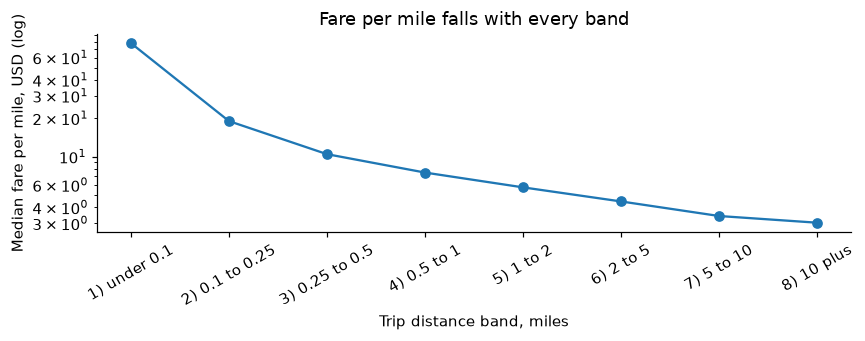

In [25]:
fare_by_distance = con.execute("""
    SELECT
        CASE
            WHEN trip_distance < 0.1  THEN '1) under 0.1'
            WHEN trip_distance < 0.25 THEN '2) 0.1 to 0.25'
            WHEN trip_distance < 0.5  THEN '3) 0.25 to 0.5'
            WHEN trip_distance < 1    THEN '4) 0.5 to 1'
            WHEN trip_distance < 2    THEN '5) 1 to 2'
            WHEN trip_distance < 5    THEN '6) 2 to 5'
            WHEN trip_distance < 10   THEN '7) 5 to 10'
            ELSE '8) 10 plus'
        END                                                           AS distance_band,
        COUNT(*)                                                      AS rows,
        ROUND(approx_quantile(fare_amount, 0.5), 2)                   AS median_fare,
        ROUND(approx_quantile(fare_amount / trip_distance, 0.5), 2)   AS median_fare_per_mile
    FROM enriched
    WHERE trip_distance IS NOT NULL AND RatecodeID = 1
    GROUP BY 1 ORDER BY 1
""").df().set_index("distance_band")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(fare_by_distance.index, fare_by_distance["median_fare_per_mile"], marker="o")
ax.set_yscale("log")
ax.set_ylabel("Median fare per mile, USD (log)")
ax.set_xlabel("Trip distance band, miles")
ax.set_title("Fare per mile falls with every band")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_fare_per_mile_by_distance.png", bbox_inches="tight")
plt.show()

In [26]:
fare_by_distance

,rows,median_fare,median_fare_per_mile
distance_band,,,
1) under 0.1,295641,2.50,77.82
2) 0.1 to 0.25,1457307,3.50,19.01
3) 0.25 to 0.5,8859111,4.00,10.46
4) 0.5 to 1,52085313,5.50,7.50
5) 1 to 2,92260569,8.00,5.74
6) 2 to 5,79802470,13.00,4.45
7) 5 to 10,24243500,23.68,3.42
8) 10 plus,9441375,37.50,3.03


Fare per mile falls in every distance band: from about \$78 per mile below 0.1 miles to about \$3 above 10 miles, and it never levels off. The \$2.50 drop charge is spread over fewer miles on short trips, so this ratio does not measure price; it mostly measures distance in reverse. No distance floor fixes that. **I dropped the idea of a `fare_per_mile` feature.**

I found a better idea. The meter follows a published formula: a drop charge plus a charge per mile, with waiting time charged instead of distance in slow traffic. If I can recover this formula from the data, the part of the fare the formula cannot explain gives the time and traffic component. A negative remainder means the trip was charged less than its distance requires.

On fast trips the meter charges almost no time, so the fare should be almost a straight line in distance. On slow trips it should not. I fitted both on the fit window. I computed the slope and intercept from their definitions (covariance / variance) rather than with a library call, so the result can be checked by hand.

In [27]:
tariff_by_speed = con.execute("""
    SELECT
        CASE WHEN speed_mph > 20 THEN 'fast (over 20 mph)'
             ELSE 'slow (20 mph or less)' END            AS speed_class,
        COUNT(*)                                         AS rows,
        corr(fare_amount, trip_distance)                 AS pearson,
        covar_pop(fare_amount, trip_distance)            AS covariance,
        var_pop(trip_distance)                           AS distance_variance,
        AVG(trip_distance)                               AS mean_miles,
        AVG(fare_amount)                                 AS mean_fare
    FROM enriched
    WHERE in_fit_window AND RatecodeID = 1 AND speed_mph IS NOT NULL
    GROUP BY 1
""").df().set_index("speed_class")

tariff_by_speed["usd_per_mile"] = tariff_by_speed["covariance"] / tariff_by_speed["distance_variance"]
tariff_by_speed["intercept_usd"] = (tariff_by_speed["mean_fare"]
                                    - tariff_by_speed["usd_per_mile"] * tariff_by_speed["mean_miles"])
tariff_by_speed[["rows", "pearson", "intercept_usd", "usd_per_mile"]].round(3)

,rows,pearson,intercept_usd,usd_per_mile
speed_class,,,,
slow (20 mph or less),191570477,0.946,3.841,3.19
fast (over 20 mph),16927164,0.994,2.619,2.70


On fast trips the fit is almost perfect: intercept about \$2.60, slope about \$2.70 per mile, and a correlation close to 0.99. These values match the published meter tariff (\$2.50 plus \$2.50 per mile) plus a small waiting charge that even fast trips collect at traffic lights. On slow trips both intercept and slope are higher and the fit is looser, so the time charge shows up here. The new feature measures exactly this difference.

Below I computed the coefficients of the fast trips from the fit window and made this definition:

> `fare_excess = fare_amount − (intercept + slope × trip_distance)`

This feature is defined only for standard-rate trips with a valid distance. The JFK flat fare and negotiated fares follow other rules, so they are NULL on those trips.

In [28]:
RULES["tariff_min_speed_mph"] = 20   # 5.1: above this speed the meter bills distance, not time

# Exact DECIMAL sums: floating-point sums change with the order in which threads combine them
distance = "CAST(trip_distance AS DECIMAL(18, 2))"
fare = "CAST(fare_amount AS DECIMAL(18, 2))"
n, sum_x, sum_y, sum_xx, sum_xy, sum_yy = con.execute(f"""
    SELECT
        COUNT(*),
        SUM({distance}),
        SUM({fare}),
        SUM({distance} * {distance}),
        SUM({distance} * {fare}),
        SUM({fare} * {fare})
    FROM enriched
    WHERE in_fit_window AND RatecodeID = 1 AND speed_mph > {RULES['tariff_min_speed_mph']}
""").fetchone()

covariance = n * sum_xy - sum_x * sum_y
distance_variance = n * sum_xx - sum_x * sum_x
fare_variance = n * sum_yy - sum_y * sum_y
slope = covariance / distance_variance
intercept = (sum_y - slope * sum_x) / n

TARIFF = {
    "rows": int(n),
    "intercept": float(intercept),
    "slope": float(slope),
    "r2": float(covariance * covariance / (distance_variance * fare_variance)),
}
print(f"fare = {TARIFF['intercept']:.3f} + {TARIFF['slope']:.3f} x miles   "
      f"(R^2 {TARIFF['r2']:.3f}, {TARIFF['rows']:,} fit-window trips)")

fare = 2.619 + 2.700 x miles   (R^2 0.988, 16,927,164 fit-window trips)


I computed the sums with exact `DECIMAL` arithmetic instead of floats. Float sums change in the last digits depending on the order in which parallel threads combine their partial results. That produced slightly different coefficients, and therefore a slightly different matrix, on every run (10.3).

### 5.2 Tip rate

The EDA showed that tips are recorded only for card payments, and 4.3 showed that on negotiated card payments the fare can be written to the tip column. I therefore defined `tip_rate = tip_amount / fare_amount` only for card payments on the standard or JFK rate with a fare of at least the drop charge. On other trips this value is NULL, not zero. A zero would tell the model that cash passengers never tip.

Before choosing an upper limit, I looked at how many tips exceed the fare.

In [29]:
tip_tail = con.execute("""
    WITH card AS (
        SELECT tip_amount, fare_amount, tip_amount / fare_amount AS tip_rate
        FROM enriched
        WHERE payment_type = 1 AND RatecodeID IN (1, 2) AND fare_amount >= 2.5
    )
    SELECT
        COUNT(*)                                                                  AS card_trips,
        COUNT(*) FILTER (WHERE tip_rate > 0.5)                                    AS over_50pct,
        COUNT(*) FILTER (WHERE tip_rate > 1)                                      AS over_100pct,
        COUNT(*) FILTER (WHERE tip_rate > 2)                                      AS over_200pct,
        quantile_disc(tip_amount, 0.5) FILTER (WHERE tip_rate > 1)                AS median_tip_over_100pct,
        quantile_disc(fare_amount, 0.5) FILTER (WHERE tip_rate > 1)               AS median_fare_over_100pct
    FROM card
""").df()

tip_tail

,card_trips,over_50pct,over_100pct,over_200pct,median_tip_over_100pct,median_fare_over_100pct
0,176633088,810396,219982,85862,10.0,4.5


On about 0.12% of the eligible card trips the tip exceeds the fare. The typical case is a round \$10 tip on a fare of a few dollars, which looks like generously rounding up a short trip. This behaviour may be real, but as a ratio it is extreme and would dominate every scaler. **I set an upper limit of 1.0 for `tip_rate`. Trips above this limit get the `is_tip_rate_extreme` flag.**

In [30]:
RULES.update({
    "min_fare": 2.5,       # 4.3 and 5.2: meter drop charge
    "tip_rate_cap": 1.0,   # 5.2: tips above the fare are capped and flagged
})

### 5.3 Toll

A toll is the charge paid when the trip crosses a tolled bridge or tunnel and is added to the passenger's bill. `tolls_amount` is zero on most trips and takes a few fixed values on the others. Fixed prices can change over time, so I checked the values month by month.

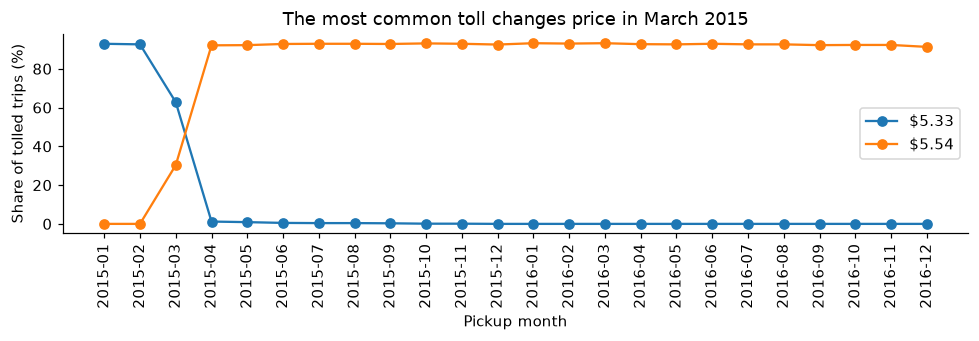

In [31]:
toll_prices = con.execute("""
    SELECT
        strftime(tpep_pickup_datetime, '%Y-%m')                                         AS month,
        ROUND(100.0 * COUNT(*) FILTER (WHERE tolls_amount > 0) / COUNT(*), 2)           AS has_toll_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE tolls_amount = 5.33)
              / NULLIF(COUNT(*) FILTER (WHERE tolls_amount > 0), 0), 1)                 AS toll_533_share,
        ROUND(100.0 * COUNT(*) FILTER (WHERE tolls_amount = 5.54)
              / NULLIF(COUNT(*) FILTER (WHERE tolls_amount > 0), 0), 1)                 AS toll_554_share
    FROM enriched
    GROUP BY 1 ORDER BY 1
""").df().set_index("month")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(toll_prices.index, toll_prices["toll_533_share"], marker="o", label="$5.33")
ax.plot(toll_prices.index, toll_prices["toll_554_share"], marker="o", label="$5.54")
ax.set_ylabel("Share of tolled trips (%)")
ax.set_xlabel("Pickup month")
ax.set_title("The most common toll changes price in March 2015")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_toll_prices.png", bbox_inches="tight")
plt.show()

In [32]:
toll_prices

,has_toll_pct,toll_533_share,toll_554_share
month,,,
2015-01,4.24,92.9,0.0
2015-02,4.43,92.6,0.0
2015-03,5.04,62.8,30.3
2015-04,5.07,1.2,92.1
2015-05,5.49,0.9,92.2
2015-06,5.33,0.5,92.8
2015-07,5.27,0.4,92.9
2015-08,5.47,0.4,92.9
2015-09,5.62,0.3,92.8


The most common toll rises from \$5.33 to \$5.54 in March 2015. Both prices appear in March; from April on only \$5.54 remains. The share of trips paying any toll stays between about 4% and 6% throughout. Had I used the raw amount, a model would read a price increase as a change in behaviour. **Instead of the raw amount I used a `has_toll` feature: did the trip pay a toll?**

### 5.4 Surcharge rule

The `extra` column contains the overnight and weekday peak surcharges. If the rule behind it can be recovered from the data, a trip whose surcharge breaks the rule is worth flagging. To find the rule, I looked at the share of each surcharge value by pickup hour.

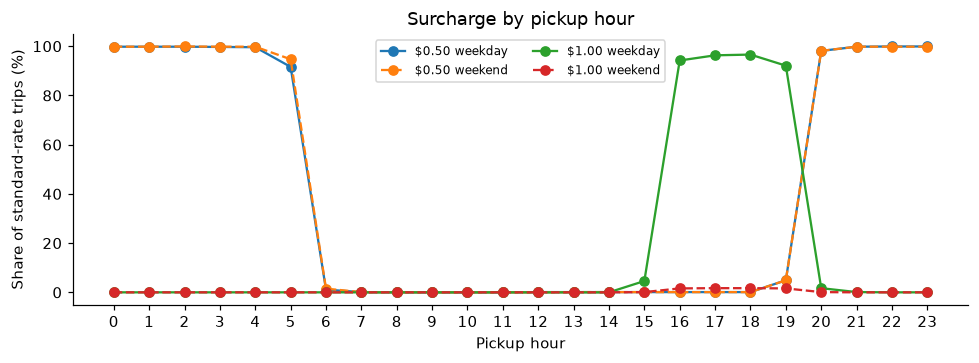

In [33]:
extra_by_hour = con.execute("""
    SELECT
        pickup_hour,
        CASE WHEN is_weekend THEN 'weekend' ELSE 'weekday' END              AS day_type,
        ROUND(100.0 * COUNT(*) FILTER (WHERE extra = 0.5) / COUNT(*), 1)     AS extra_050,
        ROUND(100.0 * COUNT(*) FILTER (WHERE extra = 1)   / COUNT(*), 1)     AS extra_100
    FROM enriched
    WHERE RatecodeID = 1
    GROUP BY 1, 2
""").df().pivot(index="pickup_hour", columns="day_type")

fig, ax = plt.subplots(figsize=(9, 3.4))
for (column, day_type), style in zip(extra_by_hour.columns, ["-", "--", "-", "--"]):
    label = f"{'$0.50' if column == 'extra_050' else '$1.00'} {day_type}"
    ax.plot(extra_by_hour.index, extra_by_hour[(column, day_type)], style, marker="o", label=label)
ax.set_xticks(range(24))
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Share of standard-rate trips (%)")
ax.set_title("Surcharge by pickup hour")
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_surcharge_by_hour.png", bbox_inches="tight")
plt.show()

In [34]:
extra_by_hour

extra_050         extra_100        
day_type      weekday weekend   weekday weekend
pickup_hour                                    
0                99.8    99.8       0.0     0.0
1                99.8    99.8       0.0     0.0
2                99.8    99.9       0.0     0.0
3                99.7    99.8       0.0     0.0
4                99.6    99.8       0.0     0.0
5                91.6    94.7       0.0     0.0
6                 1.1     1.5       0.0     0.0
7                 0.1     0.1       0.0     0.0
8                 0.0     0.0       0.0     0.0
9                 0.0     0.0       0.0     0.0
10                0.0     0.0       0.0     0.0
11                0.0     0.0       0.0     0.0
12                0.1     0.0       0.0     0.0
13                0.1     0.1       0.0     0.0
14                0.1     0.1       0.0     0.0
15                0.1     0.1       4.6     0.1
16                0.1     0.1      94.2     1.6
17                0.1     0.1      96.3     1.7
18                0.1     0.1      96.6     1.7
19                4.9     4.9      92.1     1.6
20               98.1    98.1       1.7     0.1
21               99.8    99.8       0.1     0.0
22               99.9    99.8       0.0     0.0
23               99.9    99.8       0.0     0.0

The rule is clearly visible:
- \$0.50 every day between 20:00 and 05:59. The share is above 99% in almost every hour of this range.
- \$1.00 on weekdays only, between 16:00 and 19:59. The share is around 92–97% on weekdays and below 2% at weekends.
- No surcharge at other hours.

At 05, 15 and 19 the table is not clear: about 4–8% of trips fall on the "wrong" side of the rule. These hours are the edges of the ranges. The meter's clock and the recorded pickup minute can fall on different sides of the boundary. I did not evaluate the surcharge in these hours.

Before trusting the rule, I looked for the answer to one more question: is the peak surcharge charged on weekday holidays? That needed a holiday calendar. I derived it from the US federal calendar in `pandas`. This calendar applies the holidays defined in 5 U.S.C. 6103 and published every year by the [U.S. Office of Personnel Management](https://www.opm.gov/policy-data-oversight/snow-dismissal-procedures/federal-holidays). Under the OPM rule a holiday falling on a weekend is observed on the Friday before or the Monday after, and `pandas` applies the same rule. In the same cell I also derived the DST transition days and the observed dates moved off a weekend.

In [35]:
from pandas.tseries.holiday import Holiday, USFederalHolidayCalendar

PERIOD_START, PERIOD_END = "2015-01-01", "2016-12-31"

federal_calendar = USFederalHolidayCalendar()
observed = federal_calendar.holidays(start=PERIOD_START, end=PERIOD_END, return_name=True)
holiday_dates = pd.DataFrame({"holiday_date": observed.index, "holiday_name": observed.values})

# Fixed-date holidays that the observance rule moved off a weekend
shifted = []
for rule in federal_calendar.rules:
    if rule.observance is None or rule.offset is not None or rule.month is None:
        continue
    nominal = Holiday(rule.name, month=rule.month, day=rule.day).dates(PERIOD_START, PERIOD_END)
    shifted.extend(sorted(set(rule.dates(PERIOD_START, PERIOD_END)) - set(nominal)))
tariff_ambiguous_dates = pd.DataFrame({"tariff_date": pd.to_datetime(shifted)})

# A day whose UTC offset changes within 23 hours is a DST transition day in New York
midnights = pd.date_range(PERIOD_START, PERIOD_END, freq="D", tz="America/New_York")
dst_dates = pd.DataFrame({"dst_date": pd.to_datetime(
    [day.tz_localize(None) for day in midnights
     if day.utcoffset() != (day + pd.Timedelta(hours=23)).utcoffset()])})

con.register("holiday_dates", holiday_dates)
con.register("tariff_ambiguous_dates", tariff_ambiguous_dates)
con.register("dst_dates", dst_dates)
CALENDARS = {"holidays": holiday_dates, "tariff_ambiguous": tariff_ambiguous_dates, "dst": dst_dates}

holiday_dates.assign(weekday=lambda d: d["holiday_date"].dt.day_name(),
                     shifted_off_weekend=lambda d: d["holiday_date"].isin(tariff_ambiguous_dates["tariff_date"]))

,holiday_date,holiday_name,weekday,shifted_off_weekend
0,2015-01-01,New Year's Day,Thursday,False
1,2015-01-19,"Birthday of Martin Luther King, Jr.",Monday,False
2,2015-02-16,Washington's Birthday,Monday,False
3,2015-05-25,Memorial Day,Monday,False
4,2015-07-03,Independence Day,Friday,True
5,2015-09-07,Labor Day,Monday,False
6,2015-10-12,Columbus Day,Monday,False
7,2015-11-11,Veterans Day,Wednesday,False
8,2015-11-26,Thanksgiving Day,Thursday,False
9,2015-12-25,Christmas Day,Friday,False


In [36]:
peak_on_holidays = con.execute("""
    SELECT
        CASE WHEN h.holiday_date IS NOT NULL THEN 'federal holiday' ELSE 'regular weekday' END AS day_kind,
        COUNT(*)                                                                   AS trips,
        ROUND(100.0 * COUNT(*) FILTER (WHERE e.extra = 1) / COUNT(*), 1)          AS extra_100_pct
    FROM enriched AS e
    LEFT JOIN holiday_dates AS h
      ON CAST(e.tpep_pickup_datetime AS DATE) = CAST(h.holiday_date AS DATE)
    WHERE e.RatecodeID = 1 AND NOT e.is_weekend AND e.pickup_hour BETWEEN 16 AND 18
    GROUP BY 1
""").df().set_index("day_kind")
peak_on_holidays

,trips,extra_100_pct
day_kind,,
regular weekday,28689683,98.9
federal holiday,985863,7.2


In [37]:
peak_by_holiday_date = con.execute("""
    SELECT
        h.holiday_name,
        CAST(h.holiday_date AS DATE)                                       AS holiday_date,
        dayname(h.holiday_date)                                            AS weekday,
        COUNT(*)                                                           AS peak_trips,
        ROUND(100.0 * COUNT(*) FILTER (WHERE e.extra = 1) / COUNT(*), 1)   AS extra_100_pct
    FROM enriched AS e
    JOIN holiday_dates AS h
      ON CAST(e.tpep_pickup_datetime AS DATE) = CAST(h.holiday_date AS DATE)
    WHERE e.RatecodeID = 1 AND NOT e.is_weekend AND e.pickup_hour BETWEEN 16 AND 18
    GROUP BY 1, 2, 3
    ORDER BY extra_100_pct DESC
""").df().set_index(["holiday_name", "holiday_date"])
peak_by_holiday_date

weekday  peak_trips  \
holiday_name                        holiday_date                          
Independence Day                    2015-07-03       Friday       47091   
Christmas Day                       2016-12-26       Monday       38982   
New Year's Day                      2015-01-01     Thursday       50419   
                                    2016-01-01       Friday       45687   
Birthday of Martin Luther King, Jr. 2015-01-19       Monday       62063   
                                    2016-01-18       Monday       64393   
Washington's Birthday               2016-02-15       Monday       57335   
                                    2015-02-16       Monday       72034   
Memorial Day                        2015-05-25       Monday       53864   
                                    2016-05-30       Monday       47702   
Labor Day                           2015-09-07       Monday       50587   
Independence Day                    2016-07-04       Monday       40744   
Labor Day                           2016-09-05       Monday       41763   
Columbus Day                        2015-10-12       Monday       56119   
Thanksgiving Day                    2016-11-24     Thursday       33189   
Columbus Day                        2016-10-10       Monday       50559   
Thanksgiving Day                    2015-11-26     Thursday       34824   
Veterans Day                        2015-11-11    Wednesday       54795   
                                    2016-11-11       Friday       51053   
Christmas Day                       2015-12-25       Friday       32660   

                                                  extra_100_pct  
holiday_name                        holiday_date                 
Independence Day                    2015-07-03             31.1  
Christmas Day                       2016-12-26             27.0  
New Year's Day                      2015-01-01             11.4  
                                    2016-01-01              9.9  
Birthday of Martin Luther King, Jr. 2015-01-19              9.1  
                                    2016-01-18              8.8  
Washington's Birthday               2016-02-15              7.4  
                                    2015-02-16              7.4  
Memorial Day                        2015-05-25              4.6  
                                    2016-05-30              4.6  
Labor Day                           2015-09-07              3.4  
Independence Day                    2016-07-04              3.3  
Labor Day                           2016-09-05              2.7  
Columbus Day                        2015-10-12              2.7  
Thanksgiving Day                    2016-11-24              2.2  
Columbus Day                        2016-10-10              2.1  
Thanksgiving Day                    2015-11-26              2.0  
Veterans Day                        2015-11-11              1.7  
                                    2016-11-11              1.7  
Christmas Day                       2015-12-25              1.5

On regular weekdays, about 99% of standard-rate trips between 16:00 and 18:59 were charged the \$1.00 surcharge. On federal holidays the share is only about 7%. So holidays behave like weekends for the surcharge, and I built the rule accordingly. Without this correction the flag would have wrongly marked almost every peak-hour trip on a holiday.

The by-date table shows where the remaining 7% comes from. The two highest shares are on 2015-07-03 (31.1%) and 2016-12-26 (27.0%), exactly the two observed dates `pandas` moved off a weekend. OPM's own note explains the pattern: the shifted day is a holiday for federal employees' pay and leave purposes, not for everyone. On the actual holiday dates the share ranges from 1.5% to 11.4%. The highest shares fall on the first holidays of the year, such as New Year's Day, Martin Luther King Day and Washington's Birthday, and the share falls as the year goes on. To see whether both patterns come from the meters, I split the shares by vendor.

In [38]:
peak_by_vendor = con.execute("""
    SELECT
        CAST(h.holiday_date AS DATE)                                                AS holiday_date,
        h.holiday_name,
        ROUND(100.0 * COUNT(*) FILTER (WHERE e.extra = 1 AND e.VendorID = 1)
              / NULLIF(COUNT(*) FILTER (WHERE e.VendorID = 1), 0), 1)               AS vendor_1_extra_100_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE e.extra = 1 AND e.VendorID = 2)
              / NULLIF(COUNT(*) FILTER (WHERE e.VendorID = 2), 0), 1)               AS vendor_2_extra_100_pct
    FROM enriched AS e
    JOIN holiday_dates AS h
      ON CAST(e.tpep_pickup_datetime AS DATE) = CAST(h.holiday_date AS DATE)
    WHERE e.RatecodeID = 1 AND NOT e.is_weekend AND e.pickup_hour BETWEEN 16 AND 18
    GROUP BY 1, 2
    ORDER BY 1
""").df().set_index("holiday_date")
peak_by_vendor

,holiday_name,vendor_1_extra_100_pct,vendor_2_extra_100_pct
holiday_date,,,
2015-01-01,New Year's Day,3.0,17.9
2015-01-19,"Birthday of Martin Luther King, Jr.",1.7,15.1
2015-02-16,Washington's Birthday,2.2,11.6
2015-05-25,Memorial Day,2.1,6.7
2015-07-03,Independence Day,60.5,6.2
2015-09-07,Labor Day,1.5,5.0
2015-10-12,Columbus Day,1.6,3.7
2015-11-11,Veterans Day,0.5,2.8
2015-11-26,Thanksgiving Day,1.2,2.6


The vendor split ties both patterns to the meters. On the two shifted observed dates, the share of peak-hour trips charged the surcharge is 60.5% and 60.7% for vendor 1, and 6.2% and 0.7% for vendor 2. So most of vendor 1's meters charge the shifted day like a workday, while vendor 2's meters almost all treat it as a holiday. The high shares on the first holidays of the year also come from a single vendor, and that vendor changes from year to year. On the January holidays of 2015 the share is high for vendor 2 (15.1% to 17.9%), on those of 2016 for vendor 1 (18.0% to 20.0%). The lagging vendor's share falls through the year: to 1.7% for vendor 2 on Christmas 2015, and to 3.0% for vendor 1 on Veterans Day 2016. I noted this as an unverified hypothesis: each vendor may update its meters' holiday table at a different time at the start of the year.

The two cases affect the rule differently. On actual holiday dates the rule is clear: no peak surcharge is charged. Trips charged the surcharge on those days break the rule, and the flag marks them. For an anomaly model this mark is a signal worth keeping. On the shifted observed dates, however, the two vendors contradict each other. Treating these days as holidays would mislabel about 30% of peak-hour trips, treating them as workdays about 70%. **I decided not to evaluate the peak surcharge rule on the shifted observed dates.** It is the same approach as for the boundary hours: where the rule itself is ambiguous in the data, the flag is not evaluated and stays NULL.

Before building the rule I tested one more assumption: is the meter's holiday calendar the same as the federal calendar? For every weekday that is not a federal holiday, I computed the share of peak-hour trips charged the \$1.00 surcharge. I wrote the decision rule before the test: a workday where this share falls below 50% counts as a day the meter treats as a holiday, and is added to the tariff calendar.

In [39]:
RULES["meter_holiday_max_peak_pct"] = 50   # 5.4: decision rule written before the test

peak_by_weekday = con.execute("""
    SELECT
        CAST(e.tpep_pickup_datetime AS DATE)                                 AS trip_date,
        dayname(e.tpep_pickup_datetime)                                      AS weekday,
        COUNT(*)                                                             AS peak_trips,
        ROUND(100.0 * COUNT(*) FILTER (WHERE e.extra = 1) / COUNT(*), 1)     AS extra_100_pct
    FROM enriched AS e
    LEFT JOIN holiday_dates AS h
      ON CAST(e.tpep_pickup_datetime AS DATE) = CAST(h.holiday_date AS DATE)
    WHERE e.RatecodeID = 1 AND NOT e.is_weekend AND e.pickup_hour BETWEEN 16 AND 18
      AND h.holiday_date IS NULL
    GROUP BY 1, 2
    ORDER BY extra_100_pct, trip_date
""").df()
peak_by_weekday.head(6)

,trip_date,weekday,peak_trips,extra_100_pct
0,2016-11-08,Tuesday,50533,2.1
1,2015-11-03,Tuesday,58095,2.3
2,2016-04-07,Thursday,59234,97.8
3,2016-05-09,Monday,59222,98.2
4,2016-08-11,Thursday,53591,98.4
5,2015-03-11,Wednesday,60740,98.7


In [40]:
peak_by_weekday["extra_100_pct"].describe().round(1)

count    502.0
mean      98.9
std        6.1
min        2.1
25%       99.2
50%       99.3
75%       99.3
max       99.6
Name: extra_100_pct, dtype: float64

Across the 502 workdays that are not federal holidays, the median surcharge share is 99.3%. Two days fall below the rule: 2015-11-03 (2.3%) and 2016-11-08 (2.1%). Both are US general election days, the Tuesday after the first Monday in November. The next lowest share is 97.8%, so there is a clear gap between the election days and normal workdays. The meters treat general election day as a holiday, while the federal calendar does not include it.

Following this finding I separated the two calendars. `is_holiday` stays the federal calendar, which the demand analysis in 6.1 also uses. The surcharge rule, however, should follow the meters' behaviour. For this I built a separate tariff calendar that adds general election day to the federal holidays. I did not type the election dates by hand; I derived them from their rule. In the same cell I checked that the derived dates are exactly the days below the rule in the data.

In [41]:
from dateutil.relativedelta import TU
from pandas.tseries.offsets import DateOffset

# General election day: the Tuesday after the first Monday in November
election_rule = Holiday("General Election Day", month=11, day=2, offset=DateOffset(weekday=TU(1)))
election_dates = election_rule.dates(PERIOD_START, PERIOD_END)

below_rule = pd.to_datetime(
    peak_by_weekday.loc[peak_by_weekday["extra_100_pct"] < RULES["meter_holiday_max_peak_pct"], "trip_date"])
assert set(below_rule.dt.strftime("%Y-%m-%d")) == set(election_dates.strftime("%Y-%m-%d")), \
    "Weekdays below the rule differ from the derived election days"

tariff_holiday_dates = (pd.concat([holiday_dates,
                                   pd.DataFrame({"holiday_date": election_dates,
                                                 "holiday_name": "General Election Day"})],
                                  ignore_index=True)
                        .sort_values("holiday_date", ignore_index=True))
con.register("tariff_holiday_dates", tariff_holiday_dates)
CALENDARS["tariff_holidays"] = tariff_holiday_dates

tariff_holiday_dates.assign(
    source=lambda d: d["holiday_name"].eq("General Election Day").map({True: "election day", False: "federal holiday"}))

,holiday_date,holiday_name,source
0,2015-01-01,New Year's Day,federal holiday
1,2015-01-19,"Birthday of Martin Luther King, Jr.",federal holiday
2,2015-02-16,Washington's Birthday,federal holiday
3,2015-05-25,Memorial Day,federal holiday
4,2015-07-03,Independence Day,federal holiday
5,2015-09-07,Labor Day,federal holiday
6,2015-10-12,Columbus Day,federal holiday
7,2015-11-03,General Election Day,election day
8,2015-11-11,Veterans Day,federal holiday
9,2015-11-26,Thanksgiving Day,federal holiday


In [42]:
RULES.update({
    "overnight_start": 20, "overnight_end": 6,   # 5.4: $0.50 window
    "peak_start": 16, "peak_end": 19,            # 5.4: $1.00 window, weekdays except tariff holidays
    "overnight_extra": 0.5, "peak_extra": 1.0,
    "boundary_hours": [5, 15, 19],               # 5.4: ambiguous edges of the windows
})

I derived two features from this rule:
- `tariff_period` (overnight, weekday_peak or standard), known at pickup. Instead of a hand-picked "rush hour", it uses the meters' own hours and the tariff calendar.
- `is_extra_mismatch`, known at dropoff, shows that the surcharge charged does not match the rule. It is evaluated only on standard-rate trips, outside the boundary hours and outside the peak hours of the shifted holidays.

I did not use the raw `extra` column as a feature, because it repeats the pickup hour and its useful part is already in these two features.

### 5.5 Quality flags

I turned every NULL from Section 4 and every suspicious but real pattern into a flag. Even after the value itself is removed, the flag keeps the information that the value was wrong. For an anomaly model the flags are also signals in their own right.

| Flag | Definition | Evidence |
|---|---|---|
| `is_distance_missing` | raw distance is zero | 4.2, 4.4 |
| `is_distance_invalid` | raw distance is negative, above 100 miles, or implies a speed above 80 mph | 4.3, 4.5, 4.6 |
| `is_duration_invalid` | raw duration is zero, negative or above 4 hours | 4.3, 4.4, 4.5 |
| `is_very_short` | trip under one minute | 4.1, 4.2 |
| `is_high_speed` | computed speed between 50 and 80 mph | 4.2 |
| `is_amount_mismatch` | components do not add up to the total | 4.1, EDA |
| `is_fare_below_minimum` | fare below the \$2.50 drop charge | 4.3 |
| `is_ratecode_invalid` | `RatecodeID = 99` | 4.1, 4.3 |
| `is_extra_mismatch` | surcharge does not match the rule | 5.4 |
| `is_tip_rate_extreme` | tip larger than the fare | 5.2 |

I defined the location flags (`is_zone_unknown`, `is_outside_nyc`) and the `is_route_ratio_undefined` flag in Section 6.

In [43]:
RULES.update({
    "very_short_s": 60,     # 4.1-4.2: sub-minute trips
    "high_speed_mph": 50,   # 4.2: plausible highway speeds up to the 80 mph limit
})

### 5.6 Columns I did not use as features

Three columns in the 4.0 table had also caught my attention: `mta_tax` and `improvement_surcharge` almost always take the same value, and `store_and_fwd_flag` seems related to the recording system rather than the trip. I had also identified the zeros in `passenger_count` as missing values in the EDA. Before taking these four columns into the model, I looked at what information they contain.

First I counted which values appear how often in the two fixed-fee columns. In the next cell I looked at which segments the zero values concentrate in.

In [44]:
fixed_fee_values = []
for column in ["mta_tax", "improvement_surcharge"]:
    fixed_fee_values.append(con.execute(f"""
        SELECT
            '{column}'                                          AS column_name,
            {column}                                            AS value,
            COUNT(*)                                            AS rows,
            ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)  AS pct
        FROM enriched
        GROUP BY 2
        ORDER BY rows DESC
        LIMIT 4
    """).df())
pd.concat(fixed_fee_values).set_index(["column_name", "value"])

rows    pct
column_name           value                  
mta_tax               0.50   275877931  99.57
                      0.00     1184097   0.43
                      1.74          62   0.00
                      0.35          25   0.00
improvement_surcharge 0.30   276297177  99.72
                      0.00      765121   0.28
                      0.60          15   0.00
                      0.70           1   0.00

In [45]:
fixed_fee_zeros = con.execute("""
    SELECT
        trip_segment,
        COUNT(*)                                                                      AS rows,
        ROUND(100.0 * COUNT(*) FILTER (WHERE mta_tax = 0) / COUNT(*), 2)              AS mta_tax_zero_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE improvement_surcharge = 0) / COUNT(*), 2) AS surcharge_zero_pct
    FROM enriched
    GROUP BY 1
    ORDER BY rows DESC
""").df().set_index("trip_segment")
fixed_fee_zeros

,rows,mta_tax_zero_pct,surcharge_zero_pct
trip_segment,,,
city,253459628,0.10,0.26
lga,9918978,0.44,0.24
jfk,8247335,0.86,0.31
unknown,4472253,2.28,1.02
outside_nyc,499299,52.77,0.80
ewr,464821,96.62,0.43


Both columns are almost constant: `mta_tax` is \$0.50 on more than 99% of trips and `improvement_surcharge` is \$0.30 on more than 99% as well. A value that is the same in almost every row adds no information to a model.

The zeros, however, are not random. Trips where `mta_tax` is zero concentrate in the Newark and outside-NYC segments. This is explained by the MTA tax being charged only within the city, so it is a business rule. That information is already in `trip_segment` and `is_outside_nyc`. Trips where `improvement_surcharge` is zero are spread across the segments. This is one of the cases where the total does not match its components, and the `is_amount_mismatch` flag catches it.

**I did not use `mta_tax` and `improvement_surcharge` as model features.** The little information they contain is already in other columns.

Next I looked at `store_and_fwd_flag` and `passenger_count`. `store_and_fwd_flag` shows that the meter stored the record while offline and sent it later. To see whether this is related to record quality, I compared the Y and N records. For `passenger_count` I computed the distribution by passenger count and the vendor share.

In [46]:
store_forward_profile = con.execute("""
    SELECT
        store_and_fwd_flag,
        COUNT(*)                                                                   AS rows,
        ROUND(100.0 * COUNT(*) FILTER (WHERE duration_s IS NULL) / COUNT(*), 2)    AS duration_null_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE trip_distance IS NULL) / COUNT(*), 2) AS distance_null_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE PULocationID = 264) / COUNT(*), 2)    AS pickup_264_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE VendorID = 1) / COUNT(*), 1)          AS vendor1_pct
    FROM enriched
    GROUP BY 1
""").df().set_index("store_and_fwd_flag")
store_forward_profile

,rows,duration_null_pct,distance_null_pct,pickup_264_pct,vendor1_pct
store_and_fwd_flag,,,,,
N,275100131,0.23,0.65,1.49,46.7
Y,1962183,2.14,3.55,3.23,100.0


In [47]:
passenger_profile = con.execute("""
    SELECT
        passenger_count,
        COUNT(*)                                                              AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3)                    AS pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE VendorID = 1) / COUNT(*), 1)     AS vendor1_pct,
        ROUND(approx_quantile(total_amount, 0.5), 1)                          AS median_total
    FROM enriched
    GROUP BY 1
    ORDER BY 1
""").df().set_index("passenger_count")
passenger_profile

,rows,pct,vendor1_pct,median_total
passenger_count,,,,
0,53973,0.019,91.2,11.8
1,195822893,70.678,53.8,11.8
2,39909032,14.404,45.0,12.3
3,11584122,4.181,39.6,12.2
4,5637894,2.035,44.2,12.3
5,14700361,5.306,0.5,12.1
6,9352550,3.376,0.3,11.9
7,584,0.000,20.9,70.3
8,486,0.000,6.6,80.8


All Y records come from vendor 1, and on these records duration and distance are NULL several times more often than on N records. So this column says more about the quality of the record than about the trip. As a model feature it would again let the model learn "anomaly = vendor" (4.2). **I kept it in the matrix as `is_store_forward`, as a control column that does not enter the model, like `VendorID`.**

In `passenger_count`, the median total stays between \$11.8 and \$12.3 for 1 to 6 passengers, so the passenger count does not change the fare noticeably. This confirms the very low correlation found in the EDA. For 7–9 passengers the median total rises to \$70–80, but these are only about 1,500 trips in total. Almost all trips with 5 or 6 passengers come from vendor 2, while 91% of zero-passenger records come from vendor 1. So besides the number of passengers, this column partly measures the vendor. **I set zero passengers to NULL as a missing value and kept `passenger_count` as a control column.** In 10.4 I checked that the zeros really became NULL.

## 6. Time and location features

### 6.1 Calendar

I had built the holiday and DST tables in 5.4. Here I checked whether they matter for demand. I did not type the four DST days by hand; I derived them from the New York time zone rules. The dates are the same four I found by eye in the EDA.

In [48]:
CALENDARS["dst"]

,dst_date
0,2015-03-08
1,2015-11-01
2,2016-03-13
3,2016-11-06


In [49]:
holiday_effect = con.execute("""
    WITH daily AS (
        SELECT CAST(tpep_pickup_datetime AS DATE) AS trip_date, COUNT(*) AS trips
        FROM enriched
        WHERE in_fit_window
        GROUP BY 1
    )
    SELECT
        CASE
            WHEN h.holiday_date IS NOT NULL         THEN 'federal holiday'
            WHEN dayofweek(d.trip_date) IN (0, 6)   THEN 'weekend'
            ELSE 'regular weekday'
        END                            AS day_kind,
        COUNT(*)                       AS days,
        ROUND(AVG(d.trips))            AS mean_trips,
        MIN(d.trips)                   AS min_trips,
        MAX(d.trips)                   AS max_trips
    FROM daily AS d
    LEFT JOIN holiday_dates AS h ON d.trip_date = CAST(h.holiday_date AS DATE)
    GROUP BY 1 ORDER BY mean_trips DESC
""").df().set_index("day_kind")
holiday_effect

,days,mean_trips,min_trips,max_trips
day_kind,,,,
weekend,156,398241.0,78071,519606
regular weekday,377,394579.0,135416,498426
federal holiday,14,318103.0,188122,412341


A federal holiday has about one fifth fewer trips than both a regular weekday and a weekend day. Weekdays and weekends, on the other hand, have almost the same daily volume. The EDA showed that the difference between the two comes less from the number of trips than from the hours of the day when they happen. So holidays cannot be merged into weekends. **I therefore defined `is_holiday` as a separate feature next to `is_weekend`.**

Hours, weekdays and months are cyclical: 23:00 and 00:00, December and January are neighbours. Encoded as plain numbers they would look as far apart as possible. To avoid this I encoded each with a sine and a cosine (`hour_sin`, `hour_cos` and so on). `months_since_start` adds the long-term trend found in the EDA, which a cyclical month encoding cannot contain.

In the EDA I had found a one-hour dip at 16:00 in five Manhattan zones. The yellow cab shift change at that time is a common explanation, but my data cannot prove it. I checked whether the dip also shows up across the city.

In [50]:
weekday_hours = con.execute("""
    SELECT pickup_hour, COUNT(*) AS trips
    FROM enriched
    WHERE in_fit_window AND NOT is_weekend AND pickup_hour BETWEEN 13 AND 19
    GROUP BY 1 ORDER BY 1
""").df().set_index("pickup_hour")

dip = weekday_hours.loc[16, "trips"] / weekday_hours.loc[[15, 17], "trips"].mean() - 1
neighbour_mean = (weekday_hours["trips"].shift(1) + weekday_hours["trips"].shift(-1)) / 2
weekday_hours.assign(vs_neighbour_mean_pct=(100 * (weekday_hours["trips"] / neighbour_mean - 1)).round(1))

,trips,vs_neighbour_mean_pct
pickup_hour,,
13,7308276,NaN
14,7747765,5.6
15,7369428,4.7
16,6334042,-16.4
17,7784672,-2.0
18,9548087,8.2
19,9866943,NaN


Weekday pickups at 16:00 are about 16% below the average of 15:00 and 17:00. This is a sharp, one-hour dip inside an afternoon that otherwise keeps rising. I defined the `is_shift_change_window` feature (pickup hour 16) based on this finding. In Section 11 I labelled it an unverified hypothesis: the data shows the dip, but not its cause. Whether the feature is useful will be decided at the modelling stage.

In [51]:
RULES["shift_change_hour"] = 16   # 6.1: hypothesised shift change, see the 16:00 row

### 6.2 Trip segments

The EDA had found three regimes in the distance distribution: city trips and two airport corridors. I defined `trip_segment` from the zones rather than from distance, so it is known at pickup. Zone 265 (outside NYC) and 264 (unknown) got their own segments.

In [52]:
trip_segments = con.execute("""
    SELECT
        trip_segment,
        COUNT(*)                                              AS rows,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)    AS pct,
        ROUND(approx_quantile(trip_distance, 0.5), 1)         AS median_miles,
        ROUND(approx_quantile(duration_s / 60.0, 0.5), 0)     AS median_minutes,
        ROUND(approx_quantile(fare_amount, 0.5), 0)           AS median_fare,
        ROUND(100.0 * COUNT(*) FILTER (WHERE RatecodeID = 2) / COUNT(*), 1) AS jfk_rate_pct
    FROM enriched
    WHERE in_fit_window
    GROUP BY 1 ORDER BY rows DESC
""").df().set_index("trip_segment")

trip_segments

,rows,pct,median_miles,median_minutes,median_fare,jfk_rate_pct
trip_segment,,,,,,
city,197110022,91.54,1.6,10.0,9.0,0.1
lga,7687847,3.57,9.9,28.0,31.0,0.1
jfk,6273884,2.91,17.5,40.0,52.0,66.3
unknown,3533187,1.64,1.7,10.0,9.0,2.7
outside_nyc,386398,0.18,7.4,19.0,55.0,1.8
ewr,343956,0.16,17.4,35.0,68.0,0.2


The regimes separate clearly. City trips are about 1.6 miles and \$9. LaGuardia trips are about 10 miles and \$32. JFK trips are about 17–18 miles and \$52, and two thirds of them use the JFK flat fare. Two more observations:
- The `unknown` segment looks very much like `city`. This supports the finding in 4.2 from an independent angle: the location is missing, but the trip is ordinary.
- The `outside_nyc` segment is expensive for its distance. Trips that leave the city follow a different pricing rule, so they should not share a baseline with city trips.

An anomaly model should compare each trip with trips in its own segment. Otherwise every JFK trip looks like an outlier. That would repeat the mistake the IQR rule made in the EDA.

### 6.3 Distance known at pickup: zone centroids

`trip_distance` is known only at dropoff. At pickup, a booking app knows the two zones, so the straight-line distance between the zone centroids can be computed. I computed the centroids from TLC's official zone shapefile with DuckDB's `spatial` extension. First I downloaded the shapefile, and in the next cell I computed the centroids. The coordinates are in the New York State Plane system, in feet.

In [53]:
import urllib.request
import zipfile

ZONE_SHAPE_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"
ZONE_SHAPE_DIR = RAW_DIR / "taxi_zones"

if not ZONE_SHAPE_DIR.exists():
    archive_path = RAW_DIR / "taxi_zones.zip"
    urllib.request.urlretrieve(ZONE_SHAPE_URL, archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(ZONE_SHAPE_DIR)

In [54]:
shape_file = next(ZONE_SHAPE_DIR.rglob("*.shp")).as_posix()

con.execute("INSTALL spatial")
con.execute("LOAD spatial")
con.execute(f"""
    CREATE OR REPLACE TABLE zone_centroids AS
    SELECT
        LocationID                        AS zone_id,
        COUNT(*)                          AS polygons,
        AVG(ST_X(ST_Centroid(geom)))      AS x_feet,
        AVG(ST_Y(ST_Centroid(geom)))      AS y_feet
    FROM ST_Read('{shape_file}')
    GROUP BY 1
""")

con.execute("""
    SELECT
        COUNT(*)                               AS zones,
        SUM(polygons)                          AS shape_rows,
        MIN(zone_id)                           AS min_zone_id,
        MAX(zone_id)                           AS max_zone_id
    FROM zone_centroids
""").df()

,zones,shape_rows,min_zone_id,max_zone_id
0,263,263.0,1,263


Each of the 263 zones on the map has a single centroid. Zones 264 and 265 have no polygon, so their centroid distances stay NULL.

To compare the centroid distance with the real distance and to support the next few decisions, I took a sample from the fit window. I selected the sample by a hash of each row's content. This way it stays the same on every run, regardless of the number of threads. Seeded reservoir sampling does not give this guarantee when the query runs in parallel. The cell after the sample compares the centroid distance with the real distance.

In [55]:
RULES["sample_one_in"] = 215   # 6.3: about one million fit-window rows

# Rows are chosen by a hash of their own content, so the sample is the same on every run
con.execute(f"""
    CREATE OR REPLACE TABLE fit_sample AS
    SELECT *
    FROM enriched
    WHERE in_fit_window
      AND hash(tpep_pickup_datetime, tpep_dropoff_datetime, PULocationID, DOLocationID,
               total_amount, {RANDOM_SEED}) % {RULES['sample_one_in']} = 0
""");

In [56]:
centroid_sample = con.execute("""
    SELECT
        s.trip_distance,
        s.PULocationID = s.DOLocationID                                   AS is_same_zone,
        sqrt(power(pu.x_feet - dz.x_feet, 2) + power(pu.y_feet - dz.y_feet, 2)) / 5280 AS od_centroid_miles
    FROM fit_sample AS s
    JOIN zone_centroids AS pu ON s.PULocationID = pu.zone_id
    JOIN zone_centroids AS dz ON s.DOLocationID = dz.zone_id
    WHERE s.trip_distance IS NOT NULL
""").df()

different_zones = centroid_sample[~centroid_sample["is_same_zone"]].copy()
different_zones["route_ratio"] = different_zones["trip_distance"] / different_zones["od_centroid_miles"]

print(f"Sample rows: {con.execute('SELECT COUNT(*) FROM fit_sample').fetchone()[0]:,}")
print(f"Spearman, centroid vs trip distance: "
      f"{different_zones[['od_centroid_miles', 'trip_distance']].corr(method='spearman').iloc[0, 1]:.3f}")
print(f"Median trip distance / centroid distance: {different_zones['route_ratio'].median():.3f}")

Sample rows: 1,000,374
Spearman, centroid vs trip distance: 0.915
Median trip distance / centroid distance: 1.289


The centroid distance ranks trips almost the same way as the real distance (Spearman above 0.9), and real routes are about 30% longer than the straight line. **I used `od_centroid_miles` as the distance estimate known at pickup.**

The ratio itself is also interesting: a trip much longer than the straight line took a detour. Taking the long way is a well-known form of taxi overcharging. But a ratio with a small denominator is unstable; the problem I met with fare per mile applies here as well. I looked at the distance from which the ratio settles.

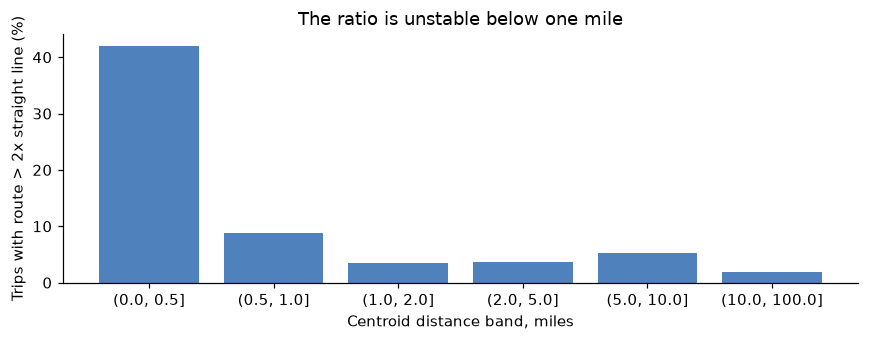

In [57]:
different_zones["centroid_band"] = pd.cut(different_zones["od_centroid_miles"], [0, 0.5, 1, 2, 5, 10, 100])

route_by_band = different_zones.groupby("centroid_band", observed=True)["route_ratio"].agg(
    rows="count",
    median="median",
    over_2_pct=lambda s: 100 * (s > 2).mean(),
    under_0_5_pct=lambda s: 100 * (s < 0.5).mean(),
).round(2)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(route_by_band.index.astype(str), route_by_band["over_2_pct"], color="#4f81bd")
ax.set_xlabel("Centroid distance band, miles")
ax.set_ylabel("Trips with route > 2x straight line (%)")
ax.set_title("The ratio is unstable below one mile")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_route_ratio_by_band.png", bbox_inches="tight")
plt.show()

In [58]:
route_by_band

,rows,median,over_2_pct,under_0_5_pct
centroid_band,,,,
"(0.0, 0.5]",60616,1.83,41.99,0.96
"(0.5, 1.0]",242947,1.29,8.72,1.70
"(1.0, 2.0]",309349,1.22,3.41,0.85
"(2.0, 5.0]",229206,1.25,3.63,0.17
"(5.0, 10.0]",62544,1.43,5.30,0.11
"(10.0, 100.0]",26470,1.41,1.90,0.17


About 40% of trips under half a mile look like "detours", but only because the denominator is so small. From 1–2 miles on, this share settles at around 3–4%. In the 5–10 mile band the share is slightly higher, and so is the median ratio. At this distance most trips cross a river: the straight line goes over the water while the road goes round to a bridge. So the typical ratio depends on the origin-destination pair. I noted this as a feature idea for Section 13.

A real route cannot be shorter than the straight line, and very few trips look like that. This share shows the size of the error introduced by using centroids, and the error is small.

**In the end I defined `route_ratio` only for trips with a centroid distance of at least 1 mile.** I marked the other trips with the `is_route_ratio_undefined` flag. This leaves short trips without a detour measure, because zone-level data cannot measure a detour on a short trip.

In [59]:
RULES["min_centroid_miles"] = 1.0   # 6.3: route_ratio stabilises from this distance

### 6.4 Expected speed by zone and hour

The EDA showed that speed depends strongly on zone and hour. For each pickup zone × hour × day type, the median speed of fit-window trips gives an estimate of the traffic at pickup. By dividing a trip's actual speed by this estimate I obtained the `speed_ratio` feature: was the trip slow for that place and time?

In the next cell I built two tables: the median speed by pickup zone × hour × day type, and the same calculation at borough level as a fallback. Both use only fit-window rows and leave out zones 264 and 265. I used the exact median (`quantile_cont`) in these tables, because these values become part of the matrix and must be identical on every run. Because a median computed from a handful of trips is not reliable, the following cell shows how many trips each cell contains.

In [60]:
con.execute("""
    CREATE OR REPLACE TABLE zone_hour_speed AS
    SELECT
        PULocationID                        AS zone_id,
        pickup_hour                         AS hour,
        is_weekend,
        COUNT(*)                            AS trips,
        quantile_cont(speed_mph, 0.5)       AS expected_speed_mph
    FROM enriched
    WHERE in_fit_window AND speed_mph IS NOT NULL AND PULocationID NOT IN (264, 265)
    GROUP BY 1, 2, 3
""")

# Fallback for sparse cells: the same median per borough
con.execute("""
    CREATE OR REPLACE TABLE borough_hour_speed AS
    SELECT
        pu_borough                          AS borough,
        pickup_hour                         AS hour,
        is_weekend,
        COUNT(*)                            AS trips,
        quantile_cont(speed_mph, 0.5)       AS expected_speed_mph
    FROM enriched
    WHERE in_fit_window AND speed_mph IS NOT NULL AND PULocationID NOT IN (264, 265)
    GROUP BY 1, 2, 3
""");

In [61]:
cell_support = con.execute("""
    SELECT
        CASE
            WHEN trips < 10   THEN '1) under 10'
            WHEN trips < 100  THEN '2) 10 to 99'
            WHEN trips < 1000 THEN '3) 100 to 999'
            ELSE '4) 1000 plus'
        END                                                   AS trips_per_cell,
        COUNT(*)                                              AS cells,
        SUM(trips)                                            AS trips,
        ROUND(100.0 * SUM(trips) / SUM(SUM(trips)) OVER (), 3) AS trip_pct
    FROM zone_hour_speed
    GROUP BY 1 ORDER BY 1
""").df().set_index("trips_per_cell")

cell_support

,cells,trips,trip_pct
trips_per_cell,,,
1) under 10,1515,6744.0,0.003
2) 10 to 99,4220,159175.0,0.076
3) 100 to 999,2162,767696.0,0.365
4) 1000 plus,4194,209607817.0,99.557


Almost half of the cells have fewer than 100 trips, but together these cells cover less than one per thousand of all trips. Most of them are quiet outer-borough zones at night. **I used a zone-hour cell's median only if it has at least 100 fit-window trips.** Below that I used the borough-hour median. The pair counts in Section 7 need no such minimum, because a count, unlike a median, is exact however few trips it covers.

Holdout trips can fall into cells the fit window never saw. I checked that the fallback covers these trips too.

In [62]:
RULES["min_cell_trips"] = 100   # 6.4: cells below this carry under 0.1% of trips

holdout_coverage = con.execute(f"""
    SELECT
        COUNT(*)                                                                         AS holdout_rows,
        ROUND(100.0 * COUNT(*) FILTER (WHERE zone_speed.zone_id IS NULL) / COUNT(*), 4)  AS zone_cell_missing_pct,
        ROUND(100.0 * COUNT(*) FILTER (WHERE zone_speed.trips < {RULES['min_cell_trips']})
              / COUNT(*), 4)                                                             AS zone_cell_sparse_pct,
        COUNT(*) FILTER (WHERE (zone_speed.zone_id IS NULL
                                OR zone_speed.trips < {RULES['min_cell_trips']})
                           AND borough_speed.borough IS NULL)                            AS rows_without_any_speed
    FROM enriched AS e
    LEFT JOIN zone_hour_speed AS zone_speed
      ON e.PULocationID = zone_speed.zone_id AND e.pickup_hour = zone_speed.hour
     AND e.is_weekend = zone_speed.is_weekend
    LEFT JOIN borough_hour_speed AS borough_speed
      ON e.pu_borough = borough_speed.borough AND e.pickup_hour = borough_speed.hour
     AND e.is_weekend = borough_speed.is_weekend
    WHERE NOT e.in_fit_window
      AND e.PULocationID NOT IN (264, 265)
      AND e.DOLocationID NOT IN (264, 265)
""").df()

holdout_coverage

,holdout_rows,zone_cell_missing_pct,zone_cell_sparse_pct,rows_without_any_speed
0,60605145,0.0002,0.0926,0


Every holdout trip with a known zone gets an expected speed, either from its own zone cell or from the borough fallback. No third fallback is needed.

Here I returned to the EDA's open question. The median trip duration had risen by about 15% over the two years while distance stayed flat. The EDA could not tell whether the city had slowed down or whether trips had moved to slower places and hours. `speed_ratio` can separate the two, because the expected speed holds the pickup zone, hour and day type constant:
- If only the mix of trips shifted, raw speed falls but the ratio stays flat.
- If the city itself slowed down, both fall together.

First I plotted the monthly course of both measures; in the next cell I computed the year-over-year change as a table.

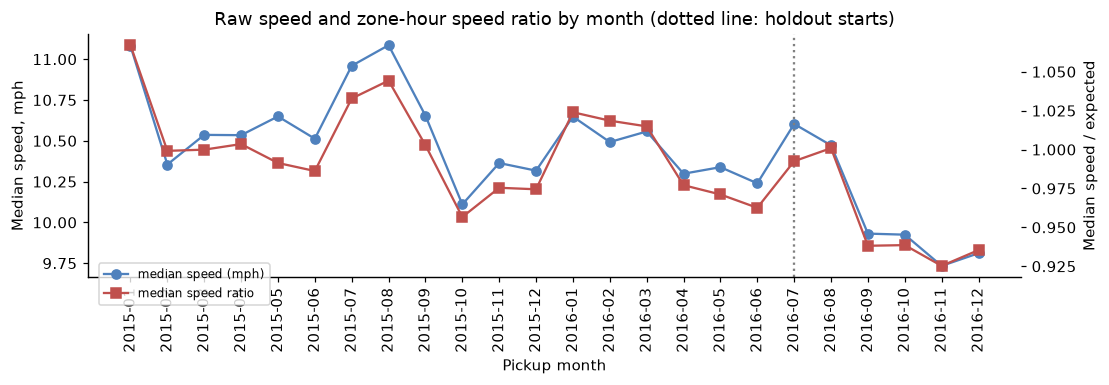

In [63]:
speed_drift = con.execute(f"""
    SELECT
        strftime(e.tpep_pickup_datetime, '%Y-%m')                            AS month,
        approx_quantile(e.speed_mph, 0.5)                                    AS median_speed,
        approx_quantile(e.speed_mph / s.expected_speed_mph, 0.5)             AS median_speed_ratio
    FROM enriched AS e
    JOIN zone_hour_speed AS s
      ON e.PULocationID = s.zone_id AND e.pickup_hour = s.hour AND e.is_weekend = s.is_weekend
    WHERE e.speed_mph IS NOT NULL AND s.trips >= {RULES['min_cell_trips']}
    GROUP BY 1 ORDER BY 1
""").df().set_index("month")

fig, ax_speed = plt.subplots(figsize=(10, 3.6))
ax_ratio = ax_speed.twinx()
ax_speed.plot(speed_drift.index, speed_drift["median_speed"], marker="o", color="#4f81bd", label="median speed (mph)")
ax_ratio.plot(speed_drift.index, speed_drift["median_speed_ratio"], marker="s", color="#c0504d", label="median speed ratio")
ax_speed.axvline(speed_drift.index.get_loc(RULES["fit_end"][:7]), color="grey", linestyle=":")
ax_speed.set_ylabel("Median speed, mph")
ax_speed.set_xlabel("Pickup month")
ax_ratio.set_ylabel("Median speed / expected")
ax_speed.set_title("Raw speed and zone-hour speed ratio by month (dotted line: holdout starts)")
ax_speed.tick_params(axis="x", rotation=90)
fig.legend(loc="lower left", bbox_to_anchor=(0.08, 0.2), fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_speed_drift.png", bbox_inches="tight")
plt.show()

In [64]:
by_month = speed_drift.assign(year=speed_drift.index.str[:4], month_of_year=speed_drift.index.str[5:])
speed = by_month.pivot(index="month_of_year", columns="year", values="median_speed")
ratio = by_month.pivot(index="month_of_year", columns="year", values="median_speed_ratio")

year_over_year = pd.DataFrame({
    "speed_change_pct": 100 * (speed["2016"] / speed["2015"] - 1),
    "ratio_change_pct": 100 * (ratio["2016"] / ratio["2015"] - 1),
}).round(1)
year_over_year

,speed_change_pct,ratio_change_pct
month_of_year,,
01,-3.9,-4.0
02,1.3,1.9
03,0.2,1.5
04,-2.2,-2.6
05,-2.9,-2.0
06,-2.6,-2.4
07,-3.3,-3.9
08,-5.5,-4.2
09,-6.8,-6.4


The two lines move together. The year-over-year table shows this month by month: especially in the second half of the year, when raw speed falls from 2015 to 2016, the ratio falls by about the same amount. The slowdown cannot be explained by trips shifting in place and time. **Trips starting in the same zone, at the same hour and on the same day type were a few percent slower in 2016 than in 2015.** This answers the EDA's question with one limit: the ratio holds only the pickup side constant, so a shift in destinations is not ruled out.

I drew two conclusions from this:
- Within the fit window the ratio changes by a few percent from season to season, so month features are needed.
- In the holdout the median ratio is clearly below 1. Any `speed_ratio` threshold set on the fit window will flag more holdout trips as slow. I handed this risk over to the modelling stage and listed it in Section 13.

### 6.5 Net flow by zone and hour

Pickups minus dropoffs per zone-hour show where vehicles pile up and where they run short. In the EDA I had measured this per zone. Here I measured it per zone × hour × day type. In the next cell I counted pickups by pickup zone and hour and dropoffs by dropoff zone and hour separately, joined the two, took the difference and divided by the number of days in the fit window to get an hourly average. If a cell has no pickups or no dropoffs, I counted that side as 0, because the number of observed trips really is zero. In the cell after that I plotted the largest imbalances.

In [65]:
con.execute("""
    CREATE OR REPLACE TABLE zone_hour_flow AS
    WITH fit_trips AS (
        SELECT * FROM enriched WHERE in_fit_window AND duration_s IS NOT NULL
    ),
    fit_days AS (
        SELECT dayofweek(trip_date) IN (0, 6) AS is_weekend, COUNT(*) AS days
        FROM (SELECT DISTINCT CAST(tpep_pickup_datetime AS DATE) AS trip_date FROM fit_trips)
        GROUP BY 1
    ),
    pickups AS (
        SELECT PULocationID AS zone_id, pickup_hour AS hour, is_weekend, COUNT(*) AS pickups
        FROM fit_trips
        WHERE PULocationID NOT IN (264, 265)
        GROUP BY 1, 2, 3
    ),
    dropoffs AS (
        SELECT
            DOLocationID                                  AS zone_id,
            hour(tpep_dropoff_datetime)                   AS hour,
            dayofweek(tpep_dropoff_datetime) IN (0, 6)    AS is_weekend,
            COUNT(*)                                      AS dropoffs
        FROM fit_trips
        WHERE DOLocationID NOT IN (264, 265)
        GROUP BY 1, 2, 3
    )
    SELECT
        COALESCE(p.zone_id, d.zone_id)                               AS zone_id,
        COALESCE(p.hour, d.hour)                                     AS hour,
        COALESCE(p.is_weekend, d.is_weekend)                         AS is_weekend,
        COALESCE(p.pickups, 0)                                       AS pickups,
        COALESCE(d.dropoffs, 0)                                      AS dropoffs,
        (COALESCE(p.pickups, 0) - COALESCE(d.dropoffs, 0)) / f.days  AS net_flow_per_hour
    FROM pickups AS p
    FULL OUTER JOIN dropoffs AS d
      ON p.zone_id = d.zone_id AND p.hour = d.hour AND p.is_weekend = d.is_weekend
    JOIN fit_days AS f ON f.is_weekend = COALESCE(p.is_weekend, d.is_weekend)
""");

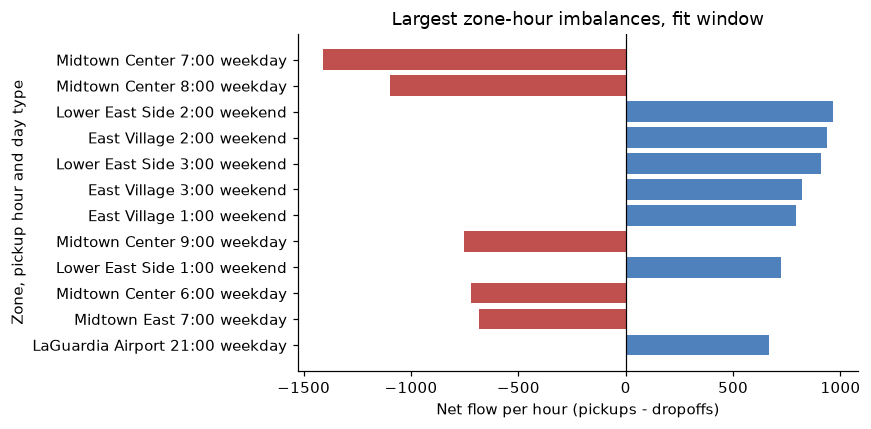

In [66]:
flow_extremes = con.execute(f"""
    SELECT
        lookup.Zone                                                AS zone_name,
        flow.hour,
        CASE WHEN flow.is_weekend THEN 'weekend' ELSE 'weekday' END AS day_type,
        flow.pickups,
        flow.dropoffs,
        ROUND(flow.net_flow_per_hour, 1)                            AS net_flow_per_hour
    FROM zone_hour_flow AS flow
    JOIN read_csv_auto('{ZONE_LOOKUP}') AS lookup ON flow.zone_id = lookup.LocationID
    ORDER BY ABS(flow.net_flow_per_hour) DESC
    LIMIT 12
""").df()

fig, ax = plt.subplots(figsize=(8, 4))
labels = flow_extremes["zone_name"] + " " + flow_extremes["hour"].astype(str) + ":00 " + flow_extremes["day_type"]
colors = ["#c0504d" if value < 0 else "#4f81bd" for value in flow_extremes["net_flow_per_hour"]]
ax.barh(labels[::-1], flow_extremes["net_flow_per_hour"][::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Net flow per hour (pickups - dropoffs)")
ax.set_ylabel("Zone, pickup hour and day type")
ax.set_title("Largest zone-hour imbalances, fit window")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_net_flow_extremes.png", bbox_inches="tight")
plt.show()

In [67]:
flow_extremes

,zone_name,hour,day_type,pickups,dropoffs,net_flow_per_hour
0,Midtown Center,7,weekday,152611,703312,-1408.4
1,Midtown Center,8,weekday,221045,650004,-1097.1
2,Lower East Side,2,weekend,215369,65124,963.1
3,East Village,2,weekend,285315,139047,937.6
4,Lower East Side,3,weekend,181729,40151,907.6
5,East Village,3,weekend,223683,95591,821.1
6,East Village,1,weekend,297312,173330,794.8
7,Midtown Center,9,weekday,252882,547857,-754.4
8,Lower East Side,1,weekend,208311,95293,724.5
9,Midtown Center,6,weekday,77511,359058,-720.1


The largest imbalances come from commuting and nightlife. Midtown Center receives far more trips than it sends on weekday mornings; the net difference exceeds a thousand per hour at 07:00. East Village and Lower East Side send a few hundred more trips than they receive in the early hours of weekend nights. LaGuardia shows up as a strong source on weekday evenings.

When I measured net flow per zone in the EDA, Midtown Center looked balanced, because the morning inflow and the evening outflow cancelled out. The per-zone total hides flows in opposite directions. That is why the feature has to work at zone-hour level. `pu_net_flow` and `do_net_flow` add the value of the pickup and dropoff zone at the pickup hour. For the dropoff zone I also chose the pickup hour on purpose, because the arrival hour is not known at pickup.

To summarise Section 6: I derived the calendar features from rules instead of writing them by hand, separated the three trip regimes by zone, built a distance and a detour measure known at pickup, computed an expected speed by zone and hour that fully covers the holdout, and found an answer to the EDA's slowdown question.

## 7. Categorical encoding

The matrix contains two kinds of categorical information:
- Low-cardinality categories (tariff period, borough, segment, rate code group, payment group). I one-hot encoded these in the preprocessor.
- High-cardinality identifiers (263 pickup zones, 263 dropoff zones, tens of thousands of zone pairs). These are far too many for one-hot encoding.

There is no target variable at this stage, so target encoding is not an option. Even if there were, it would leak information into every later evaluation. For zones I used frequency encoding: the number of fit-window trips for a zone or zone pair. This value tells the model whether a place is busy or quiet. That is exactly the context an anomaly model needs.

### 7.1 Zone pairs: how concentrated is the traffic?

Below I built three count tables from the fit window: pickup zone, dropoff zone and zone pair. The unknown zone 264 does not enter these counts. In the cell after that I looked at how the traffic is spread across the pairs.

In [68]:
for table, zone_column in [("pu_zone_counts", "PULocationID"), ("do_zone_counts", "DOLocationID")]:
    con.execute(f"""
        CREATE OR REPLACE TABLE {table} AS
        SELECT {zone_column} AS zone_id, COUNT(*) AS trips
        FROM enriched
        WHERE in_fit_window AND {zone_column} <> 264
        GROUP BY 1
    """)

con.execute("""
    CREATE OR REPLACE TABLE od_pair_counts AS
    SELECT PULocationID, DOLocationID, COUNT(*) AS trips
    FROM enriched
    WHERE in_fit_window AND PULocationID <> 264 AND DOLocationID <> 264
    GROUP BY 1, 2
""");

In [69]:
od_concentration = con.execute(f"""
    WITH ranked AS (
        SELECT
            trips,
            SUM(trips) OVER (ORDER BY trips DESC) / SUM(trips) OVER () AS cumulative_share
        FROM od_pair_counts
    )
    SELECT
        COUNT(*)                                                           AS observed_pairs,
        COUNT(*) FILTER (WHERE cumulative_share <= 0.80)                   AS pairs_for_80pct,
        COUNT(*) FILTER (WHERE cumulative_share <= 0.95)                   AS pairs_for_95pct,
        COUNT(*) FILTER (WHERE cumulative_share <= 0.99)                   AS pairs_for_99pct,
        COUNT(*) FILTER (WHERE trips < {RULES['min_cell_trips']})          AS pairs_under_min_trips,
        ROUND(100.0 * SUM(trips) FILTER (WHERE trips < {RULES['min_cell_trips']})
              / SUM(trips), 3)                                             AS trip_pct_under_min_trips
    FROM ranked
""").df()

od_concentration

,observed_pairs,pairs_for_80pct,pairs_for_95pct,pairs_for_99pct,pairs_under_min_trips,trip_pct_under_min_trips
0,45542,1634,4151,9376,29435,0.235


Traffic concentrates in a small part of the pairs: a few thousand pairs make up almost all trips, while most observed pairs are rare. As the last column shows, rare pairs make up only a small part of the trips.

`od_pair_trips` is the number of fit-window trips for the pair. A rare pair also keeps its real count: twelve trips are an observed fact about the route. So no minimum is needed. The 100-trip minimum in 6.4 came from a median computed from a few trips being unreliable. A count does not have that problem.

- A pair the fit window never saw gets 0. This is a real zero: no trip was observed for this pair.
- A pair that includes zone 264 gets NULL, because an unknown location has no history.

Since holdout trips can include pairs the fit window never saw, I counted those as well.

In [70]:
unseen_pairs = con.execute(f"""
    WITH holdout_pairs AS (
        SELECT PULocationID, DOLocationID, COUNT(*) AS trips
        FROM enriched
        WHERE NOT in_fit_window AND PULocationID <> 264 AND DOLocationID <> 264
        GROUP BY 1, 2
    )
    SELECT
        COUNT(*)                                                                AS holdout_pairs,
        COUNT(*) FILTER (WHERE fit.trips IS NULL)                               AS unseen_pairs,
        ROUND(100.0 * SUM(h.trips) FILTER (WHERE fit.trips IS NULL)
              / SUM(h.trips), 4)                                                AS unseen_trip_pct,
        ROUND(100.0 * SUM(h.trips) FILTER (WHERE fit.trips IS NULL
                                              OR fit.trips < {RULES['min_cell_trips']})
              / SUM(h.trips), 3)                                                AS no_history_trip_pct
    FROM holdout_pairs AS h
    LEFT JOIN od_pair_counts AS fit
      ON h.PULocationID = fit.PULocationID AND h.DOLocationID = fit.DOLocationID
""").df()

unseen_pairs

,holdout_pairs,unseen_pairs,unseen_trip_pct,no_history_trip_pct
0,37447,1589,0.0031,0.232


Pairs the fit window never saw make up a negligible part of the holdout trips, and together with rare pairs they remain a small share. Unseen pairs get a real zero, so the encoding needs no separate strategy for unknown categories.

### 7.2 The feature query and low-cardinality categories

With all fit-window tables ready, I brought the decisions of Sections 5–7 together in a feature query. I built the query in three steps and defined each step as a separate view: first I attached the prepared tables to every trip, then I computed the features known at pickup, and finally the measures known at dropoff and the quality flags.

The `feature_source` view decides which data the query runs on. Here I pointed it at the sample from 6.3; in 10.1 I will point it at all clean data. In the first step I attached the calendar tables (holidays, tariff holidays, ambiguous tariff dates, DST) and the fit-window tables (frequencies, centroids, expected speed, net flow) to every trip.

In [71]:
con.execute("CREATE OR REPLACE VIEW feature_source AS SELECT * FROM fit_sample")

# Attach the calendar tables and the fit-window tables to every trip
con.execute(f"""
    CREATE OR REPLACE VIEW trip_context AS
    SELECT
        s.*,
        holiday.holiday_date IS NOT NULL                                     AS is_holiday,
        tariff_holiday.holiday_date IS NOT NULL                              AS is_tariff_holiday,
        dst.dst_date IS NOT NULL                                             AS is_dst_transition_day,
        ambiguous.tariff_date IS NOT NULL                                    AS is_tariff_ambiguous_date,
        pu_counts.trips                                                      AS pu_zone_trips_fit,
        do_counts.trips                                                      AS do_zone_trips_fit,
        od_counts.trips                                                      AS od_trips_fit,
        sqrt(power(pu_c.x_feet - do_c.x_feet, 2)
           + power(pu_c.y_feet - do_c.y_feet, 2)) / 5280                     AS od_centroid_miles,
        CASE WHEN zone_speed.trips >= {RULES['min_cell_trips']}
             THEN zone_speed.expected_speed_mph
             ELSE borough_speed.expected_speed_mph END                       AS pu_expected_speed,
        pu_flow.net_flow_per_hour                                            AS pu_flow_fit,
        do_flow.net_flow_per_hour                                            AS do_flow_fit
    FROM feature_source AS s
    LEFT JOIN holiday_dates AS holiday
      ON CAST(s.tpep_pickup_datetime AS DATE) = CAST(holiday.holiday_date AS DATE)
    LEFT JOIN tariff_holiday_dates AS tariff_holiday
      ON CAST(s.tpep_pickup_datetime AS DATE) = CAST(tariff_holiday.holiday_date AS DATE)
    LEFT JOIN dst_dates AS dst
      ON CAST(s.tpep_pickup_datetime AS DATE) = CAST(dst.dst_date AS DATE)
    LEFT JOIN tariff_ambiguous_dates AS ambiguous
      ON CAST(s.tpep_pickup_datetime AS DATE) = CAST(ambiguous.tariff_date AS DATE)
    LEFT JOIN pu_zone_counts AS pu_counts ON s.PULocationID = pu_counts.zone_id
    LEFT JOIN do_zone_counts AS do_counts ON s.DOLocationID = do_counts.zone_id
    LEFT JOIN od_pair_counts AS od_counts
      ON s.PULocationID = od_counts.PULocationID AND s.DOLocationID = od_counts.DOLocationID
    LEFT JOIN zone_centroids AS pu_c ON s.PULocationID = pu_c.zone_id
    LEFT JOIN zone_centroids AS do_c ON s.DOLocationID = do_c.zone_id
    LEFT JOIN zone_hour_speed AS zone_speed
      ON s.PULocationID = zone_speed.zone_id AND s.pickup_hour = zone_speed.hour
     AND s.is_weekend = zone_speed.is_weekend
    LEFT JOIN borough_hour_speed AS borough_speed
      ON s.pu_borough = borough_speed.borough AND s.pickup_hour = borough_speed.hour
     AND s.is_weekend = borough_speed.is_weekend
    LEFT JOIN zone_hour_flow AS pu_flow
      ON s.PULocationID = pu_flow.zone_id AND s.pickup_hour = pu_flow.hour
     AND s.is_weekend = pu_flow.is_weekend
    LEFT JOIN zone_hour_flow AS do_flow
      ON s.DOLocationID = do_flow.zone_id AND s.pickup_hour = do_flow.hour
     AND s.is_weekend = do_flow.is_weekend
""");

In the second step I computed the features known at pickup: the cyclical calendar encodings, the tariff period, the location and zone × time features, and the rate code and payment groups. For frequency and flow values I applied the rule from 7.1: an unseen zone gets 0, the unknown zone gets NULL.

In [72]:
overnight = f"pickup_hour >= {RULES['overnight_start']} OR pickup_hour < {RULES['overnight_end']}"
weekday_peak = (f"NOT is_weekend AND NOT is_tariff_holiday "
                f"AND pickup_hour BETWEEN {RULES['peak_start']} AND {RULES['peak_end']}")
boundary_hours = ", ".join(str(hour) for hour in RULES["boundary_hours"])

# Features known when the trip starts
con.execute(f"""
    CREATE OR REPLACE VIEW pickup_features AS
    SELECT
        *,
        sin(2 * pi() * pickup_hour / 24)                                      AS hour_sin,
        cos(2 * pi() * pickup_hour / 24)                                      AS hour_cos,
        sin(2 * pi() * dayofweek(tpep_pickup_datetime) / 7)                   AS dow_sin,
        cos(2 * pi() * dayofweek(tpep_pickup_datetime) / 7)                   AS dow_cos,
        sin(2 * pi() * (month(tpep_pickup_datetime) - 1) / 12)                AS month_sin,
        cos(2 * pi() * (month(tpep_pickup_datetime) - 1) / 12)                AS month_cos,
        (year(tpep_pickup_datetime) - 2015) * 12
            + month(tpep_pickup_datetime) - 1                                 AS months_since_start,
        pickup_hour = {RULES['shift_change_hour']}                            AS is_shift_change_window,
        CASE WHEN {overnight} THEN 'overnight'
             WHEN {weekday_peak} THEN 'weekday_peak'
             ELSE 'standard' END                                              AS tariff_period,
        CASE WHEN {overnight} THEN {RULES['overnight_extra']}
             WHEN {weekday_peak} THEN {RULES['peak_extra']}
             ELSE 0 END                                                       AS expected_extra,
        -- 5.4: the surcharge rule is evaluated only where it is unambiguous
        RatecodeID = 1 AND pickup_hour NOT IN ({boundary_hours})
            AND NOT (is_tariff_ambiguous_date
                     AND pickup_hour BETWEEN {RULES['peak_start']} AND {RULES['peak_end']})
                                                                              AS extra_rule_applies,
        pu_borough || ' > ' || do_borough                                     AS borough_pair,
        -- 7.1: an unseen zone is a real 0, the unknown zone 264 is NULL
        CASE WHEN PULocationID = 264 THEN NULL ELSE COALESCE(pu_zone_trips_fit, 0) END AS pu_zone_trips,
        CASE WHEN DOLocationID = 264 THEN NULL ELSE COALESCE(do_zone_trips_fit, 0) END AS do_zone_trips,
        CASE WHEN 264 IN (PULocationID, DOLocationID) THEN NULL
             ELSE COALESCE(od_trips_fit, 0) END                               AS od_pair_trips,
        PULocationID = DOLocationID                                           AS is_same_zone,
        264 IN (PULocationID, DOLocationID)                                   AS is_zone_unknown,
        265 IN (PULocationID, DOLocationID)                                   AS is_outside_nyc,
        CASE WHEN PULocationID IN (264, 265) THEN NULL ELSE COALESCE(pu_flow_fit, 0) END AS pu_net_flow,
        CASE WHEN DOLocationID IN (264, 265) THEN NULL ELSE COALESCE(do_flow_fit, 0) END AS do_net_flow,
        CASE RatecodeID WHEN 1 THEN 'standard' WHEN 2 THEN 'jfk' WHEN 3 THEN 'newark'
                        WHEN 5 THEN 'negotiated' ELSE 'other' END             AS ratecode_group,
        CASE payment_type WHEN 1 THEN 'card' WHEN 2 THEN 'cash' ELSE 'other' END AS payment_group
    FROM trip_context
""");

In the last step I added the measures known at dropoff (distance, duration, ratios, `fare_excess`, tip rate, toll) and the quality flags. Flags that cannot be evaluated stay NULL. This view is the final form of the matrix: the columns start with the control columns, followed by the feature families.

In [73]:
tip_rule = f"payment_type = 1 AND RatecodeID IN (1, 2) AND fare_amount >= {RULES['min_fare']}"

# Measures known at dropoff and the quality flags; NULL means "not evaluated"
con.execute(f"""
    CREATE OR REPLACE VIEW feature_matrix AS
    SELECT
        tpep_pickup_datetime, PULocationID, DOLocationID, in_fit_window, VendorID,
        NULLIF(passenger_count, 0)                                            AS passenger_count,
        store_and_fwd_flag = 'Y'                                              AS is_store_forward,
        fare_amount, total_amount,
        hour_sin, hour_cos, dow_sin, dow_cos, month_sin, month_cos, months_since_start,
        is_weekend, is_holiday, is_dst_transition_day, is_shift_change_window, tariff_period,
        pu_borough, do_borough, borough_pair, trip_segment,
        pu_zone_trips, do_zone_trips, od_pair_trips, is_same_zone, is_zone_unknown, is_outside_nyc,
        od_centroid_miles, pu_expected_speed, pu_net_flow, do_net_flow,
        ratecode_group, payment_group,
        trip_distance,
        duration_s / 60.0                                                     AS duration_min,
        speed_mph / pu_expected_speed                                         AS speed_ratio,
        CASE WHEN od_centroid_miles >= {RULES['min_centroid_miles']}
             THEN trip_distance / od_centroid_miles END                       AS route_ratio,
        CASE WHEN RatecodeID = 1 AND trip_distance IS NOT NULL
             THEN fare_amount - ({TARIFF['intercept']} + {TARIFF['slope']} * trip_distance)
        END                                                                   AS fare_excess,
        CASE WHEN {tip_rule}
             THEN LEAST(tip_amount / fare_amount, {RULES['tip_rate_cap']}) END AS tip_rate,
        tolls_amount > 0                                                      AS has_toll,
        raw_trip_distance = 0                                                 AS is_distance_missing,
        raw_trip_distance < 0 OR raw_trip_distance > {RULES['max_distance_miles']}
            OR COALESCE(raw_speed_mph > {RULES['max_speed_mph']}, FALSE)      AS is_distance_invalid,
        raw_duration_s <= 0 OR raw_duration_s > {RULES['max_duration_s']}     AS is_duration_invalid,
        CASE WHEN duration_s IS NOT NULL
             THEN duration_s < {RULES['very_short_s']} END                    AS is_very_short,
        speed_mph BETWEEN {RULES['high_speed_mph']} AND {RULES['max_speed_mph']} AS is_high_speed,
        ABS(total_amount - (fare_amount + extra + mta_tax + tip_amount
            + tolls_amount + improvement_surcharge)) > 0.01                   AS is_amount_mismatch,
        fare_amount < {RULES['min_fare']}                                     AS is_fare_below_minimum,
        RatecodeID = 99                                                       AS is_ratecode_invalid,
        CASE WHEN extra_rule_applies THEN extra <> expected_extra END         AS is_extra_mismatch,
        CASE WHEN {tip_rule} THEN tip_amount > fare_amount END                AS is_tip_rate_extreme,
        od_centroid_miles IS NULL OR od_centroid_miles < {RULES['min_centroid_miles']}
            OR trip_distance IS NULL                                          AS is_route_ratio_undefined
    FROM pickup_features
""");

The following cell reads the sample matrix. I first sorted the rows into a fixed order, because the database returns rows in the order the parallel threads finish. Everything that depends on row order (a seeded subsample, float sums inside the preprocessor) would otherwise change from run to run. The encoding, transformation and redundancy decisions that follow are based on this sample matrix. After that I looked at the class distribution of the categorical columns.

In [74]:
sample_matrix = (con.execute("SELECT * FROM feature_matrix").df()
                 .sort_values(["tpep_pickup_datetime", "PULocationID", "DOLocationID", "total_amount"])
                 .reset_index(drop=True))

FLAG_COLUMNS = [c for c in sample_matrix.columns if c.startswith("is_") or c == "has_toll"]
sample_matrix[FLAG_COLUMNS] = sample_matrix[FLAG_COLUMNS].astype(float)

print(f"Sample matrix: {sample_matrix.shape[0]:,} rows x {sample_matrix.shape[1]} columns")
print("Flags that can be NULL (% not evaluated):")
print(sample_matrix[FLAG_COLUMNS].isna().mean().mul(100).round(3)[lambda s: s > 0].to_string())

Sample matrix: 1,000,374 rows x 55 columns
Flags that can be NULL (% not evaluated):
is_very_short           0.243
is_high_speed           0.813
is_extra_mismatch      14.358
is_tip_rate_extreme    36.495


In [75]:
CATEGORICAL = ["tariff_period", "pu_borough", "do_borough", "borough_pair",
               "trip_segment", "ratecode_group", "payment_group"]

category_balance = pd.DataFrame({
    "classes": {c: sample_matrix[c].nunique(dropna=False) for c in CATEGORICAL},
    "top_class": {c: sample_matrix[c].value_counts(dropna=False).index[0] for c in CATEGORICAL},
    "top_class_pct": {c: 100 * sample_matrix[c].value_counts(normalize=True, dropna=False).iloc[0]
                      for c in CATEGORICAL},
    "classes_under_0_1pct": {c: int((sample_matrix[c].value_counts(normalize=True, dropna=False) < 0.001).sum())
                             for c in CATEGORICAL},
    "pct_in_those_classes": {c: 100 * sample_matrix[c].value_counts(normalize=True, dropna=False)
                             .loc[lambda s: s < 0.001].sum() for c in CATEGORICAL},
}).round(3)

category_balance

,classes,top_class,top_class_pct,classes_under_0_1pct,pct_in_those_classes
tariff_period,3,standard,50.671,0,0.000
pu_borough,8,Manhattan,90.722,4,0.155
do_borough,8,Manhattan,87.083,1,0.024
borough_pair,49,Manhattan > Manhattan,83.093,34,0.412
trip_segment,6,city,91.521,0,0.000
ratecode_group,5,standard,97.334,1,0.050
payment_group,3,card,63.897,0,0.000


In every categorical column one or two classes dominate, while the rare classes together make up far less than one percent of trips. `borough_pair` has the most classes, but most of them are rare combinations such as Staten Island to the Bronx.

One-hot encoding opens a column for every class. A column that is almost always zero adds noise without adding information. For this reason the preprocessor uses `min_frequency=0.001`: classes below 0.1% of the fit sample are merged into a single "infrequent" column. Categories that first appear in new data also fall into the same "infrequent" column.

### 7.3 Encoding summary

| Column | Classes | Encoding | Reason |
|---|---|---|---|
| `tariff_period` | 3 | one-hot | tariff context at pickup (5.4) |
| `pu_borough`, `do_borough` | 8 | one-hot, rare classes infrequent | coarse location |
| `borough_pair` | ~50 | one-hot, rare classes infrequent | coarse origin-destination, readable version of the zone pair |
| `trip_segment` | 6 | one-hot | three regimes plus unknown, outside NYC and Newark (6.2) |
| `ratecode_group` | 5 | one-hot, rare classes infrequent | standard, JFK, Newark, negotiated, other (4.3) |
| `payment_group` | 3 | one-hot | card, cash, other; also shows when `tip_rate` is structurally missing |
| Pickup / dropoff zone | 263 + 2 | frequency (`pu_zone_trips`, `do_zone_trips`): fit-window trip count, unseen zone 0, zone 264 NULL | busy or quiet place, without opening 263 sparse columns |
| Zone pair | tens of thousands | frequency (`od_pair_trips`): fit-window trip count, unseen pair 0, zone 264 NULL | how common the route is (7.1) |
| `VendorID` | 2–3 | not a model feature | control variable, because data quality depends on the vendor (4.2) |

Zone 265 (outside NYC) is a real place, so it keeps its frequency and its own segment. But because the segment rules take airports first, a trip from JFK to outside NYC is labelled `jfk`. The separate `is_outside_nyc` flag keeps that information from being lost.

In [76]:
RULES["one_hot_min_frequency"] = 0.001   # 7.2: classes below 0.1% merge into "infrequent"

## 8. Missing values, transformations and scaling

### 8.1 Is every NULL explained?

In Sections 4–7 I produced NULLs on purpose: wrong measurement values, tips that were never recorded, zones without a location, ratios without a stable denominator. Before deciding how a model should fill them, I checked that every NULL has a known reason visible in another column. Filling a NULL with no recorded reason would silently hide a problem.

For the two measurement columns I checked both directions. A NULL without a flag is an unexplained gap. A flag without a NULL means that the cleaning and the flag contradict each other.

My decision rule was: if all `unexplained_pct` values are zero, the preprocessor fills numeric NULLs with the fit-window median and the existing flags show that a value was missing. Any non-zero value would mean a new flag or a fix was needed first.

In [77]:
zone_gap = (sample_matrix["is_zone_unknown"] == 1) | (sample_matrix["is_outside_nyc"] == 1)
distance_null = sample_matrix["trip_distance"].isna()
duration_null = sample_matrix["duration_min"].isna()
distance_flag = (sample_matrix["is_distance_missing"] == 1) | (sample_matrix["is_distance_invalid"] == 1)
duration_flag = sample_matrix["is_duration_invalid"] == 1

NULL_CAUSES = {
    "trip_distance": distance_flag,
    "duration_min": duration_flag,
    "speed_ratio": distance_null | duration_null | zone_gap,
    "fare_excess": (sample_matrix["ratecode_group"] != "standard") | distance_null,
    "tip_rate": (sample_matrix["payment_group"] != "card")
                | ~sample_matrix["ratecode_group"].isin(["standard", "jfk"])
                | (sample_matrix["is_fare_below_minimum"] == 1),
    "od_centroid_miles": zone_gap,
    "route_ratio": sample_matrix["is_route_ratio_undefined"] == 1,
    "pu_zone_trips": zone_gap,
    "do_zone_trips": zone_gap,
    "od_pair_trips": zone_gap,
    "pu_expected_speed": zone_gap,
    "pu_net_flow": zone_gap,
    "do_net_flow": zone_gap,
}

null_audit = pd.DataFrame({
    "null_pct": {c: 100 * sample_matrix[c].isna().mean() for c in NULL_CAUSES},
    "unexplained_pct": {c: 100 * (sample_matrix[c].isna() & ~cause).mean() for c, cause in NULL_CAUSES.items()},
    "flag_without_null_pct": {
        "trip_distance": 100 * (distance_flag & ~distance_null).mean(),
        "duration_min": 100 * (duration_flag & ~duration_null).mean(),
    },
}).round(4)

null_audit

,null_pct,unexplained_pct,flag_without_null_pct
trip_distance,0.6887,0.0,0.0
duration_min,0.2430,0.0,0.0
speed_ratio,2.2505,0.0,NaN
fare_excess,3.0899,0.0,NaN
tip_rate,36.4949,0.0,NaN
od_centroid_miles,1.9234,0.0,NaN
route_ratio,37.2666,0.0,NaN
pu_zone_trips,1.5194,0.0,NaN
do_zone_trips,1.4547,0.0,NaN
od_pair_trips,1.6819,0.0,NaN


Every NULL has a recorded reason, and the flags and the cleaning agree in both directions. The two large NULL rates come from the structure of the data: `tip_rate` is missing on every trip not paid by card on the standard or JFK rate (5.2), and `route_ratio` is missing on trips within one zone and on trips with a centroid distance under one mile (6.3).

**I filled numeric NULLs with the fit-window median inside the preprocessor.** The flags, `payment_group` and `is_route_ratio_undefined` show that a value was missing. This way a value filled with the median does not get mixed up with a real measurement.

The same question applies to flags that can be NULL. A flag becomes NULL when the input it evaluates is unknown or when the rule behind it does not apply (5.4, 5.5). Here too I checked both directions: is there a flag that is NULL without a known reason, and is there a flag that was evaluated although its input is missing?

In [78]:
pickup_hour = sample_matrix["tpep_pickup_datetime"].dt.hour
pickup_date = sample_matrix["tpep_pickup_datetime"].dt.normalize()
ambiguous_peak = (pickup_date.isin(CALENDARS["tariff_ambiguous"]["tariff_date"])
                  & pickup_hour.between(RULES["peak_start"], RULES["peak_end"]))

FLAG_NULL_CAUSES = {
    "is_very_short": duration_null,
    "is_high_speed": distance_null | duration_null,
    "is_extra_mismatch": (sample_matrix["ratecode_group"] != "standard")
                         | pickup_hour.isin(RULES["boundary_hours"])
                         | ambiguous_peak,
    "is_tip_rate_extreme": NULL_CAUSES["tip_rate"],
}

flag_audit = pd.DataFrame({
    "null_pct": {c: 100 * sample_matrix[c].isna().mean() for c in FLAG_NULL_CAUSES},
    "unexplained_pct": {c: 100 * (sample_matrix[c].isna() & ~cause).mean()
                        for c, cause in FLAG_NULL_CAUSES.items()},
    "evaluated_without_input_pct": {c: 100 * (sample_matrix[c].notna() & cause).mean()
                                    for c, cause in FLAG_NULL_CAUSES.items()},
}).round(4)

flag_audit

,null_pct,unexplained_pct,evaluated_without_input_pct
is_very_short,0.2430,0.0,0.0
is_high_speed,0.8133,0.0,0.0
is_extra_mismatch,14.3579,0.0,0.0
is_tip_rate_extreme,36.4949,0.0,0.0


Both directions are zero for every flag: a flag is NULL only when its input is unknown or its rule does not apply. In the preprocessor a NULL flag becomes 0, meaning "no evidence of a problem". The matrix itself keeps the NULL, so every rate computed from the matrix (for example, the share of trips with a surcharge mismatch) uses only the trips that were actually evaluated.

### 8.2 Transformations

Distance-based and linear models are sensitive to skew: a long right tail lets a handful of extreme trips dominate the distances between points. Tree-based models are not affected. Since no model has been chosen yet, I decided the transformation feature by feature and left the matrix on disk untransformed (Section 10).

For every continuous feature I compared the skewness of the raw values, the `log1p` transform and the Yeo-Johnson transform (a Box-Cox variant that also accepts zero and negative values). I made the choice with a rule I wrote before looking at the numbers:

1. If the absolute raw skewness is 1 or less, no transformation is applied; only standard scaling.
2. If `log1p` brings the absolute skewness below 1 and that value is at most 0.5 above Yeo-Johnson's, `log1p` is used. It has no fitted parameter, so no information can leak.
3. If Yeo-Johnson reduces the skewness, Yeo-Johnson is used and its parameter is fitted on the fit window.
4. If neither works, the raw values are kept and robust scaling (median and IQR instead of mean and standard deviation) is applied.

In [79]:
import numpy as np
from sklearn.preprocessing import PowerTransformer

CONTINUOUS = ["trip_distance", "duration_min", "speed_ratio", "fare_excess", "tip_rate",
              "od_centroid_miles", "route_ratio", "pu_zone_trips", "do_zone_trips",
              "od_pair_trips", "pu_expected_speed", "pu_net_flow", "do_net_flow"]


def choose_transform(row):
    if abs(row["skew_raw"]) <= 1:
        return "none"
    if (pd.notna(row["skew_log1p"]) and abs(row["skew_log1p"]) <= 1
            and abs(row["skew_log1p"]) - abs(row["skew_yeo_johnson"]) < 0.5):
        return "log1p"
    if abs(row["skew_yeo_johnson"]) < abs(row["skew_raw"]):
        return "yeo_johnson"
    return "robust"


transform_rows = []
for column in CONTINUOUS:
    values = sample_matrix[column].dropna().astype(float)
    with np.errstate(all="ignore"):
        transformed = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(values.to_frame())
    transform_rows.append({
        "feature": column,
        "min": values.min(),
        "kurtosis_raw": values.kurt(),
        "skew_raw": values.skew(),
        "skew_log1p": np.log1p(values).skew() if values.min() >= 0 else np.nan,
        "skew_yeo_johnson": pd.Series(transformed.ravel()).skew(),
    })

transform_choice = pd.DataFrame(transform_rows).set_index("feature")
transform_choice["choice"] = transform_choice.apply(choose_transform, axis=1)
transform_choice.round(2)

,min,kurtosis_raw,skew_raw,skew_log1p,skew_yeo_johnson,choice
feature,,,,,,
trip_distance,0.01,13.19,3.11,1.11,0.11,yeo_johnson
duration_min,0.02,12.88,2.45,-0.11,0.00,log1p
speed_ratio,0.00,9.64,2.10,0.81,-0.04,yeo_johnson
fare_excess,-150.63,284.54,3.68,NaN,-6.70,robust
tip_rate,0.00,13.30,1.15,0.11,-0.02,log1p
od_centroid_miles,0.00,8.68,2.74,0.86,0.01,yeo_johnson
route_ratio,0.00,231.47,5.94,0.55,-0.07,log1p
pu_zone_trips,60.00,-0.75,-0.47,-3.10,-0.40,none
do_zone_trips,405.00,-1.03,-0.08,-2.24,-0.33,none


The rule made a decision for every feature. Two choices need a word of explanation. For `route_ratio` the rule picked `log1p` by a very small margin: the absolute skewness is 0.55 after `log1p` and 0.07 after Yeo-Johnson. The difference (0.48) is just below the 0.5 limit. Here I did not go by my own guess; I followed the rule I had written in advance. The kurtosis of `fare_excess` runs into the hundreds: most trips sit a few dollars from the tariff, while a few deviate by more than a hundred dollars. Both transforms made its skewness worse, so I kept the raw values and applied robust scaling (median and IQR), which a handful of extreme trips cannot distort.

### 8.3 Scaling and the preprocessor

Whether scaling is needed depends on the model. Tree-based models (Isolation Forest, gradient boosting) split on one feature at a time, so they are not affected by scale. Distance-based and linear models (LOF, k-means, logistic regression, autoencoders) compare features directly. In these models a count in the millions would swamp a flag that is 0 or 1. Since the model is not decided yet, I left the matrix on disk unscaled and put scaling inside the preprocessor:

| Group | Steps |
|---|---|
| `log1p` | median imputation, `log1p`, standard scaling |
| `yeo_johnson` | median imputation, Yeo-Johnson (standardised) |
| `robust` | median imputation, median/IQR scaling |
| `standard` | median imputation, standard scaling |
| flags and cyclical encodings | NULL values become 0, others unchanged (already on a 0–1 or −1–1 scale) |
| categories | one-hot, classes below 0.1% in the "infrequent" column |

The control columns (`VendorID`, `passenger_count`, `is_store_forward`, raw fare and total, identifiers) never reach the model. In the next cell I defined the function that builds the preprocessor. In the cell after that I fitted it on the fit-window sample and checked that every column is assigned to a group, that no value stays NULL and that the scaled features fall in the expected range.

In [80]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, PowerTransformer,
                                   RobustScaler, StandardScaler)


def build_preprocessor(spec):
    """One ColumnTransformer from the column groups chosen in 8.2."""
    log1p = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])
    yeo_johnson = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("power", PowerTransformer(method="yeo-johnson", standardize=True)),
    ])
    robust = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", RobustScaler()),
    ])
    standard = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    # A NULL flag means "not evaluated"; for the model it becomes 0, "no evidence of a problem"
    passthrough = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value=0)),
    ])
    one_hot = OneHotEncoder(handle_unknown="infrequent_if_exist",
                            min_frequency=spec["min_frequency"], sparse_output=False)

    return ColumnTransformer(
        transformers=[
            ("log1p", log1p, spec["log1p"]),
            ("yeo_johnson", yeo_johnson, spec["yeo_johnson"]),
            ("robust", robust, spec["robust"]),
            ("standard", standard, spec["standard"]),
            ("passthrough", passthrough, spec["passthrough"]),
            ("one_hot", one_hot, spec["one_hot"]),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

In [81]:
CONTROL_COLUMNS = ["tpep_pickup_datetime", "PULocationID", "DOLocationID", "in_fit_window",
                   "VendorID", "passenger_count", "is_store_forward", "fare_amount", "total_amount"]
CYCLICAL = ["hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos"]

choice = transform_choice["choice"]
PREPROCESSOR_SPEC = {
    "log1p": choice[choice == "log1p"].index.tolist(),
    "yeo_johnson": choice[choice == "yeo_johnson"].index.tolist(),
    "robust": choice[choice == "robust"].index.tolist(),
    "standard": choice[choice == "none"].index.tolist() + ["months_since_start"],
    "passthrough": CYCLICAL + [c for c in FLAG_COLUMNS if c not in CONTROL_COLUMNS],
    "one_hot": CATEGORICAL,
    "min_frequency": RULES["one_hot_min_frequency"],
}

assigned = {c for group, cols in PREPROCESSOR_SPEC.items() if group != "min_frequency" for c in cols}
unassigned = set(sample_matrix.columns) - assigned - set(CONTROL_COLUMNS)
assert not unassigned, f"Columns without a preprocessing group: {unassigned}"

preprocessor = build_preprocessor(PREPROCESSOR_SPEC)
model_ready = preprocessor.fit_transform(sample_matrix)

numeric_out = (PREPROCESSOR_SPEC["log1p"] + PREPROCESSOR_SPEC["yeo_johnson"]
               + PREPROCESSOR_SPEC["robust"] + PREPROCESSOR_SPEC["standard"])
assert int(model_ready.isna().sum().sum()) == 0, "NULLs left after preprocessing"
(model_ready[numeric_out].agg(["mean", "std", "min", "max"]).T.round(2)
 .rename_axis(f"model-ready sample: {model_ready.shape[0]:,} rows x {model_ready.shape[1]} columns"))

,mean,std,min,max
"model-ready sample: 1,000,374 rows x 85 columns",,,,
duration_min,-0.00,1.00,-3.66,4.45
tip_rate,0.00,1.00,-3.49,9.09
route_ratio,-0.00,1.00,-6.96,21.92
trip_distance,-0.00,1.00,-3.07,2.50
speed_ratio,0.00,1.00,-5.24,4.46
od_centroid_miles,-0.00,1.00,-2.26,2.74
od_pair_trips,0.00,1.00,-2.73,2.96
pu_expected_speed,-0.00,1.00,-2.34,2.81
do_net_flow,0.00,1.00,-6.35,6.57


Every scaled feature has mean 0 and standard deviation 1. The exception is `fare_excess`: robust scaling centres the median and deliberately leaves extreme values large. A trip charged \$100 less than its distance requires should not get lost among the other values; it should stand out. The long upper tails of `route_ratio` and `tip_rate` show real detours and generous tips, so they are kept for the same reason.

## 9. Redundancy

In this section I checked whether some features repeat each other. Two features that carry the same information waste a model's capacity and make linear models unstable. I used two tools:
- Spearman correlation for pairs. Because it is rank-based, it catches every monotonic relationship, not only linear ones.
- VIF (variance inflation factor) for groups. It measures how well a feature can be reproduced from all the other features together. Pairwise correlation cannot catch this.

Redundancy depends on which model uses the features. A model that runs at pickup (duration, fare or demand prediction) can use only features known at pickup. The completed-trip model (anomaly detection) can use all of them. Since two features that never enter the same model cannot repeat each other, I evaluated redundancy per scenario.

### 9.1 Correlated pairs and groups

To show why, I also added three candidates I expected to leave out: raw `fare_amount`, raw `total_amount` and raw speed (`trip_distance / duration`).

My decision rules were: if the absolute Spearman value within a scenario is 0.9 or higher, one of the pair is removed and the one known earlier and easier to interpret is kept. Between 0.7 and 0.9 both are kept and documented. If VIF exceeds 10, the cause is examined. A dependency that comes from a definition (such as speed = distance / duration) is documented, not removed.

First I looked at the Spearman pairs, and in the next cell at the VIF values.

In [82]:
candidates = sample_matrix.assign(speed_mph=sample_matrix["trip_distance"] / (sample_matrix["duration_min"] / 60))
REDUNDANCY_CHECK = numeric_out + ["fare_amount", "total_amount", "speed_mph"]

corr_sample = candidates[REDUNDANCY_CHECK].sample(300_000, random_state=RANDOM_SEED)
spearman = corr_sample.corr(method="spearman")
upper = spearman.where(np.triu(np.ones(spearman.shape, dtype=bool), k=1))
high_pairs = (upper.stack().rename("spearman").reset_index()
              .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
              .query("abs(spearman) >= 0.7")
              .sort_values("spearman", key=abs, ascending=False)
              .round(3))
high_pairs.reset_index(drop=True)

,feature_a,feature_b,spearman
0,fare_amount,total_amount,0.977
1,duration_min,fare_amount,0.949
2,trip_distance,fare_amount,0.931
3,duration_min,total_amount,0.925
4,trip_distance,total_amount,0.916
5,trip_distance,od_centroid_miles,0.911
6,od_centroid_miles,fare_amount,0.842
7,duration_min,trip_distance,0.835
8,od_centroid_miles,total_amount,0.829
9,speed_ratio,speed_mph,0.783


In [83]:
vif_input = model_ready[numeric_out].copy()
vif_input["speed_mph"] = np.log1p(candidates["speed_mph"].fillna(candidates["speed_mph"].median()))
inverse_corr = np.linalg.pinv(np.corrcoef(vif_input.to_numpy(dtype=float), rowvar=False))
vif_trip = pd.Series(np.diag(inverse_corr), index=vif_input.columns, name="vif_completed_trip").round(2)
vif_trip.sort_values(ascending=False).head(10).to_frame()

,vif_completed_trip
speed_mph,30.16
trip_distance,20.74
speed_ratio,19.19
duration_min,14.69
pu_expected_speed,10.41
od_centroid_miles,6.49
od_pair_trips,5.19
fare_excess,3.04
do_zone_trips,2.21
pu_zone_trips,1.96


The pairs confirmed two decisions and required me to change one.

- Raw `fare_amount` and `total_amount` correlate at 0.98 with each other and above 0.9 with distance and duration. I kept them out of the model as control columns. Their information is already split into readable parts: distance and duration (the meter fare), `fare_excess` (deviation from the tariff), `tip_rate` and `has_toll`.
- Raw speed has the highest VIF (about 30) and can be reproduced exactly from distance and duration. That is why it is not in the matrix. `speed_ratio` keeps the information raw speed cannot contain: how fast the trip was for its own zone and hour.
- The correlation between `trip_distance` and `od_centroid_miles` is 0.91, and in the completed-trip scenario both would be present. Under the rule, one had to go. The measured distance makes its own estimate unnecessary. **I therefore removed `od_centroid_miles` from the completed-trip set.** The relationship between the two is not lost, because `route_ratio` keeps it. In the pickup scenario `trip_distance` cannot be used, so `od_centroid_miles` remains the only distance information there.

### 9.2 Final VIF per scenario

The VIF values above still included raw speed and the centroid distance. So I recomputed VIF on the final feature set of each scenario.

In [84]:
def variance_inflation(frame):
    inverse = np.linalg.pinv(np.corrcoef(frame.to_numpy(dtype=float), rowvar=False))
    return pd.Series(np.diag(inverse), index=frame.columns).round(2)


PICKUP_BINARY = ["is_weekend", "is_holiday", "is_dst_transition_day", "is_shift_change_window",
                 "is_same_zone", "is_zone_unknown", "is_outside_nyc"]
PICKUP_NUMERIC = ["pu_zone_trips", "do_zone_trips", "od_pair_trips", "od_centroid_miles",
                  "pu_expected_speed", "pu_net_flow", "do_net_flow", "months_since_start"]
TRIP_NUMERIC = [c for c in numeric_out if c != "od_centroid_miles"]

vif_by_scenario = pd.concat({
    "pickup": variance_inflation(model_ready[PICKUP_NUMERIC + CYCLICAL + PICKUP_BINARY]),
    "completed_trip": variance_inflation(model_ready[TRIP_NUMERIC + CYCLICAL + PICKUP_BINARY]),
}, axis=1)

vif_by_scenario.sort_values("completed_trip", ascending=False).head(12)

,pickup,completed_trip
trip_distance,NaN,19.19
duration_min,NaN,13.63
speed_ratio,NaN,5.25
od_pair_trips,5.06,5.01
pu_expected_speed,2.41,4.04
is_weekend,3.13,3.13
fare_excess,NaN,2.87
dow_cos,2.62,2.64
do_zone_trips,2.08,2.19
pu_zone_trips,2.08,2.04


In the pickup scenario every VIF is below 10. The highest value, about 5, belongs to `od_pair_trips`. No feature a pickup-time model would see repeats another.

In the completed-trip scenario, removing raw speed brought the VIF of `speed_ratio` down to about 5, but `trip_distance` (about 19) and `duration_min` (about 14) stayed above 10. The reason is the definition itself: `speed_ratio` is speed divided by expected speed, and speed is distance divided by duration. On a log scale, log(speed) = log(distance) − log(duration), so any one of these three features can be computed almost exactly from the other two. Under the rule I did not remove this dependency; I documented it. All three are core signals for anomaly detection, and spotting a trip whose distance, duration and speed do not fit together is exactly an anomaly model's job. Tree-based models are not affected by this dependency. For a linear or distance-based model, I noted in the feature dictionary that two of the three carry almost all the information.

Decisions in Section 9:

| Feature | Decision | Evidence |
|---|---|---|
| raw `fare_amount`, `total_amount` | control column, not a model feature | Spearman 0.93–0.98 with each other and with distance and duration |
| raw speed | not in the matrix | VIF about 30; reproduced exactly from distance and duration |
| `od_centroid_miles` | pickup scenario only | Spearman 0.91 with `trip_distance`; `route_ratio` keeps the relationship |
| `trip_distance`, `duration_min`, `speed_ratio` | kept, dependency documented | VIF above 10 by definition |

## 10. Building and saving the matrix

### 10.1 The full feature matrix

I now ran the feature query built in 7.2 on all clean trips. For that I switched the `feature_source` view from the sample to all clean data (`enriched`). I wrote the matrix untransformed: scaling and encoding stay in the preprocessor, so every later model can apply its own transformations. The output is Parquet files partitioned by pickup year and month. This way a later step can read a single month without scanning two years.

Before writing I deleted any matrix left from an earlier run, otherwise old files could mix with the new ones. After writing, in the next cell, I made two checks: the row count must equal the clean view exactly, and a content hash records the matrix's fingerprint. This fingerprint is used to prove that a later run produces the same result.

In [85]:
import shutil
import time

MATRIX_DIR = PROJECT_ROOT / "data" / "processed" / "feature_matrix"

if MATRIX_DIR.exists():
    shutil.rmtree(MATRIX_DIR)
MATRIX_DIR.parent.mkdir(parents=True, exist_ok=True)

# The same three views as in 7.2, now reading every clean trip
con.execute("CREATE OR REPLACE VIEW feature_source AS SELECT * FROM enriched")

start = time.perf_counter()
con.execute(f"""
    COPY (
        SELECT
            *,
            year(tpep_pickup_datetime)  AS year,
            month(tpep_pickup_datetime) AS month
        FROM feature_matrix
    )
    TO '{MATRIX_DIR.as_posix()}'
    (FORMAT PARQUET, PARTITION_BY (year, month), OVERWRITE_OR_IGNORE true)
""")
elapsed_min = (time.perf_counter() - start) / 60

In [86]:
# Row count and an order-independent content hash; the sum is read as text to keep all 128 bits
rows, content_hash = con.execute(f"""
    SELECT
        COUNT(*),
        CAST(SUM(hash(tpep_pickup_datetime, PULocationID, DOLocationID,
                      trip_distance, duration_min, fare_excess, speed_ratio)) AS VARCHAR)
    FROM read_parquet('{MATRIX_DIR.as_posix()}/**/*.parquet', hive_partitioning = true)
""").fetchone()
FINGERPRINT = {"rows": rows, "content_hash": content_hash}
parquet_files = list(MATRIX_DIR.rglob("*.parquet"))
size_gb = sum(f.stat().st_size for f in parquet_files) / 1e9

assert FINGERPRINT["rows"] == clean_rows, "Matrix rows differ from the clean view"

print(f"Written in {elapsed_min:.1f} min: {FINGERPRINT['rows']:,} rows, "
      f"{len(parquet_files)} files, {size_gb:.1f} GB")
print(f"Content hash: {FINGERPRINT['content_hash']}")

Written in 11.7 min: 277,062,314 rows, 24 files, 11.7 GB
Content hash: 2555449404918647432540066049


### 10.2 Artefacts for later models

The matrix alone is not enough to process new data. The modelling stage also needs everything computed from the fit window and feature lists every kind of model can use. For this I saved the following:

- Scenario feature lists. The pickup list contains only the features known when the trip starts. The completed-trip list adds the trip measures and quality flags and leaves out `od_centroid_miles` (Section 9). Neither list contains the control columns.
- The fit-window tables (zone and pair frequencies, zone-hour speeds and flows, centroids), as Parquet.
- For each scenario, a preprocessor built from the transformation choices in 8.2 and fitted on the fit-window sample.
- `feature_list.json`: the rules, tariff coefficients, scenario lists, preprocessing plan, matrix location, row count and content hash.

Before saving I checked that every column in the matrix is either a feature or a control column, with nothing left over.

In [87]:
CALENDAR_FEATURES = CYCLICAL + ["months_since_start", "is_weekend", "is_holiday",
                                "is_dst_transition_day", "is_shift_change_window", "tariff_period"]
LOCATION_FEATURES = ["pu_borough", "do_borough", "borough_pair", "trip_segment",
                     "pu_zone_trips", "do_zone_trips", "od_pair_trips",
                     "is_same_zone", "is_zone_unknown", "is_outside_nyc"]
ZONE_TIME_FEATURES = ["pu_expected_speed", "pu_net_flow", "do_net_flow"]
TRIP_FEATURES = ["trip_distance", "duration_min", "speed_ratio", "route_ratio",
                 "fare_excess", "tip_rate", "has_toll", "payment_group"]
QUALITY_FLAGS = ["is_distance_missing", "is_distance_invalid", "is_duration_invalid",
                 "is_very_short", "is_high_speed", "is_amount_mismatch", "is_fare_below_minimum",
                 "is_ratecode_invalid", "is_extra_mismatch", "is_tip_rate_extreme",
                 "is_route_ratio_undefined"]

KNOWN_AT_PICKUP = CALENDAR_FEATURES + LOCATION_FEATURES + ZONE_TIME_FEATURES + ["ratecode_group"]

SCENARIOS = {
    "pickup": KNOWN_AT_PICKUP + ["od_centroid_miles"],
    "completed_trip": KNOWN_AT_PICKUP + TRIP_FEATURES + QUALITY_FLAGS,
}

all_features = set(SCENARIOS["pickup"]) | set(SCENARIOS["completed_trip"])
leftover = set(sample_matrix.columns) ^ (all_features | set(CONTROL_COLUMNS))
assert not leftover, f"Columns not accounted for: {leftover}"

families = {"calendar": CALENDAR_FEATURES, "location": LOCATION_FEATURES,
            "zone x time": ZONE_TIME_FEATURES, "trip measures": TRIP_FEATURES,
            "quality flags": QUALITY_FLAGS}
pd.DataFrame({
    scenario: {family: len(set(cols) & set(members)) for family, members in families.items()}
              | {"other": len(set(cols) - set().union(*families.values())), "total": len(cols)}
    for scenario, cols in SCENARIOS.items()
})

,pickup,completed_trip
calendar,12,12
location,10,10
zone x time,3,3
trip measures,0,8
quality flags,0,11
other,2,1
total,27,45


Every column in the matrix is either a feature or a control column. The two scenarios share 26 features known at pickup. The pickup scenario adds the centroid distance as its only distance estimate. The completed-trip scenario adds 8 trip measures and 11 quality flags instead. The result: 27 features for a model that runs at pickup and 45 for the completed-trip model.

In [88]:
ARTIFACT_DIR = PROJECT_ROOT / "artifacts" / "task2"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

for scenario, scenario_features in SCENARIOS.items():
    spec = {group: [c for c in columns if c in scenario_features]
            for group, columns in PREPROCESSOR_SPEC.items() if group != "min_frequency"}
    spec["min_frequency"] = PREPROCESSOR_SPEC["min_frequency"]

    fitted = build_preprocessor(spec).fit(sample_matrix)
    joblib.dump(fitted, ARTIFACT_DIR / f"preprocessor_{scenario}.pkl")
    print(f"{scenario}: {len(scenario_features)} features -> {len(fitted.get_feature_names_out())} model columns")

FIT_TABLES = ["zone_centroids", "pu_zone_counts", "do_zone_counts", "od_pair_counts",
              "zone_hour_speed", "borough_hour_speed", "zone_hour_flow"]
(ARTIFACT_DIR / "fit_tables").mkdir(exist_ok=True)
for table in FIT_TABLES:
    con.execute(f"COPY {table} TO '{(ARTIFACT_DIR / 'fit_tables' / f'{table}.parquet').as_posix()}' (FORMAT PARQUET)")
print(f"Fit-window tables saved: {sorted(p.name for p in (ARTIFACT_DIR / 'fit_tables').glob('*.parquet'))}")

pickup: 27 features -> 64 model columns
completed_trip: 45 features -> 84 model columns
Fit-window tables saved: ['borough_hour_speed.parquet', 'do_zone_counts.parquet', 'od_pair_counts.parquet', 'pu_zone_counts.parquet', 'zone_centroids.parquet', 'zone_hour_flow.parquet', 'zone_hour_speed.parquet']


One-hot encoding turns each categorical feature into several columns: the 27 pickup features become 64 model columns and the 45 completed-trip features become 84 columns (the 85 columns in 8.3, without the centroid distance). I saved the seven fit-window tables next to the preprocessors. Once these tables are loaded, new trips can get exactly the same frequencies, expected speeds and flows that the fit window produced, without recomputing anything.

In [89]:
import json

feature_list = {
    "notebook": "02_feature_engineering.ipynb",
    "matrix": {
        "path": MATRIX_DIR.relative_to(PROJECT_ROOT).as_posix(),
        "partitioned_by": ["year", "month"],
        "rows": FINGERPRINT["rows"],
        "content_hash": FINGERPRINT["content_hash"],
    },
    "rules": RULES,
    "tariff": TARIFF,
    "scenarios": SCENARIOS,
    "control_columns": CONTROL_COLUMNS,
    "preprocessor_spec": PREPROCESSOR_SPEC,
}
(ARTIFACT_DIR / "feature_list.json").write_text(json.dumps(feature_list, indent=2))

pd.DataFrame(
    [(p.relative_to(ARTIFACT_DIR).as_posix(), round(p.stat().st_size / 1e6, 3))
     for p in sorted(ARTIFACT_DIR.rglob("*")) if p.is_file()],
    columns=["artifact", "size_mb"],
)

,artifact,size_mb
0,feature_list.json,0.004
1,fit_tables/borough_hour_speed.parquet,0.005
2,fit_tables/do_zone_counts.parquet,0.003
3,fit_tables/od_pair_counts.parquet,0.227
4,fit_tables/pu_zone_counts.parquet,0.003
5,fit_tables/zone_centroids.parquet,0.006
6,fit_tables/zone_hour_flow.parquet,0.168
7,fit_tables/zone_hour_speed.parquet,0.157
8,preprocessor_completed_trip.pkl,0.017
9,preprocessor_pickup.pkl,0.013


Everything needed to rebuild or extend the 11.7 GB matrix fits in under 1 MB: the rules, the tariff, the scenario lists, the seven fit-window tables and the two fitted preprocessors. The largest file is the zone-pair frequency table at about 0.2 MB. These files can go into version control. The matrix itself cannot, and does not need to.

### 10.3 Reproducibility

Rerunning this notebook in a clean kernel should produce not only the same row count but the same matrix. During development I saw that this does not happen by itself. Approximate quantiles and seeded reservoir sampling gave slightly different results between runs. To fix this I used the exact median (`quantile_cont`) in the fit tables and selected the sample by content hash (6.3). The first full rerun exposed one more source: the tariff regression summed floats in parallel, and the order in which the threads combined their partial sums changed the coefficients in the last digits. Through `fare_excess` this changed every row of the matrix while the row count stayed the same. The fix was to switch the tariff sums to exact `DECIMAL` arithmetic. The same run showed that the sample's row order was not fixed either. That is why I sorted the sample in 7.2.

The test works like this: the first run stores the fingerprint (row count and content hash) as the reference. Every later run from a clean kernel rebuilds the matrix and must reproduce that fingerprint exactly.

In [90]:
REFERENCE_FILE = ARTIFACT_DIR / "reference_fingerprint.json"

if REFERENCE_FILE.exists():
    reference = json.loads(REFERENCE_FILE.read_text())
    print(f"Reference: {reference}")
    print(f"This run:  {FINGERPRINT}")
    assert FINGERPRINT == reference, "The matrix differs from the reference run"
    print("Reproduced: identical row count and content hash.")
else:
    REFERENCE_FILE.write_text(json.dumps(FINGERPRINT, indent=2))
    print(f"No reference yet. Stored this run as the reference: {FINGERPRINT}")

Reference: {'rows': 277062314, 'content_hash': '2555449404918647432540066049'}
This run:  {'rows': 277062314, 'content_hash': '2555449404918647432540066049'}
Reproduced: identical row count and content hash.


The matrix reproduces the reference exactly. After a complete rebuild from the raw files in a clean kernel, both the row count (277,062,314) and the content hash came out the same. The reference was stored by an earlier full run of this notebook, so the `assert` passing means every row came out identical at the bit level.

To summarise Section 10: I wrote 277,062,314 rows as untransformed Parquet (11.7 GB, 24 monthly partitions), reconciled the row count with the clean view, and saved the two scenario feature lists, a fitted preprocessor per scenario, the seven fit-window tables and a `feature_list.json` that holds every rule behind the matrix.

### 10.4 Before and after: raw data versus the matrix

In 4.0 I had counted the NULL, zero and negative values in every raw column. To see whether cleaning and feature building really changed the data as I intended, I repeated the same count on the matrix on disk. For the flag columns I also counted how many rows are `true`, so it is visible how many trips each quality problem marks in the matrix.

The first cell below compares the four columns that exist in both the raw data and the matrix side by side. The cell after that shows the profile of every matrix column.

In [91]:
MATRIX_FILES = f"{MATRIX_DIR.as_posix()}/**/*.parquet"
matrix_schema = con.execute(f"""
    DESCRIBE SELECT * FROM read_parquet('{MATRIX_FILES}', hive_partitioning = true)
""").df().set_index("column_name")["column_type"]

after_rows = []
for column, column_type in matrix_schema.items():
    if column in ("year", "month"):
        continue
    is_numeric = column_type.split("(")[0] in NUMERIC_TYPES
    if column_type == "BOOLEAN":
        zero_or_false, negative, true_count = (f'COUNT(*) FILTER (WHERE NOT "{column}")', "NULL",
                                               f'COUNT(*) FILTER (WHERE "{column}")')
    elif is_numeric:
        zero_or_false, negative, true_count = (f'COUNT(*) FILTER (WHERE "{column}" = 0)',
                                               f'COUNT(*) FILTER (WHERE "{column}" < 0)', "NULL")
    else:
        zero_or_false, negative, true_count = "NULL", "NULL", "NULL"
    null_rows, zero_rows, negative_rows, true_rows = con.execute(f"""
        SELECT COUNT(*) FILTER (WHERE "{column}" IS NULL), {zero_or_false}, {negative}, {true_count}
        FROM read_parquet('{MATRIX_FILES}', hive_partitioning = true)
    """).fetchone()
    after_rows.append({"column": column, "type": column_type, "null_rows": null_rows,
                       "zero_or_false_rows": zero_rows, "negative_rows": negative_rows,
                       "true_rows": true_rows})

matrix_health = pd.DataFrame(after_rows).set_index("column")
matrix_health["null_pct"] = (100 * matrix_health["null_rows"] / FINGERPRINT["rows"]).round(3)

SHARED = ["trip_distance", "passenger_count", "fare_amount", "total_amount"]
before_after = pd.DataFrame({
    "raw_null": raw_health.loc[SHARED, "null_rows"],
    "raw_zero": raw_health.loc[SHARED, "zero_rows"],
    "raw_negative": raw_health.loc[SHARED, "negative_rows"],
    "matrix_null": matrix_health.loc[SHARED, "null_rows"],
    "matrix_zero": matrix_health.loc[SHARED, "zero_or_false_rows"],
    "matrix_negative": matrix_health.loc[SHARED, "negative_rows"],
})

before_after

,raw_null,raw_zero,raw_negative,matrix_null,matrix_zero,matrix_negative
column,,,,,,
trip_distance,0,1650419.0,3.0,1861285,0.0,0.0
passenger_count,0,54114.0,0.0,53973,0.0,0.0
fare_amount,0,70183.0,107000.0,0,70159.0,0.0
total_amount,0,12188.0,107017.0,0,12186.0,0.0


In [92]:
matrix_health

,type,null_rows,zero_or_false_rows,negative_rows,true_rows,null_pct
column,,,,,,
tpep_pickup_datetime,TIMESTAMP,0,NaN,NaN,NaN,0.000
PULocationID,BIGINT,0,0.0,0.0,NaN,0.000
DOLocationID,BIGINT,0,0.0,0.0,NaN,0.000
in_fit_window,BOOLEAN,0,61727020.0,NaN,215335294.0,0.000
VendorID,BIGINT,0,0.0,0.0,NaN,0.000
passenger_count,BIGINT,53973,0.0,0.0,NaN,0.019
is_store_forward,BOOLEAN,0,275100131.0,NaN,1962183.0,0.000
fare_amount,DOUBLE,0,70159.0,0.0,NaN,0.000
total_amount,DOUBLE,0,12186.0,0.0,NaN,0.000


The comparison shows that the cleaning worked as planned:

- `trip_distance`: the 1,650,419 zeros and 3 negative distances in the raw data are gone from the matrix. All became NULL, and the NULL count matches the 1,861,285 I counted with their reasons in 4.7.
- `passenger_count`: the 54,114 zero passengers in the raw data did not stay zero in the matrix; 53,973 of them became NULL. The difference of 141 rows comes from zeros in deleted rows.
- `fare_amount` and `total_amount`: the matrix has no negative values, because refunds and rows with negative components were deleted. The zeros in `fare_amount` (70,159) stayed on purpose, and all of them are marked with the `is_fare_below_minimum` flag. In 4.3 I had seen that most fares below \$2.50 are negotiated.

In the matrix profile, the `true_rows` column shows how many trips each quality flag marked, and the `null_rows` column how many trips it could not evaluate. So every finding from 4.0 is now either deleted, NULL or marked with a flag in the matrix.

## 11. Feature dictionary

The dictionary has two parts. I computed the facts that can be read from the data (storage type in the matrix, NULL rate, when the feature is known, scenario, preprocessing) from the matrix in the next cell, so they can never drift away from it. After that I wrote the descriptions (how each feature is built, which business question it answers and the section that justifies it) family by family.

### 11.1 Facts read from the matrix

In [93]:
matrix_types = con.execute(f"""
    DESCRIBE SELECT * FROM read_parquet('{MATRIX_DIR.as_posix()}/**/*.parquet', hive_partitioning = true)
""").df().set_index("column_name")["column_type"]

group_of = {c: g for g, cols in PREPROCESSOR_SPEC.items() if g != "min_frequency" for c in cols}
family_of = {c: f for f, members in families.items() for c in members}
ordered = SCENARIOS["pickup"] + [c for c in SCENARIOS["completed_trip"] if c not in SCENARIOS["pickup"]]

feature_dictionary = pd.DataFrame([{
    "feature": feature,
    "family": family_of.get(feature, "other"),
    "available_at": "pickup" if feature in KNOWN_AT_PICKUP + ["od_centroid_miles"] else "dropoff",
    "pickup_model": feature in SCENARIOS["pickup"],
    "completed_trip_model": feature in SCENARIOS["completed_trip"],
    "matrix_type": matrix_types[feature],
    "null_pct": round(100 * sample_matrix[feature].isna().mean(), 3),
    "preprocessing": group_of[feature],
} for feature in ordered]).set_index("feature")

pd.set_option("display.max_rows", 60)
feature_dictionary

,family,available_at,pickup_model,completed_trip_model,matrix_type,null_pct,preprocessing
feature,,,,,,,
hour_sin,calendar,pickup,True,True,DOUBLE,0.000,passthrough
hour_cos,calendar,pickup,True,True,DOUBLE,0.000,passthrough
dow_sin,calendar,pickup,True,True,DOUBLE,0.000,passthrough
dow_cos,calendar,pickup,True,True,DOUBLE,0.000,passthrough
month_sin,calendar,pickup,True,True,DOUBLE,0.000,passthrough
month_cos,calendar,pickup,True,True,DOUBLE,0.000,passthrough
months_since_start,calendar,pickup,True,True,BIGINT,0.000,standard
is_weekend,calendar,pickup,True,True,BOOLEAN,0.000,passthrough
is_holiday,calendar,pickup,True,True,BOOLEAN,0.000,passthrough


Each of the 46 features appears once in the table. I read the types from the written matrix. The NULL rates in the table are exactly the same as those found in the NULL audit in 8.1. I stored the flags as `BOOLEAN`, so a NULL flag (not evaluated) stays distinguishable from `false`. `ratecode_group` and `od_centroid_miles` sit outside the shared family lists only because of how the scenarios are built. They are described below with the tariff and location features.

### 11.2 Calendar and tariff (known at pickup)

| Feature | How it is built | Business question | Evidence |
|---|---|---|---|
| `hour_sin`, `hour_cos` | sine and cosine of the pickup hour over 24 hours | What time of day is it? Demand and speed follow a daily cycle, and 23:00 must sit next to 00:00 | EDA, 6.1 |
| `dow_sin`, `dow_cos` | sine and cosine of the weekday over 7 days | Where in the weekly rhythm does the trip fall? | 6.1 |
| `month_sin`, `month_cos` | sine and cosine of the month over 12 months | Which season? The speed ratio moves by several percent between seasons | 6.4 |
| `months_since_start` | months since January 2015 | Where on the long-term trend (falling volume, slower trips)? Holdout values lie beyond the fit range, and tree models cannot predict beyond that range | EDA, 6.4 |
| `is_weekend` | Saturday or Sunday | Weekday or weekend regime? Same daily volume, different hourly shape | EDA, 6.1 |
| `is_holiday` | US federal holiday, observed date (OPM rule) | Holiday? About a fifth fewer trips. The surcharge rule uses the tariff calendar, which also includes general election day, not this calendar | 5.4, 6.1 |
| `is_dst_transition_day` | the four New York DST change days | Can hourly counts on this day be trusted? One hour is missing or doubled. Durations of trips spanning the clock change are not reliable either (13.2) | EDA, 6.1 |
| `is_shift_change_window` | pickup hour is 16 | Is the fleet changing shifts? Unverified hypothesis: weekday pickups at 16:00 are about 16% below their neighbours | 6.1 |
| `tariff_period` | overnight (20–06), weekday peak (16–20, not on tariff holidays: federal holidays and general election day) or standard | Which surcharge regime applies, by the city's own definition | 5.4 |
| `ratecode_group` | standard, JFK, Newark, negotiated, other (`RatecodeID 99` and rare codes) | Which fare rule applies? Flat fares and negotiated fares follow a different pricing rule | 4.3, 7.3 |

### 11.3 Location and zone × time (known at pickup)

| Feature | How it is built | Business question | Evidence |
|---|---|---|---|
| `pu_borough`, `do_borough` | borough of the pickup and dropoff zone, from the TLC lookup | Coarse location, reliable even where single zones are sparse | 7.2 |
| `borough_pair` | pickup borough > dropoff borough | Coarse route: inside Manhattan, cross-borough, to or from an airport borough | 7.2, 7.3 |
| `trip_segment` | city, LaGuardia, JFK, Newark, outside NYC or unknown, from the zones (airports first) | Which of the three distance regimes does the trip belong to? | EDA, 6.2 |
| `pu_zone_trips`, `do_zone_trips` | fit-window trip count of the zone; unseen zone 0, zone 264 NULL | Busy place or quiet place? | 7.1, 7.3 |
| `od_pair_trips` | fit-window trip count of the zone pair; unseen pair 0, zone 264 NULL | How common is this route? A rare route is itself unusual | 7.1 |
| `is_same_zone` | pickup zone equals dropoff zone | Short or circular trip, where no detour can be measured | 6.3 |
| `is_zone_unknown` | zone 264 on either side | Location missing, trip otherwise ordinary | 4.2, 6.2 |
| `is_outside_nyc` | zone 265 on either side | The trip leaves the city; kept even when the segment says "airport" | 7.3, 8.1 |
| `od_centroid_miles` | straight-line distance between the zone centroids of the TLC shapefile, in miles. Pickup model only | How far is the trip, before it starts? Ranks trips like the real distance (Spearman 0.91) | 6.3, 9 |
| `pu_expected_speed` | exact median speed of fit-window trips from the same pickup zone, hour and day type; cells under 100 trips use the borough median | How congested is the pickup area at this time? | 6.4 |
| `pu_net_flow` | average hourly pickups minus dropoffs of the pickup zone at that hour and day type; an empty cell is a true 0 | Are cars scarce or piling up where the trip starts? | 6.5 |
| `do_net_flow` | the same for the dropoff zone, at the pickup hour (the arrival hour is unknown at pickup) | Will the driver find the next passenger at the destination? | 6.5 |

### 11.4 Trip measures and quality flags (known at dropoff, completed-trip model only)

| Feature | How it is built | Business question | Evidence |
|---|---|---|---|
| `trip_distance` | metered miles; NULL if zero, negative, over 100 miles, or implying more than 80 mph | How far did the trip go? | 4.3–4.6 |
| `duration_min` | dropoff minus pickup, in minutes; NULL if zero, negative or over 4 hours | How long did it take? | 4.3–4.5 |
| `speed_ratio` | actual speed divided by `pu_expected_speed` | Was the trip slow or fast *for its place and time*? | 6.4 |
| `route_ratio` | `trip_distance` / centroid distance, only when the centroid distance is at least 1 mile | Did the trip take a detour? The classic long-hauling signal | 6.3 |
| `fare_excess` | fare minus (2.62 + 2.70 × miles), standard rate only | How much of the fare is not explained by distance? Positive: waiting and traffic. Negative: charged less than the distance warrants | 5.1 |
| `tip_rate` | tip / fare for card payments at standard or JFK rates with at least the \$2.50 drop charge; capped at 1.0 | How generous was the passenger, among trips where tips are recorded? | 5.2 |
| `has_toll` | any toll paid | Did the trip cross a tolled bridge or tunnel? Unaffected by the 2015 toll price change | 5.3 |
| `payment_group` | card, cash or other | How was the trip paid? Also marks where `tip_rate` is structurally missing | 5.2, 7.3 |

Quality flags are `true`, `false` or NULL. NULL means the flag was not evaluated because its input is unknown or its rule does not apply.

| Flag | True when | NULL when | Evidence |
|---|---|---|---|
| `is_distance_missing` | raw distance is zero | never | 4.2, 4.4 |
| `is_distance_invalid` | raw distance is negative, over 100 miles, or implies more than 80 mph | never | 4.3, 4.5, 4.6 |
| `is_duration_invalid` | raw duration is zero, negative or over 4 hours | never | 4.3–4.5 |
| `is_very_short` | valid duration under one minute | duration is NULL | 4.1, 4.2 |
| `is_high_speed` | implied speed between 50 and 80 mph | speed is unknown | 4.2 |
| `is_amount_mismatch` | components differ from the total by more than one cent | never | EDA, 4.1 |
| `is_fare_below_minimum` | fare below the \$2.50 drop charge | never | 4.3 |
| `is_ratecode_invalid` | `RatecodeID` is 99 | never | 4.1, 4.3 |
| `is_extra_mismatch` | the surcharge breaks the tariff rule | not standard rate, boundary hour, or peak hours on a shifted holiday | 5.4 |
| `is_tip_rate_extreme` | tip larger than the fare | `tip_rate` is undefined | 5.2 |
| `is_route_ratio_undefined` | same zone, centroid distance under 1 mile, unknown or outside zone, or distance NULL | never | 6.3 |

Note for linear and distance-based models: `trip_distance`, `duration_min` and `speed_ratio` are tied by definition (VIF above 10, Section 9). Two of the three contain almost all the information. Tree-based models are unaffected.

## 12. Business perspective

### 12.1 The three most valuable features

Without building a model, "most valuable" cannot be proven in terms of accuracy. What I can show is whether a feature separates a small, distinct group from trips that would otherwise look normal. Each of the three features I chose targets a different way a trip can go wrong:

1. `fare_excess` (price). The meter follows a published formula, so the fare left after the distance charge shows the time and traffic charge. A negative remainder means the trip was charged less than its distance requires. No raw column shows this.
2. `speed_ratio` (time). A slow trip in Midtown at rush hour is normal; the same speed at 3 a.m. is not. Dividing the speed by the expected speed for the zone, hour and day type takes that context into account. The same feature also answered the EDA's slowdown question (6.4).
3. `route_ratio` (route). It shows how much longer the metered route was than the straight line. Long detours are a well-known form of taxi overcharging, and without coordinates this ratio is the only way to see them.

`trip_segment` provides the context that makes these three comparable: a JFK trip should only be compared with other JFK trips.

The thresholds below are only examples. Where to draw the line is a modelling decision.

In [94]:
SIGNALS = {
    "fare_excess < -1 USD (charged below the distance tariff)": ("fare_excess", lambda s: s < -1),
    "speed_ratio < 0.5 (under half the usual speed)": ("speed_ratio", lambda s: s < 0.5),
    "speed_ratio > 2 (over twice the usual speed)": ("speed_ratio", lambda s: s > 2),
    "route_ratio > 2 (route over twice the straight line)": ("route_ratio", lambda s: s > 2),
}

signal_rows = []
for label, (column, test) in SIGNALS.items():
    evaluated = sample_matrix[column].dropna()
    signal_rows.append({
        "signal": label,
        "evaluated_pct_of_trips": round(100 * len(evaluated) / len(sample_matrix), 1),
        "flagged_pct_of_evaluated": round(100 * test(evaluated).mean(), 2),
    })

pd.DataFrame(signal_rows).set_index("signal")

,evaluated_pct_of_trips,flagged_pct_of_evaluated
signal,,
fare_excess < -1 USD (charged below the distance tariff),96.9,0.99
speed_ratio < 0.5 (under half the usual speed),97.7,4.17
speed_ratio > 2 (over twice the usual speed),97.7,4.36
route_ratio > 2 (route over twice the straight line),62.7,3.62


The three features behave differently. `fare_excess` separates a sharp tail: about 1% of evaluated trips were charged at least one dollar less than their distance requires. `route_ratio` marks about 3.6% of evaluated trips as more than twice the straight-line distance. `speed_ratio` separates a wider group: about 4% of trips fall outside the example band of 0.5–2 that I chose, because speed varies a lot on short trips and at traffic lights. The value of this feature shows up in combination rather than at a single threshold: a trip that is both unusually slow and charged below the tariff is much rarer than trips where either happens alone.

I evaluated each signal only on the trips where it is defined. `route_ratio` covers about 63% of trips, so detours on short trips stay invisible. This is a limit of zone-level data.

### 12.2 Features from external data

I already used two external sources: the US federal holiday calendar (defined by 5 U.S.C. 6103 and published by the [Office of Personnel Management](https://www.opm.gov/policy-data-oversight/snow-dismissal-procedures/federal-holidays)) behind `is_holiday` and the tariff calendar, and the **TLC taxi zone shapefile** behind the centroid distance and `route_ratio`. The tariff calendar adds general election day, which I found in the data, to the federal holidays (5.4). Others would add information the trip records cannot provide:

| Source | Features it would add | Overlap with 2015–2016 | Use |
|---|---|---|---|
| NOAA NCEI GHCN-Daily, Central Park station (`GHCND:USW00094728`) | daily rain, snowfall, snow depth, minimum and maximum temperature; "bad weather day" flags | full | Weather drives both demand and speed; it could explain part of the seasonal swing in `speed_ratio` (6.4) |
| NYC TLC for-hire vehicle trip records (same TLC page as the yellow taxi data) | competing pickups per zone and hour | to be confirmed before download | Competition per zone-hour; context for the volume decline found in the EDA |
| FiveThirtyEight `uber-tlc-foil-response` | Uber pickups for April–September 2014 and January–June 2015 | partial | Context only, not a feature: it misses 2016 entirely |
| City event calendars (parades, marathons, concerts, street closures) | event near the pickup zone, road closure on the route | depends on source | Explains local speed drops and demand spikes that no calendar feature can |

The source that would help most is not public: dispatch or app request logs. Trip records only show demand that was served. Requests nobody picked up are invisible, which limits any demand or repositioning model built on this data.

### 12.3 Which ML problems this matrix supports

| Problem | Scenario | Key features | Readiness | Suggested path |
|---|---|---|---|---|
| Anomaly detection on completed trips | completed trip | `fare_excess`, `speed_ratio`, `route_ratio`, quality flags, `trip_segment` | Ready. The matrix was built for it | Rule-based flags as a baseline, then Isolation Forest per segment. An autoencoder only if it beats that baseline: the dependency between distance, duration and speed (Section 9) is exactly what it would learn to reconstruct |
| Trip duration at pickup | pickup | `pu_expected_speed`, `od_centroid_miles`, calendar, `tariff_period` | Ready. `duration_min` is the target where it is not NULL | Baseline: centroid distance divided by expected speed. Then gradient boosting |
| Fare at pickup | pickup | `od_centroid_miles`, `ratecode_group`, `trip_segment`, `pu_expected_speed` | Ready for metered trips; flat and negotiated fares follow their own rules | Baseline: the tariff formula (5.1) on the centroid distance. Then gradient boosting |
| Demand per zone and hour | aggregated | calendar, fit-window zone tables, weather (12.2) | Needs reshaping into zone × hour counts; the calendar features and fit tables carry over | Baseline: same hour last week. Then gradient boosting with lag features; sequence or graph models only if that is not enough |
| Tip prediction | completed trip | `tip_rate`, `payment_group` | Limited. Tips exist only for card payments (EDA, 5.2) | Only as a card-payment study, reported as such |

I recommend starting with tree-based models rather than deep learning. The matrix is tabular data. It mixes numeric columns, categories, flags and missing values (NULL), and some columns have very long tails (skew). Tree ensembles handle all of that without scaling and are usually as strong as neural networks on data like this, at a fraction of the cost. Deep learning becomes worth testing in two places: an autoencoder for anomaly detection, and sequence or graph models for zone-level demand, where the structure is spatial and temporal rather than tabular. In every case the same rule applies: a more complex model has to beat the simpler one on the same holdout, or it does not replace it. Whatever the model, the drift found in 6.4 means evaluation stays time-based and fitted statistics are refreshed periodically.

## 13. Final feature matrix summary

### 13.1 The numbers and the model-ready matrix

The goal of this notebook is a model-ready feature matrix at the end. The full matrix sits on disk (Section 10). Here I loaded the saved completed-trip preprocessor from its file rather than from memory and applied it to the fit-window sample. This gives the final numbers and also shows that the saved artefacts work on their own.

The feature categories are the five families from 10.2: calendar, location, zone × time, trip measures and quality flags. First I summarised the numbers; in the next cell I showed the first rows of the model-ready table.

In [95]:
final_preprocessor = joblib.load(ARTIFACT_DIR / "preprocessor_completed_trip.pkl")
model_ready_matrix = final_preprocessor.transform(sample_matrix)

fit_rows = fit_split["rows"].iloc[0]
holdout_rows = fit_split["rows"].iloc[1]

summary = pd.Series({
    "raw trips": f"{raw_rows:,}",
    "deleted (corrupt money fields)": f"{raw_rows - clean_rows:,}",
    "rows in the matrix": f"{FINGERPRINT['rows']:,}",
    "fit window / holdout rows": f"{fit_rows:,} / {holdout_rows:,}",
    "matrix columns (incl. year and month partitions)": len(matrix_types),
    "features: pickup / completed-trip scenario": f"{len(SCENARIOS['pickup'])} / {len(SCENARIOS['completed_trip'])}",
    "model columns after preprocessing (completed trip)": model_ready_matrix.shape[1],
    "NULLs after preprocessing": int(model_ready_matrix.isna().sum().sum()),
    "storage": f"{size_gb:.1f} GB in {len(parquet_files)} monthly Parquet files",
}, name="value").to_frame()
summary

,value
raw trips,"277,171,036"
deleted (corrupt money fields),"108,722"
rows in the matrix,"277,062,314"
fit window / holdout rows,"215,335,294 / 61,727,020"
matrix columns (incl. year and month partitions),57
features: pickup / completed-trip scenario,27 / 45
model columns after preprocessing (completed trip),84
NULLs after preprocessing,0
storage,11.7 GB in 24 monthly Parquet files


In [96]:
model_ready_matrix.head()

,duration_min,tip_rate,route_ratio,trip_distance,speed_ratio,od_pair_trips,pu_expected_speed,do_net_flow,fare_excess,pu_zone_trips,...,trip_segment_outside_nyc,trip_segment_unknown,ratecode_group_jfk,ratecode_group_negotiated,ratecode_group_newark,ratecode_group_standard,ratecode_group_infrequent_sklearn,payment_group_card,payment_group_cash,payment_group_other
0,1.521818,-0.155570,2.273560,2.116394,0.058413,-0.418019,2.675653,-0.522700,-1.473226,-0.116559,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0.174124,0.067852,-0.363341,1.090676,1.069172,-0.895144,1.190849,-0.310630,-0.653905,-1.224378,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,0.146294,0.106497,-0.535684,0.807862,0.688690,-0.912201,0.909174,-0.249819,-0.463309,0.197911,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,1.368169,0.106497,2.881981,0.630408,-2.095401,-0.268857,1.122810,-0.237999,2.924717,1.046466,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,0.406709,0.106497,-0.028056,-0.178566,-1.824971,0.689295,0.879957,0.752198,1.144553,0.974702,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


The numbers close the chain from raw data to model input: of 277,171,036 raw trips, 108,722 rows were deleted because their money values were wrong, and the 277,062,314 trips left in the matrix were split into 215.3 million fit-window rows and 61.7 million holdout rows. The completed-trip model sees 45 features, and the saved preprocessor turns them into 84 numeric columns with no missing values. Columns ending in `_infrequent_sklearn` collect the rare classes of each category (7.2). Because I loaded the preprocessor from its file, this table also shows that the saved artefacts can be used without rerunning the notebook.

### 13.2 Open problems carried forward

I found some problems that I could not solve with this data or at this stage. I recorded each one with where I found it and what it means for modelling.

| Problem | Found in | Impact | Suggested next step |
|---|---|---|---|
| Drift: trips from the same zone and hour got a few percent slower in 2016; `fare_excess` shifts with it | 6.4 | Thresholds calibrated on the fit window will flag more holdout trips as slow or overcharged | Time-based evaluation only; refit the fit-window tables periodically and monitor feature drift |
| Destination mix: the slowdown test holds the pickup side fixed, not the destination | 6.4 | A shift towards slower destinations is not ruled out | Repeat the test with a dropoff-side expected speed |
| Vendor-dependent quality: each error type concentrates in one vendor's records | 4.2, 4.4 | A model can learn "anomaly = vendor" | Keep `VendorID` as a control; compare anomaly rates per vendor before trusting a model |
| Unserved demand is invisible: only completed trips are recorded | 12.2 | Demand and repositioning models see supply-limited demand | Needs request or dispatch logs |
| Short-trip detours: `route_ratio` is defined for about 63% of trips | 6.3, 12.1 | Detours on short trips cannot be measured from zones | Needs coordinates; an OD-pair-specific typical ratio would sharpen the long-trip signal |
| Unrecoverable timestamps: about 0.24% of trips have no valid duration (23-hour and dropoff-before-pickup records) | 4.3, 4.4 | Duration, speed and speed ratio are NULL there | None with this data; the flags keep them visible |
| Durations at DST changes: duration is the difference of two local timestamps | 2, 6.1 | On the night the clocks go forward, trips spanning 02:00 get a duration one hour too long and do not trigger the duration flags. On the night the clocks go back, the duration is ambiguous in the repeated hour; negative results are marked by `is_duration_invalid` | For the forward night, subtract one hour from the duration; the backward night needs UTC timestamps |
| Shifted observed holidays: the two vendors' meters treat these days differently | 5.4 | `is_extra_mismatch` is not evaluated in those peak hours | Build the rule per vendor; this requires checking from the data each year which days each vendor treats as holidays |
| Trend beyond the fit range: `months_since_start` in the holdout is larger than any fit-window value | 11 | Tree models treat every holdout month like the last fit month | Prefer the cyclical month features plus periodic refits over the raw trend |
| Unverified hypotheses: the 16:00 dip as a shift change; the winter rise of zone 264; why one vendor records zero-duration metered trips | 6.1, 4.2, 4.4 | Features built on them may carry noise | Test in the modelling stage and drop them if they do not help |
| External data not yet joined: weather, for-hire vehicle volumes, city events | 12.2 | Part of the seasonal and local variation stays unexplained | Join NOAA daily weather first, because it covers the full period and is one row per day |